In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

In [2]:
transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor()
])

In [3]:
train_data = datasets.ImageFolder("dataset/train", transform=transform)
val_data = datasets.ImageFolder("dataset/val", transform=transform)

train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
val_loader = DataLoader(val_data, batch_size=32)

In [4]:
class ChessCNN(nn.Module):
    def __init__(self, num_classes=13):
        super(ChessCNN, self).__init__()
        
        self.conv = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            
            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            
            nn.Conv2d(64, 128, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        
        self.fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 8 * 8, 256),
            nn.ReLU(),
            nn.Linear(256, num_classes)
        )
    
    def forward(self, x):
        x = self.conv(x)
        x = self.fc(x)
        return x

In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = ChessCNN().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [6]:
epochs = 20

for epoch in range(epochs):
    model.train()
    total_loss = 0
    
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
    
    print(f"Epoch {epoch+1}, Loss: {total_loss:.4f}")

Epoch 1, Loss: 68.8335
Epoch 2, Loss: 26.4049
Epoch 3, Loss: 17.9649
Epoch 4, Loss: 15.7679
Epoch 5, Loss: 11.3215
Epoch 6, Loss: 7.5324
Epoch 7, Loss: 7.3729
Epoch 8, Loss: 5.7825
Epoch 9, Loss: 6.4392
Epoch 10, Loss: 3.9291
Epoch 11, Loss: 3.3509
Epoch 12, Loss: 3.9614
Epoch 13, Loss: 2.0677
Epoch 14, Loss: 1.7604
Epoch 15, Loss: 1.3809
Epoch 16, Loss: 1.7614
Epoch 17, Loss: 0.4687
Epoch 18, Loss: 2.0189
Epoch 19, Loss: 3.3440
Epoch 20, Loss: 0.3875


In [7]:
torch.save(model.state_dict(), "modelo_ajedrez_real.pth")
print("Modelo guardado")

Modelo guardado


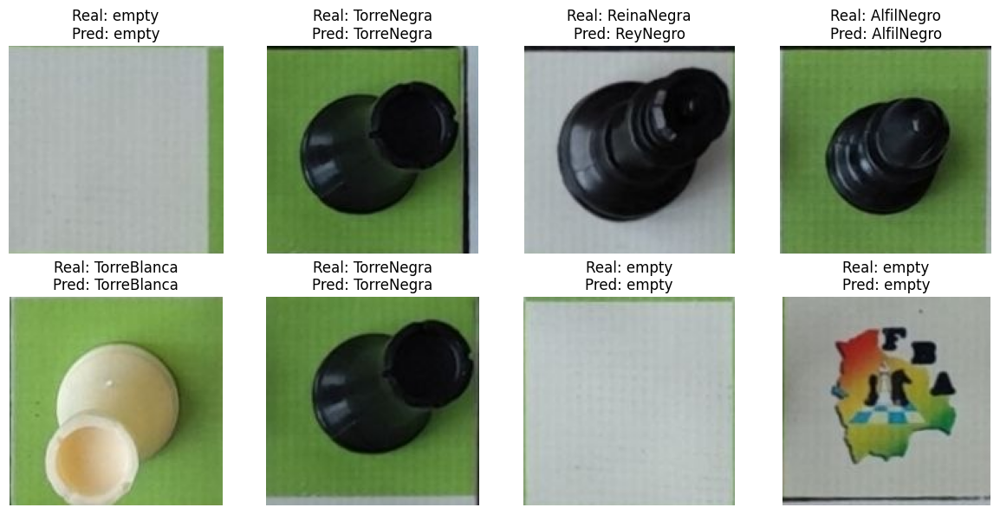

In [8]:
import random
import matplotlib.pyplot as plt
import cv2
import os
import torch

# Ruta del dataset (puede ser train o val)
dataset_path = "dataset/val"

# Obtener todas las clases
class_names = sorted(os.listdir(dataset_path))

# Obtener lista de imágenes con sus etiquetas reales
imagenes = []

for cls in class_names:
    ruta_clase = os.path.join(dataset_path, cls)
    for img_name in os.listdir(ruta_clase):
        img_path = os.path.join(ruta_clase, img_name)
        imagenes.append((img_path, cls))

# Elegir muestras aleatorias
muestras = random.sample(imagenes, 8)

fig, axes = plt.subplots(2, 4, figsize=(12,6))

for i, ax in enumerate(axes.flat):
    img_path, etiqueta_real = muestras[i]
    
    # Leer imagen
    img = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    # Predecir
    img_resized = cv2.resize(img_rgb, (64,64))
    tensor = torch.tensor(img_resized).permute(2,0,1).float()/255
    tensor = tensor.unsqueeze(0).to(device)
    
    with torch.no_grad():
        output = model(tensor)
        pred = torch.argmax(output, dim=1)
    
    etiqueta_pred = class_names[pred.item()]
    
    # Mostrar imagen
    ax.imshow(img_rgb)
    ax.set_title(f"Real: {etiqueta_real}\nPred: {etiqueta_pred}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [11]:
import numpy as np
def detectar_tablero_y_casillas(img, debug=False):
    """
    Detecta el tablero de ajedrez (8x8 casillas) y extrae cada casilla.
    Retorna las casillas y las coordenadas del tablero.
    
    Args:
        img: imagen en formato RGB
        debug: si True, muestra imágenes de depuración
    
    Returns:
        casillas: lista de 64 imágenes de casillas
        coords: tupla (x, y, x+w, y+h) del tablero detectado
    """
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    
    # CLAHE para mejorar contraste
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
    gray = clahe.apply(gray)
    
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)
    edges = cv2.Canny(blurred, 30, 100)
    
    kernel = np.ones((3, 3), np.uint8)
    edges = cv2.dilate(edges, kernel, iterations=2)
    edges = cv2.erode(edges, kernel, iterations=1)
    
    contours, _ = cv2.findContours(edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    height, width = img.shape[:2]
    area_min = (width * height) * 0.15
    area_max = (width * height) * 0.9
    
    mejores_candidatos = []
    
    for contour in contours:
        area = cv2.contourArea(contour)
        if area_min < area < area_max:
            peri = cv2.arcLength(contour, True)
            approx = cv2.approxPolyDP(contour, 0.02 * peri, True)
            
            if len(approx) == 4:
                x, y, w, h = cv2.boundingRect(approx)
                aspect_ratio = w / h
                
                if 0.7 < aspect_ratio < 1.3:
                    hull = cv2.convexHull(contour)
                    hull_area = cv2.contourArea(hull)
                    convexity = area / hull_area if hull_area > 0 else 0
                    
                    if convexity > 0.85:
                        mejores_candidatos.append((area, approx, (x, y, w, h)))
    
    mejores_candidatos.sort(key=lambda x: x[0], reverse=True)
    
    if mejores_candidatos:
        _, tablero_contour, (x, y, w, h) = mejores_candidatos[0]
        tablero = img[y:y+h, x:x+w]
        h_cell = h // 8
        w_cell = w // 8
        
        casillas = []
        for i in range(8):
            for j in range(8):
                y1 = i * h_cell
                y2 = (i + 1) * h_cell
                x1 = j * w_cell
                x2 = (j + 1) * w_cell
                casilla = tablero[y1:y2, x1:x2]
                casillas.append(casilla)
        
        return casillas, (x, y, x+w, y+h)
    
    # Fallback
    if contours:
        largest_contour = max(contours, key=cv2.contourArea)
        x, y, w, h = cv2.boundingRect(largest_contour)
        tablero = img[y:y+h, x:x+w]
    else:
        margen_x = width // 8
        margen_y = height // 8
        x, y = margen_x, margen_y
        w = width - 2 * margen_x
        h = height - 2 * margen_y
        tablero = img[y:y+h, x:x+w]
    
    h_cell = h // 8
    w_cell = w // 8
    casillas = []
    for i in range(8):
        for j in range(8):
            y1 = i * h_cell
            y2 = (i + 1) * h_cell
            x1 = j * w_cell
            x2 = (j + 1) * w_cell
            casilla = tablero[y1:y2, x1:x2]
            casillas.append(casilla)
    
    return casillas, (x, y, x+w, y+h)

Procesando 51 imágenes...



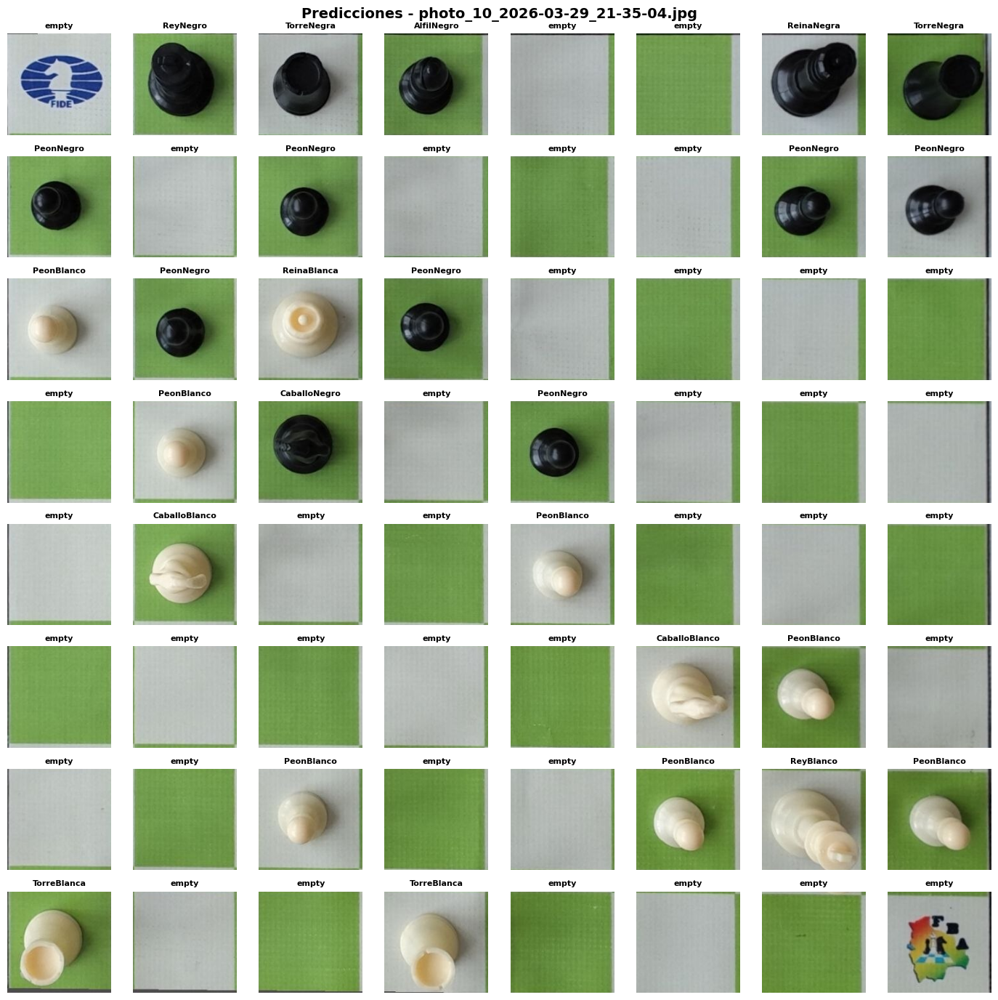


Imagen 1/51: photo_10_2026-03-29_21-35-04.jpg
Coordenadas detectadas: (0, 0) a (1280, 1250)
Tablero de predicciones (fila por fila):
Fila 0: ['empty', 'ReyNegro', 'TorreNegra', 'AlfilNegro', 'empty', 'empty', 'ReinaNegra', 'TorreNegra']
Fila 1: ['PeonNegro', 'empty', 'PeonNegro', 'empty', 'empty', 'empty', 'PeonNegro', 'PeonNegro']
Fila 2: ['PeonBlanco', 'PeonNegro', 'ReinaBlanca', 'PeonNegro', 'empty', 'empty', 'empty', 'empty']
Fila 3: ['empty', 'PeonBlanco', 'CaballoNegro', 'empty', 'PeonNegro', 'empty', 'empty', 'empty']
Fila 4: ['empty', 'CaballoBlanco', 'empty', 'empty', 'PeonBlanco', 'empty', 'empty', 'empty']
Fila 5: ['empty', 'empty', 'empty', 'empty', 'empty', 'CaballoBlanco', 'PeonBlanco', 'empty']
Fila 6: ['empty', 'empty', 'PeonBlanco', 'empty', 'empty', 'PeonBlanco', 'ReyBlanco', 'PeonBlanco']
Fila 7: ['TorreBlanca', 'empty', 'empty', 'TorreBlanca', 'empty', 'empty', 'empty', 'empty']



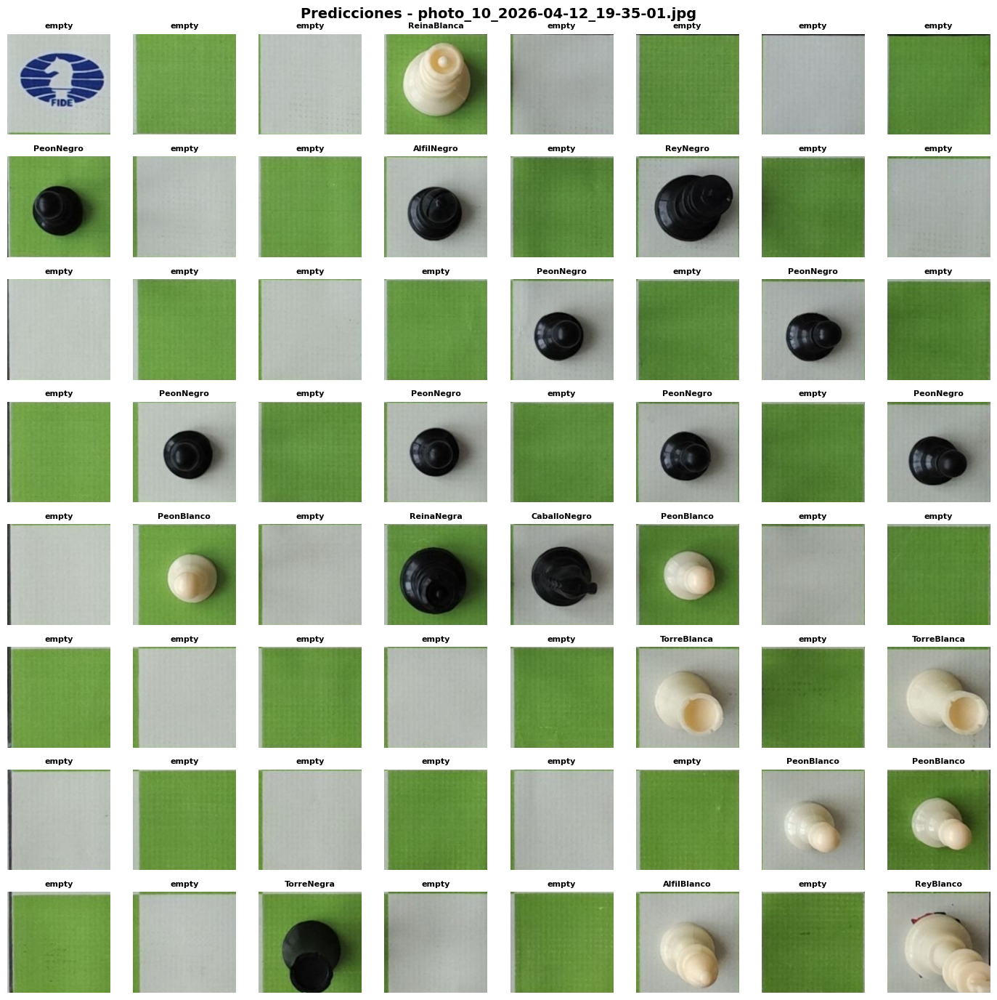


Imagen 2/51: photo_10_2026-04-12_19-35-01.jpg
Coordenadas detectadas: (0, 0) a (1280, 1263)
Tablero de predicciones (fila por fila):
Fila 0: ['empty', 'empty', 'empty', 'ReinaBlanca', 'empty', 'empty', 'empty', 'empty']
Fila 1: ['PeonNegro', 'empty', 'empty', 'AlfilNegro', 'empty', 'ReyNegro', 'empty', 'empty']
Fila 2: ['empty', 'empty', 'empty', 'empty', 'PeonNegro', 'empty', 'PeonNegro', 'empty']
Fila 3: ['empty', 'PeonNegro', 'empty', 'PeonNegro', 'empty', 'PeonNegro', 'empty', 'PeonNegro']
Fila 4: ['empty', 'PeonBlanco', 'empty', 'ReinaNegra', 'CaballoNegro', 'PeonBlanco', 'empty', 'empty']
Fila 5: ['empty', 'empty', 'empty', 'empty', 'empty', 'TorreBlanca', 'empty', 'TorreBlanca']
Fila 6: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'PeonBlanco', 'PeonBlanco']
Fila 7: ['empty', 'empty', 'TorreNegra', 'empty', 'empty', 'AlfilBlanco', 'empty', 'ReyBlanco']



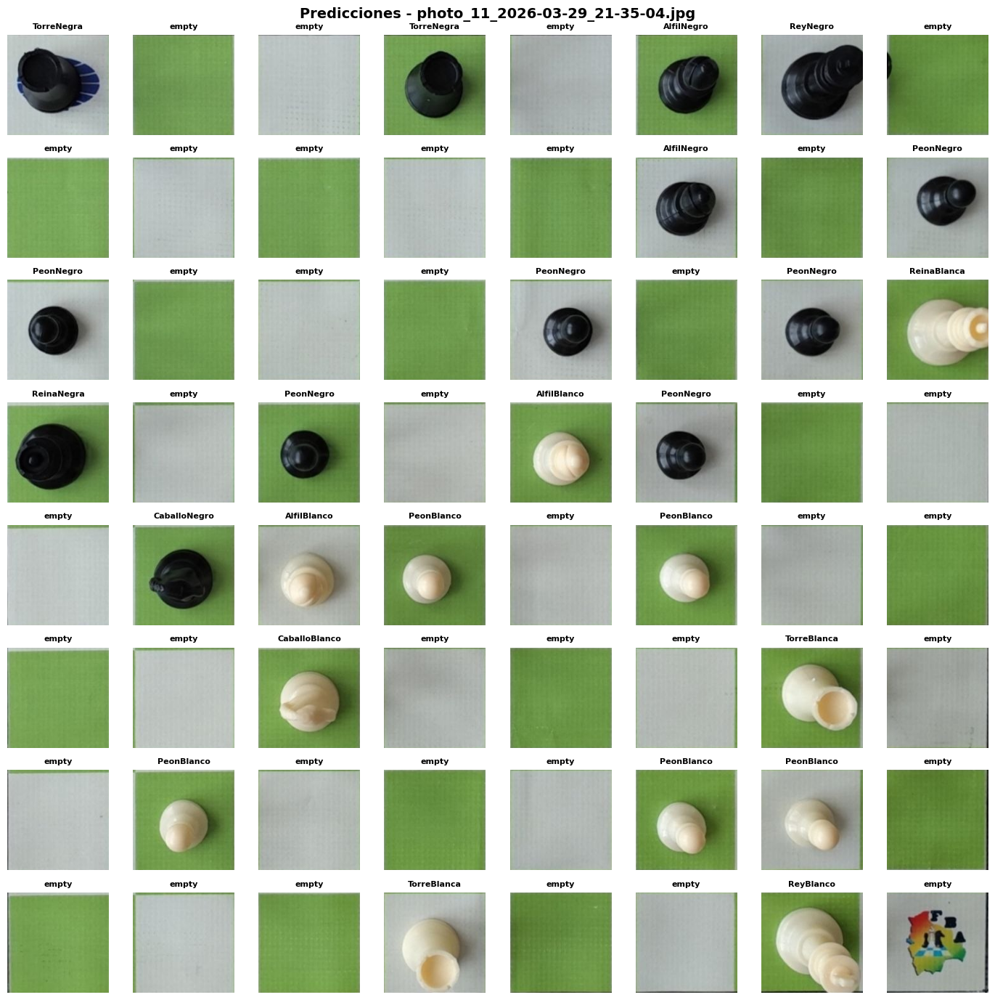


Imagen 3/51: photo_11_2026-03-29_21-35-04.jpg
Coordenadas detectadas: (0, 0) a (1280, 1267)
Tablero de predicciones (fila por fila):
Fila 0: ['TorreNegra', 'empty', 'empty', 'TorreNegra', 'empty', 'AlfilNegro', 'ReyNegro', 'empty']
Fila 1: ['empty', 'empty', 'empty', 'empty', 'empty', 'AlfilNegro', 'empty', 'PeonNegro']
Fila 2: ['PeonNegro', 'empty', 'empty', 'empty', 'PeonNegro', 'empty', 'PeonNegro', 'ReinaBlanca']
Fila 3: ['ReinaNegra', 'empty', 'PeonNegro', 'empty', 'AlfilBlanco', 'PeonNegro', 'empty', 'empty']
Fila 4: ['empty', 'CaballoNegro', 'AlfilBlanco', 'PeonBlanco', 'empty', 'PeonBlanco', 'empty', 'empty']
Fila 5: ['empty', 'empty', 'CaballoBlanco', 'empty', 'empty', 'empty', 'TorreBlanca', 'empty']
Fila 6: ['empty', 'PeonBlanco', 'empty', 'empty', 'empty', 'PeonBlanco', 'PeonBlanco', 'empty']
Fila 7: ['empty', 'empty', 'empty', 'TorreBlanca', 'empty', 'empty', 'ReyBlanco', 'empty']



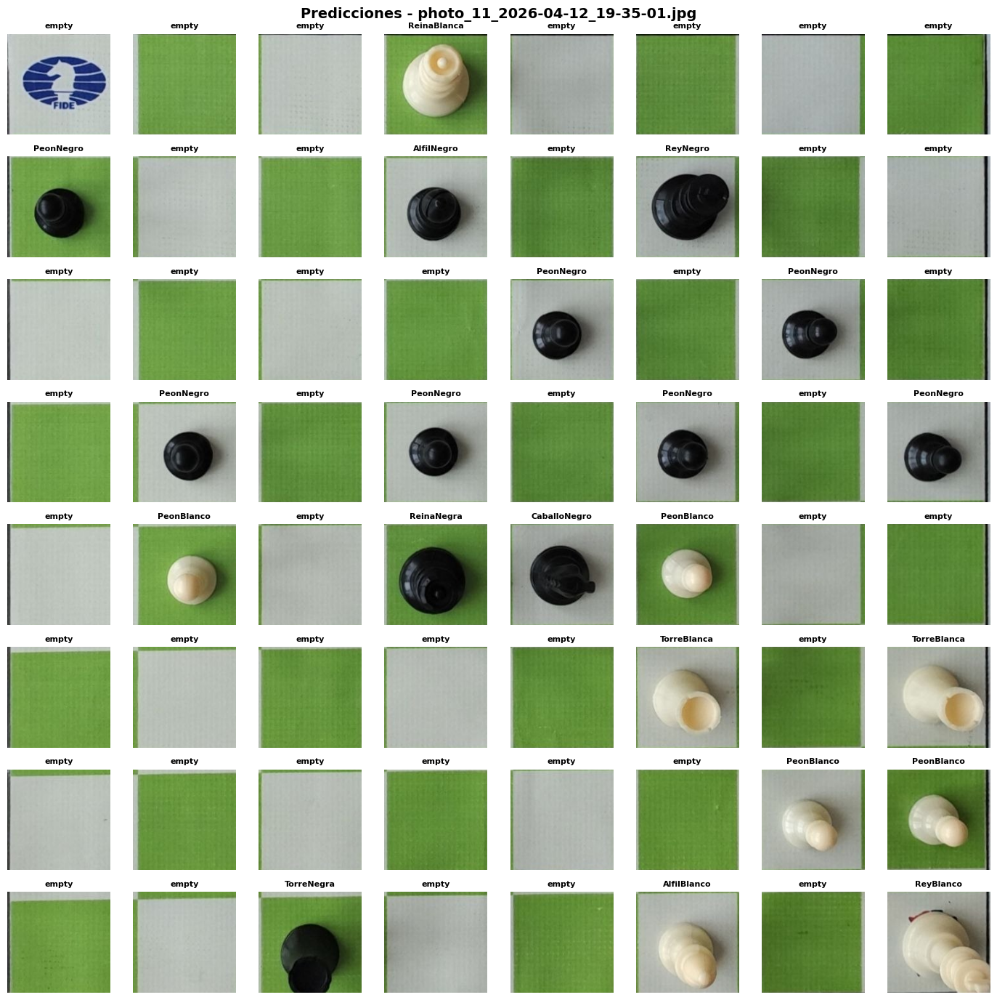


Imagen 4/51: photo_11_2026-04-12_19-35-01.jpg
Coordenadas detectadas: (0, 0) a (1280, 1262)
Tablero de predicciones (fila por fila):
Fila 0: ['empty', 'empty', 'empty', 'ReinaBlanca', 'empty', 'empty', 'empty', 'empty']
Fila 1: ['PeonNegro', 'empty', 'empty', 'AlfilNegro', 'empty', 'ReyNegro', 'empty', 'empty']
Fila 2: ['empty', 'empty', 'empty', 'empty', 'PeonNegro', 'empty', 'PeonNegro', 'empty']
Fila 3: ['empty', 'PeonNegro', 'empty', 'PeonNegro', 'empty', 'PeonNegro', 'empty', 'PeonNegro']
Fila 4: ['empty', 'PeonBlanco', 'empty', 'ReinaNegra', 'CaballoNegro', 'PeonBlanco', 'empty', 'empty']
Fila 5: ['empty', 'empty', 'empty', 'empty', 'empty', 'TorreBlanca', 'empty', 'TorreBlanca']
Fila 6: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'PeonBlanco', 'PeonBlanco']
Fila 7: ['empty', 'empty', 'TorreNegra', 'empty', 'empty', 'AlfilBlanco', 'empty', 'ReyBlanco']



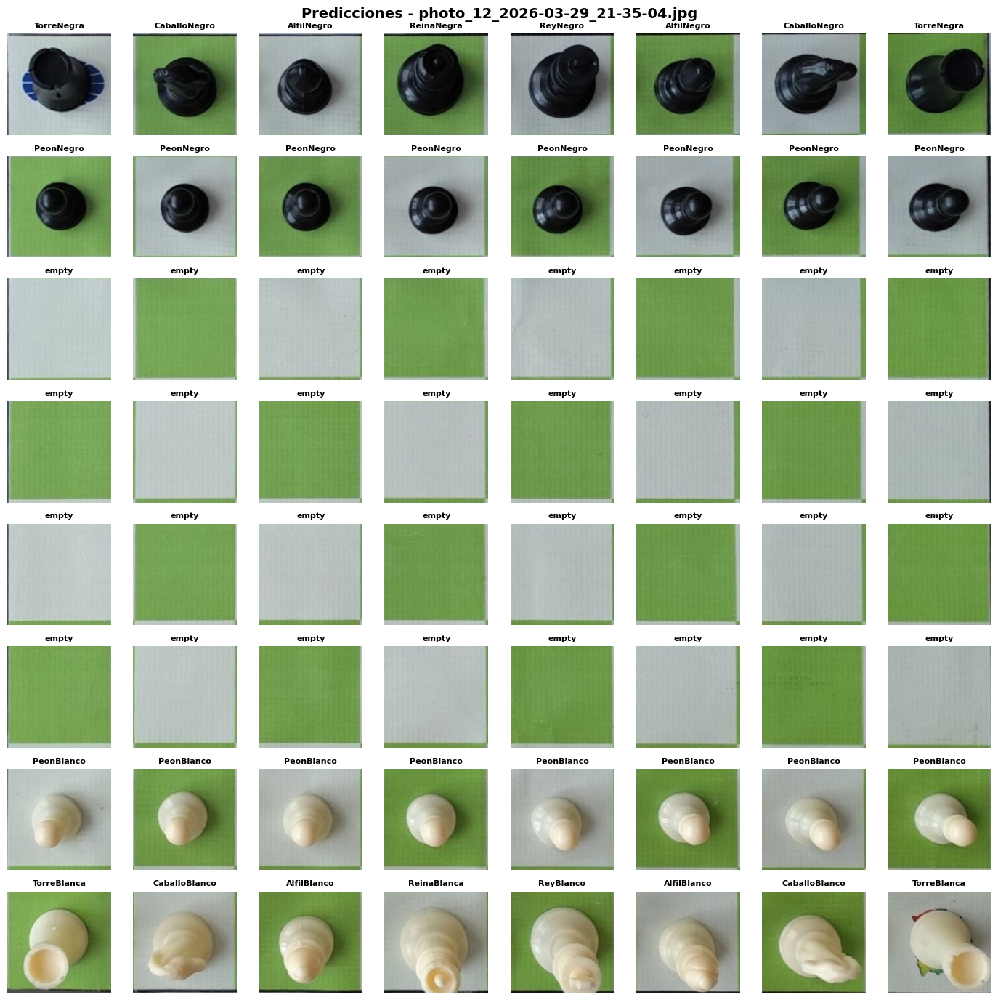


Imagen 5/51: photo_12_2026-03-29_21-35-04.jpg
Coordenadas detectadas: (0, 0) a (1280, 1252)
Tablero de predicciones (fila por fila):
Fila 0: ['TorreNegra', 'CaballoNegro', 'AlfilNegro', 'ReinaNegra', 'ReyNegro', 'AlfilNegro', 'CaballoNegro', 'TorreNegra']
Fila 1: ['PeonNegro', 'PeonNegro', 'PeonNegro', 'PeonNegro', 'PeonNegro', 'PeonNegro', 'PeonNegro', 'PeonNegro']
Fila 2: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 3: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 4: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 5: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 6: ['PeonBlanco', 'PeonBlanco', 'PeonBlanco', 'PeonBlanco', 'PeonBlanco', 'PeonBlanco', 'PeonBlanco', 'PeonBlanco']
Fila 7: ['TorreBlanca', 'CaballoBlanco', 'AlfilBlanco', 'ReinaBlanca', 'ReyBlanco', 'AlfilBlanco', 'CaballoBlanco', 'TorreBlanca']



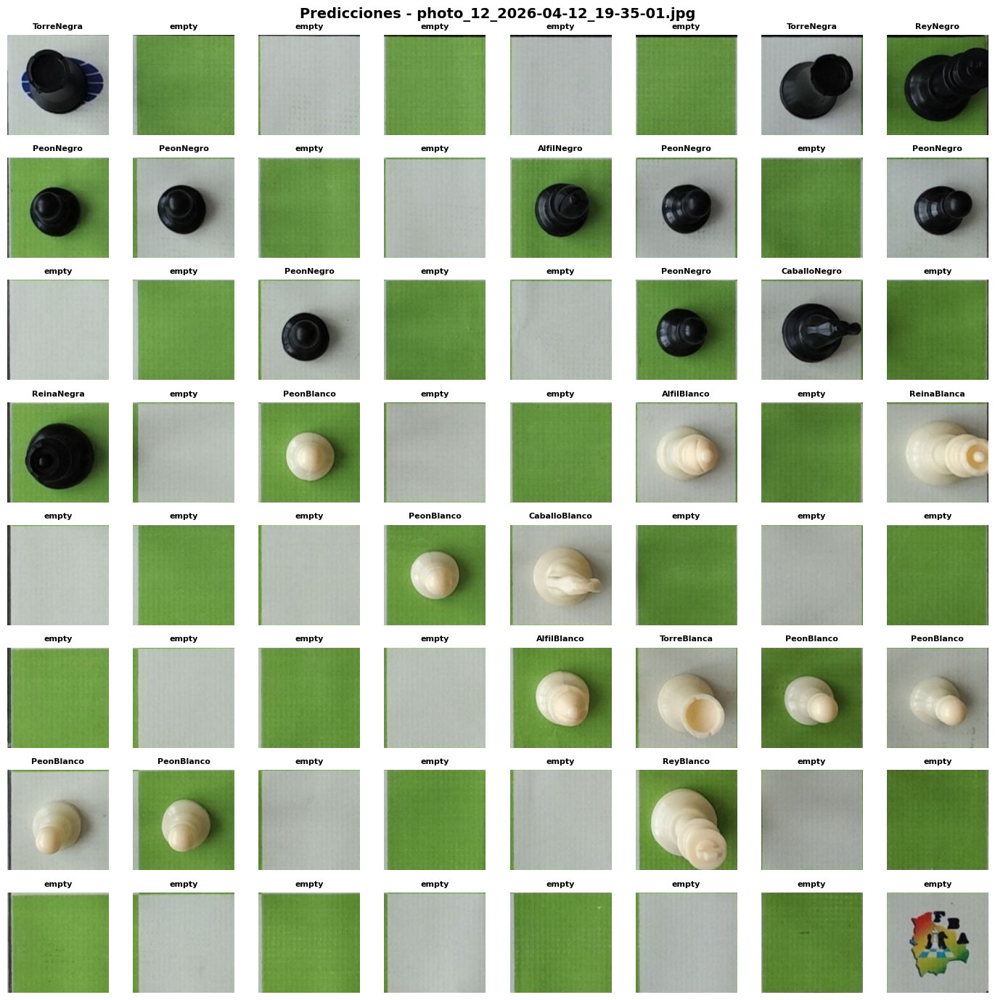


Imagen 6/51: photo_12_2026-04-12_19-35-01.jpg
Coordenadas detectadas: (0, 0) a (1280, 1271)
Tablero de predicciones (fila por fila):
Fila 0: ['TorreNegra', 'empty', 'empty', 'empty', 'empty', 'empty', 'TorreNegra', 'ReyNegro']
Fila 1: ['PeonNegro', 'PeonNegro', 'empty', 'empty', 'AlfilNegro', 'PeonNegro', 'empty', 'PeonNegro']
Fila 2: ['empty', 'empty', 'PeonNegro', 'empty', 'empty', 'PeonNegro', 'CaballoNegro', 'empty']
Fila 3: ['ReinaNegra', 'empty', 'PeonBlanco', 'empty', 'empty', 'AlfilBlanco', 'empty', 'ReinaBlanca']
Fila 4: ['empty', 'empty', 'empty', 'PeonBlanco', 'CaballoBlanco', 'empty', 'empty', 'empty']
Fila 5: ['empty', 'empty', 'empty', 'empty', 'AlfilBlanco', 'TorreBlanca', 'PeonBlanco', 'PeonBlanco']
Fila 6: ['PeonBlanco', 'PeonBlanco', 'empty', 'empty', 'empty', 'ReyBlanco', 'empty', 'empty']
Fila 7: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']



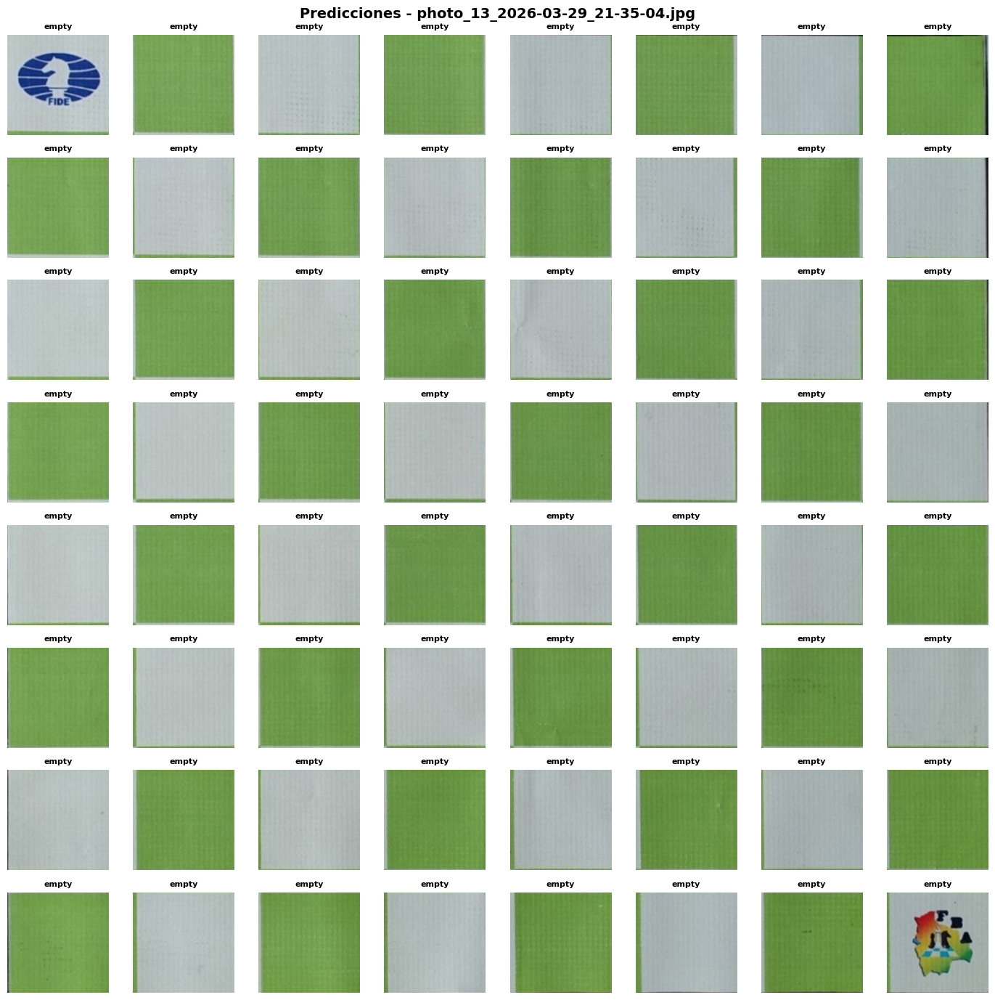


Imagen 7/51: photo_13_2026-03-29_21-35-04.jpg
Coordenadas detectadas: (0, 0) a (1280, 1265)
Tablero de predicciones (fila por fila):
Fila 0: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 1: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 2: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 3: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 4: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 5: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 6: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 7: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']



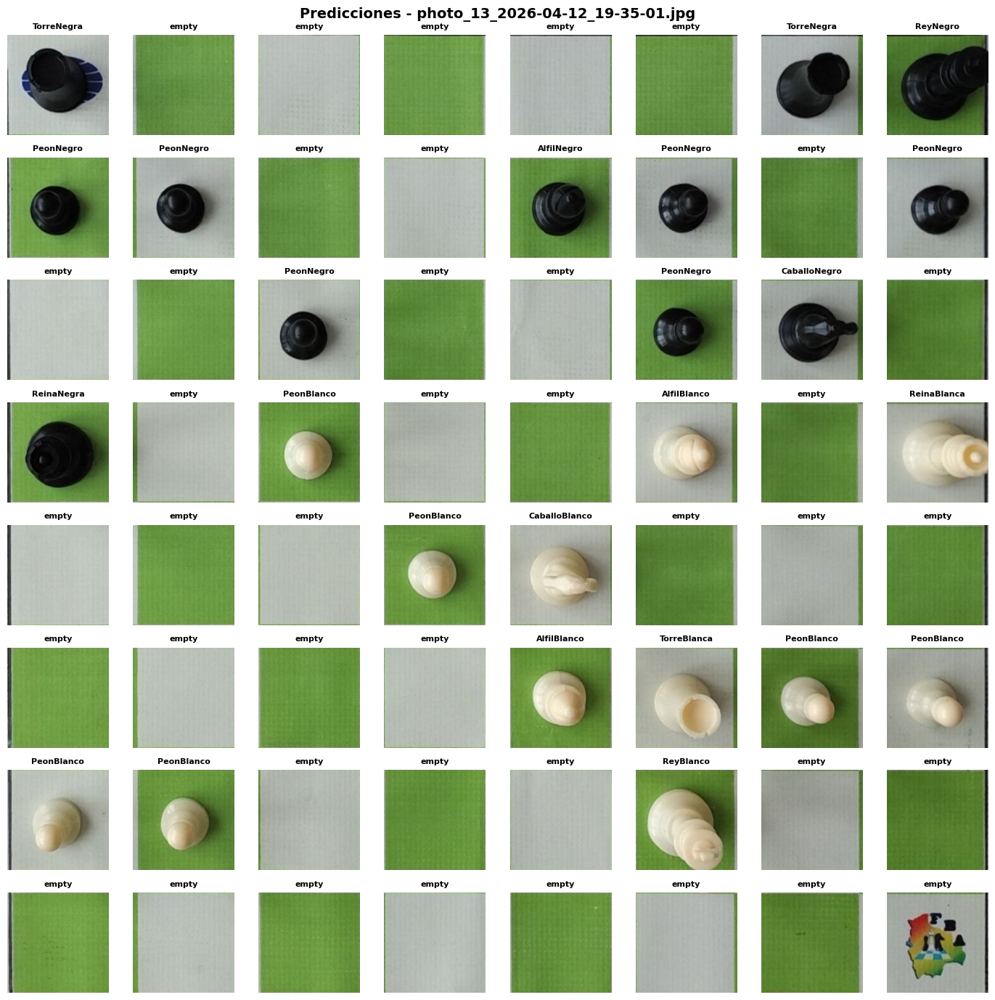


Imagen 8/51: photo_13_2026-04-12_19-35-01.jpg
Coordenadas detectadas: (0, 0) a (1280, 1266)
Tablero de predicciones (fila por fila):
Fila 0: ['TorreNegra', 'empty', 'empty', 'empty', 'empty', 'empty', 'TorreNegra', 'ReyNegro']
Fila 1: ['PeonNegro', 'PeonNegro', 'empty', 'empty', 'AlfilNegro', 'PeonNegro', 'empty', 'PeonNegro']
Fila 2: ['empty', 'empty', 'PeonNegro', 'empty', 'empty', 'PeonNegro', 'CaballoNegro', 'empty']
Fila 3: ['ReinaNegra', 'empty', 'PeonBlanco', 'empty', 'empty', 'AlfilBlanco', 'empty', 'ReinaBlanca']
Fila 4: ['empty', 'empty', 'empty', 'PeonBlanco', 'CaballoBlanco', 'empty', 'empty', 'empty']
Fila 5: ['empty', 'empty', 'empty', 'empty', 'AlfilBlanco', 'TorreBlanca', 'PeonBlanco', 'PeonBlanco']
Fila 6: ['PeonBlanco', 'PeonBlanco', 'empty', 'empty', 'empty', 'ReyBlanco', 'empty', 'empty']
Fila 7: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']



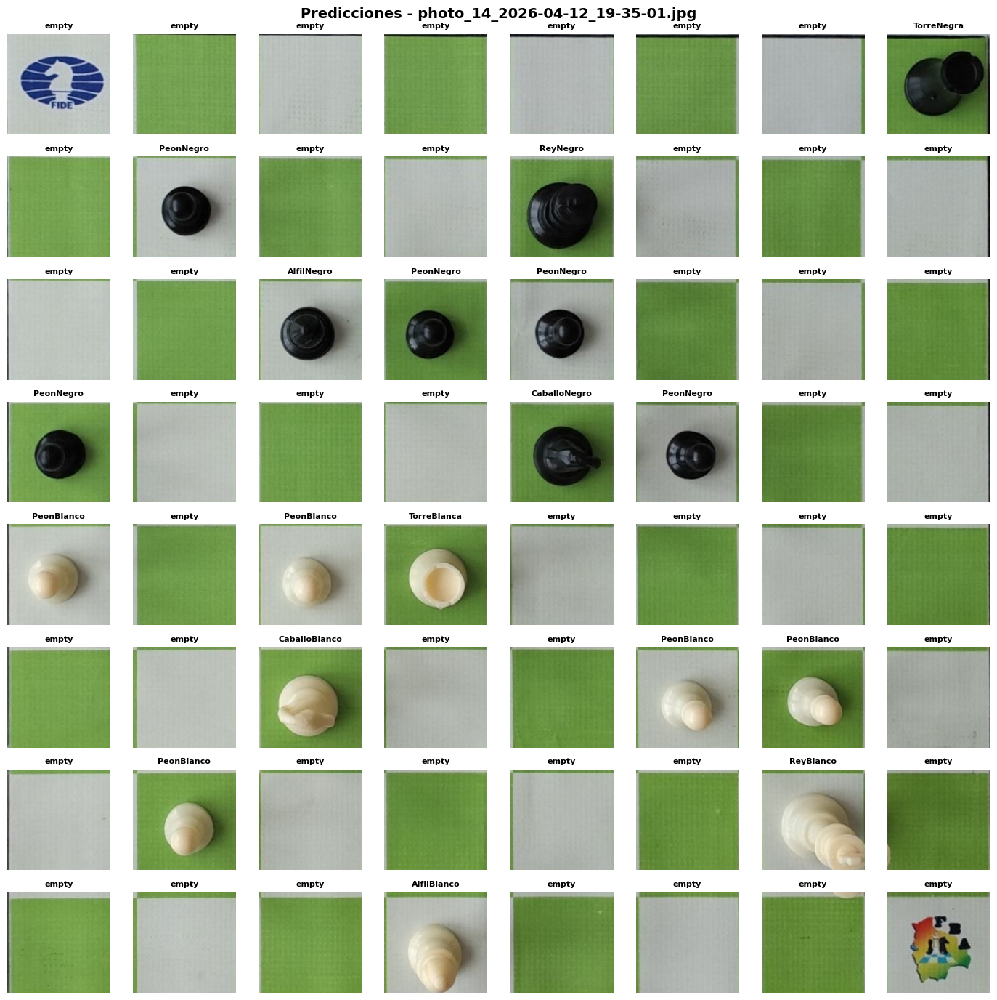


Imagen 9/51: photo_14_2026-04-12_19-35-01.jpg
Coordenadas detectadas: (0, 0) a (1280, 1262)
Tablero de predicciones (fila por fila):
Fila 0: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'TorreNegra']
Fila 1: ['empty', 'PeonNegro', 'empty', 'empty', 'ReyNegro', 'empty', 'empty', 'empty']
Fila 2: ['empty', 'empty', 'AlfilNegro', 'PeonNegro', 'PeonNegro', 'empty', 'empty', 'empty']
Fila 3: ['PeonNegro', 'empty', 'empty', 'empty', 'CaballoNegro', 'PeonNegro', 'empty', 'empty']
Fila 4: ['PeonBlanco', 'empty', 'PeonBlanco', 'TorreBlanca', 'empty', 'empty', 'empty', 'empty']
Fila 5: ['empty', 'empty', 'CaballoBlanco', 'empty', 'empty', 'PeonBlanco', 'PeonBlanco', 'empty']
Fila 6: ['empty', 'PeonBlanco', 'empty', 'empty', 'empty', 'empty', 'ReyBlanco', 'empty']
Fila 7: ['empty', 'empty', 'empty', 'AlfilBlanco', 'empty', 'empty', 'empty', 'empty']



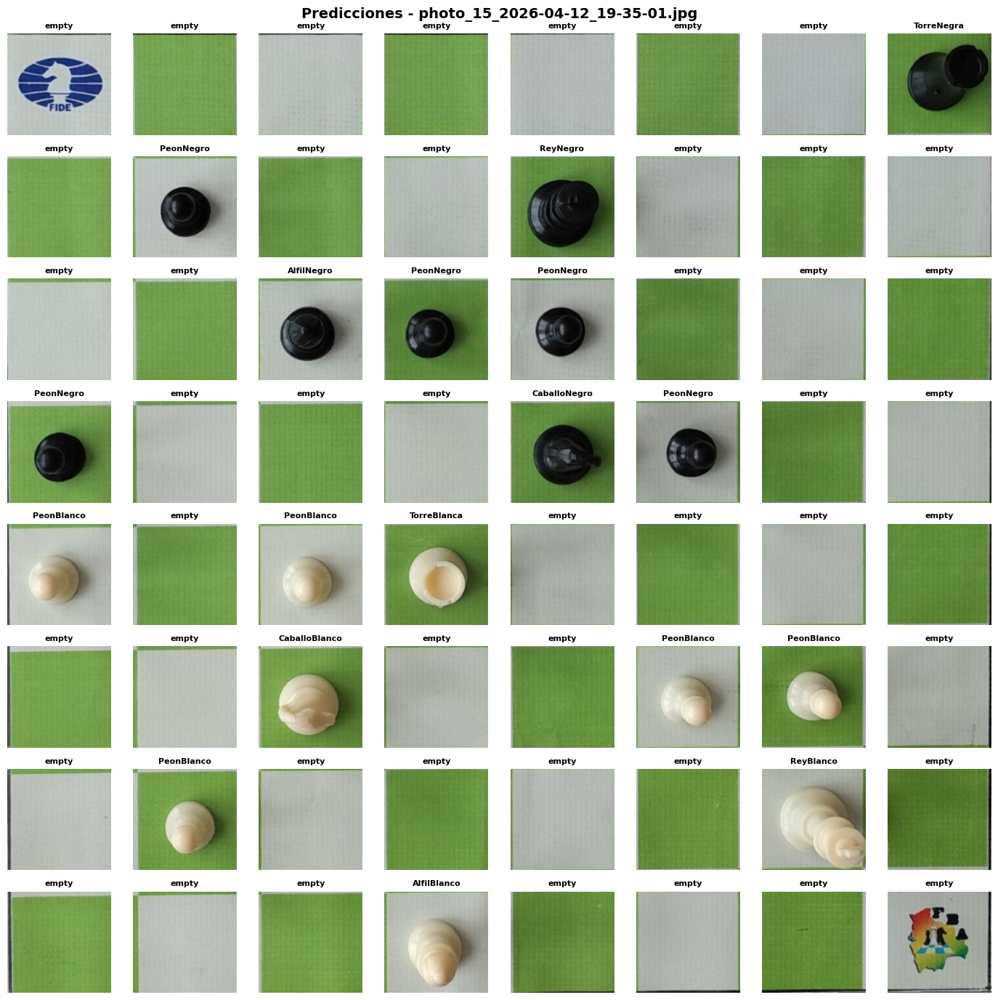


Imagen 10/51: photo_15_2026-04-12_19-35-01.jpg
Coordenadas detectadas: (0, 0) a (1280, 1253)
Tablero de predicciones (fila por fila):
Fila 0: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'TorreNegra']
Fila 1: ['empty', 'PeonNegro', 'empty', 'empty', 'ReyNegro', 'empty', 'empty', 'empty']
Fila 2: ['empty', 'empty', 'AlfilNegro', 'PeonNegro', 'PeonNegro', 'empty', 'empty', 'empty']
Fila 3: ['PeonNegro', 'empty', 'empty', 'empty', 'CaballoNegro', 'PeonNegro', 'empty', 'empty']
Fila 4: ['PeonBlanco', 'empty', 'PeonBlanco', 'TorreBlanca', 'empty', 'empty', 'empty', 'empty']
Fila 5: ['empty', 'empty', 'CaballoBlanco', 'empty', 'empty', 'PeonBlanco', 'PeonBlanco', 'empty']
Fila 6: ['empty', 'PeonBlanco', 'empty', 'empty', 'empty', 'empty', 'ReyBlanco', 'empty']
Fila 7: ['empty', 'empty', 'empty', 'AlfilBlanco', 'empty', 'empty', 'empty', 'empty']



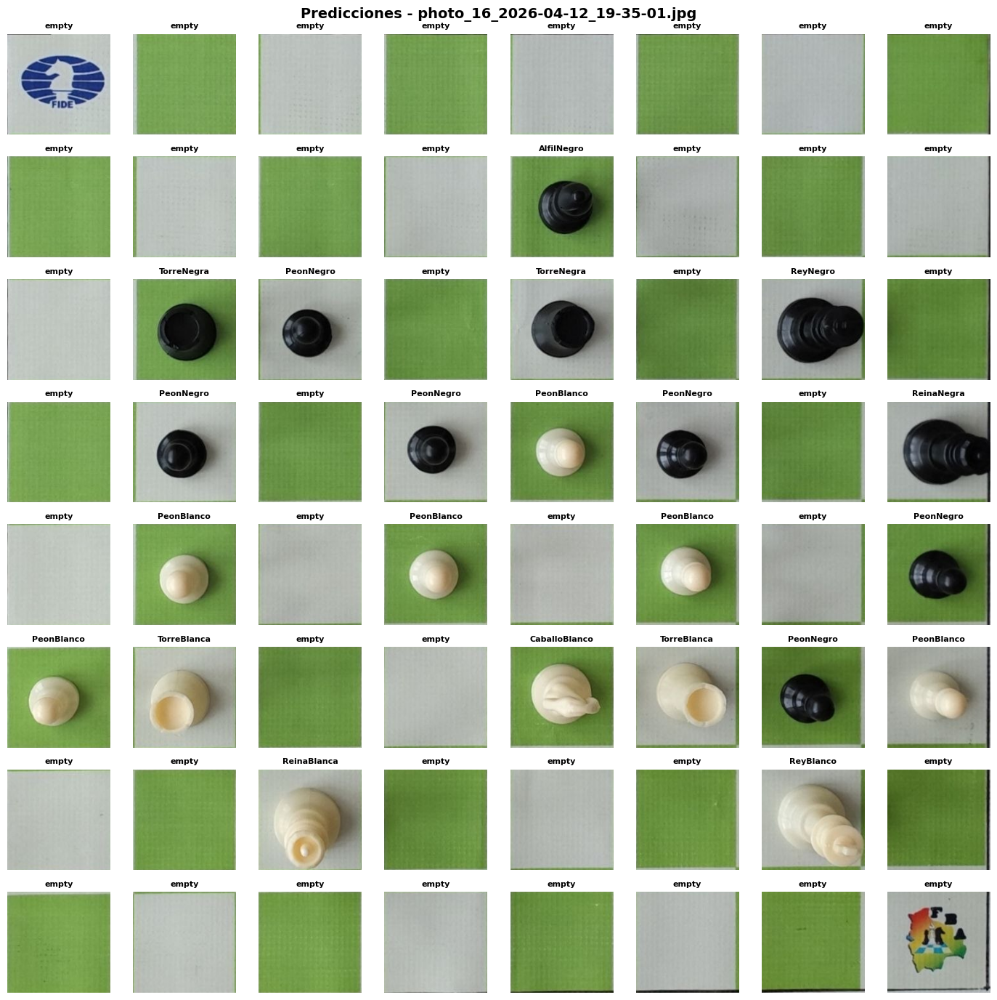


Imagen 11/51: photo_16_2026-04-12_19-35-01.jpg
Coordenadas detectadas: (0, 0) a (1280, 1258)
Tablero de predicciones (fila por fila):
Fila 0: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 1: ['empty', 'empty', 'empty', 'empty', 'AlfilNegro', 'empty', 'empty', 'empty']
Fila 2: ['empty', 'TorreNegra', 'PeonNegro', 'empty', 'TorreNegra', 'empty', 'ReyNegro', 'empty']
Fila 3: ['empty', 'PeonNegro', 'empty', 'PeonNegro', 'PeonBlanco', 'PeonNegro', 'empty', 'ReinaNegra']
Fila 4: ['empty', 'PeonBlanco', 'empty', 'PeonBlanco', 'empty', 'PeonBlanco', 'empty', 'PeonNegro']
Fila 5: ['PeonBlanco', 'TorreBlanca', 'empty', 'empty', 'CaballoBlanco', 'TorreBlanca', 'PeonNegro', 'PeonBlanco']
Fila 6: ['empty', 'empty', 'ReinaBlanca', 'empty', 'empty', 'empty', 'ReyBlanco', 'empty']
Fila 7: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']



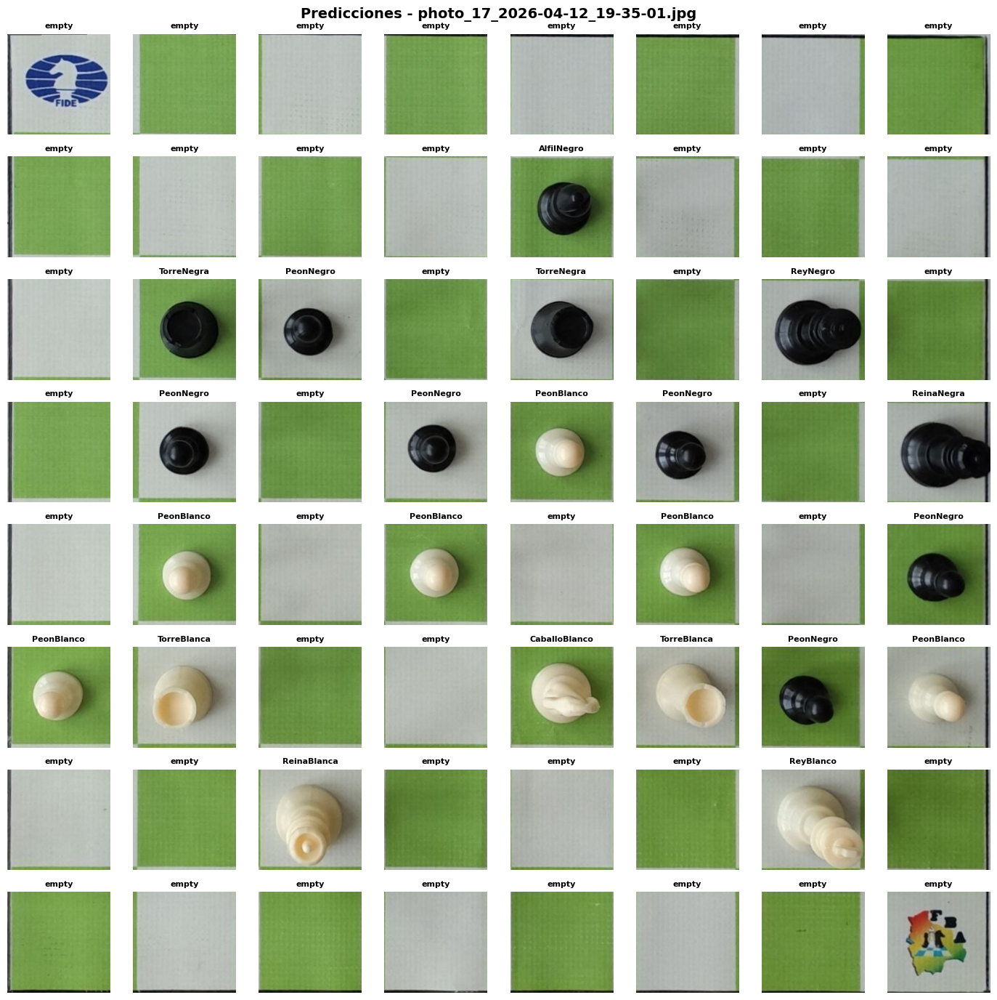


Imagen 12/51: photo_17_2026-04-12_19-35-01.jpg
Coordenadas detectadas: (0, 0) a (1280, 1256)
Tablero de predicciones (fila por fila):
Fila 0: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 1: ['empty', 'empty', 'empty', 'empty', 'AlfilNegro', 'empty', 'empty', 'empty']
Fila 2: ['empty', 'TorreNegra', 'PeonNegro', 'empty', 'TorreNegra', 'empty', 'ReyNegro', 'empty']
Fila 3: ['empty', 'PeonNegro', 'empty', 'PeonNegro', 'PeonBlanco', 'PeonNegro', 'empty', 'ReinaNegra']
Fila 4: ['empty', 'PeonBlanco', 'empty', 'PeonBlanco', 'empty', 'PeonBlanco', 'empty', 'PeonNegro']
Fila 5: ['PeonBlanco', 'TorreBlanca', 'empty', 'empty', 'CaballoBlanco', 'TorreBlanca', 'PeonNegro', 'PeonBlanco']
Fila 6: ['empty', 'empty', 'ReinaBlanca', 'empty', 'empty', 'empty', 'ReyBlanco', 'empty']
Fila 7: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']



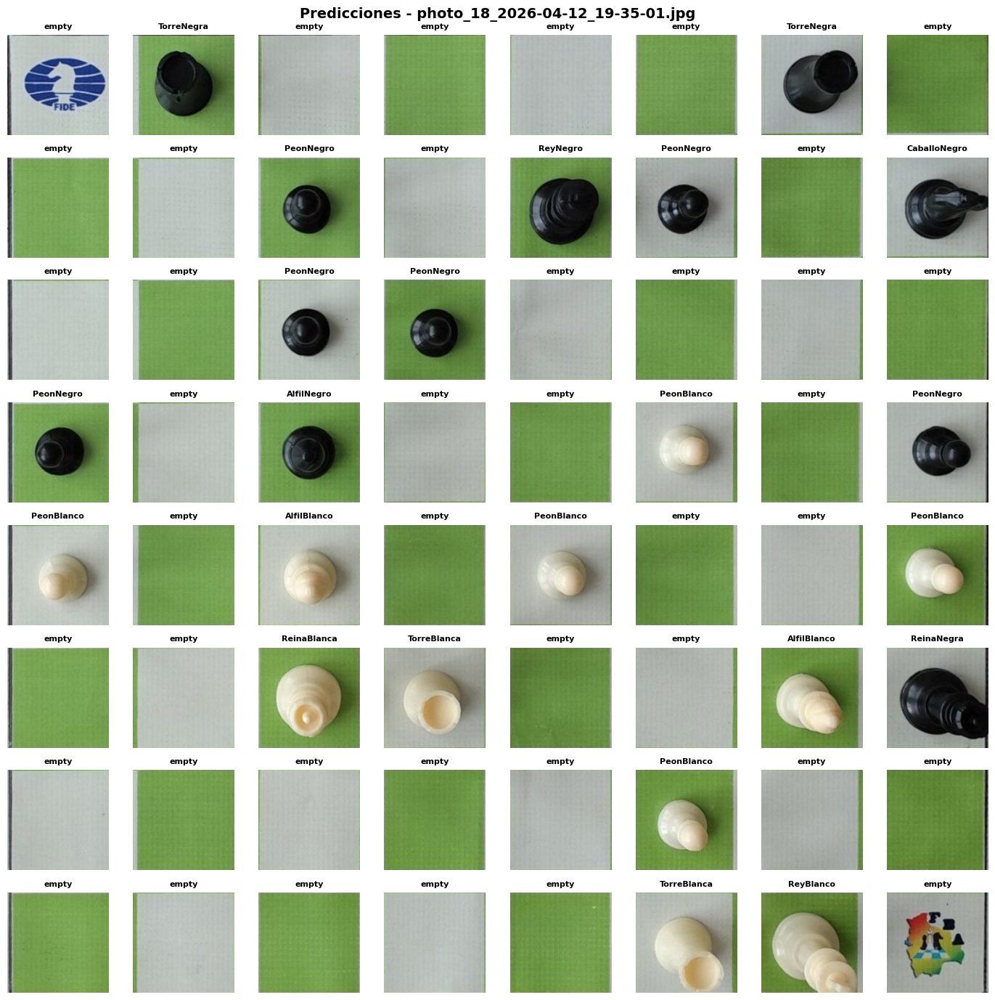


Imagen 13/51: photo_18_2026-04-12_19-35-01.jpg
Coordenadas detectadas: (0, 0) a (1280, 1271)
Tablero de predicciones (fila por fila):
Fila 0: ['empty', 'TorreNegra', 'empty', 'empty', 'empty', 'empty', 'TorreNegra', 'empty']
Fila 1: ['empty', 'empty', 'PeonNegro', 'empty', 'ReyNegro', 'PeonNegro', 'empty', 'CaballoNegro']
Fila 2: ['empty', 'empty', 'PeonNegro', 'PeonNegro', 'empty', 'empty', 'empty', 'empty']
Fila 3: ['PeonNegro', 'empty', 'AlfilNegro', 'empty', 'empty', 'PeonBlanco', 'empty', 'PeonNegro']
Fila 4: ['PeonBlanco', 'empty', 'AlfilBlanco', 'empty', 'PeonBlanco', 'empty', 'empty', 'PeonBlanco']
Fila 5: ['empty', 'empty', 'ReinaBlanca', 'TorreBlanca', 'empty', 'empty', 'AlfilBlanco', 'ReinaNegra']
Fila 6: ['empty', 'empty', 'empty', 'empty', 'empty', 'PeonBlanco', 'empty', 'empty']
Fila 7: ['empty', 'empty', 'empty', 'empty', 'empty', 'TorreBlanca', 'ReyBlanco', 'empty']



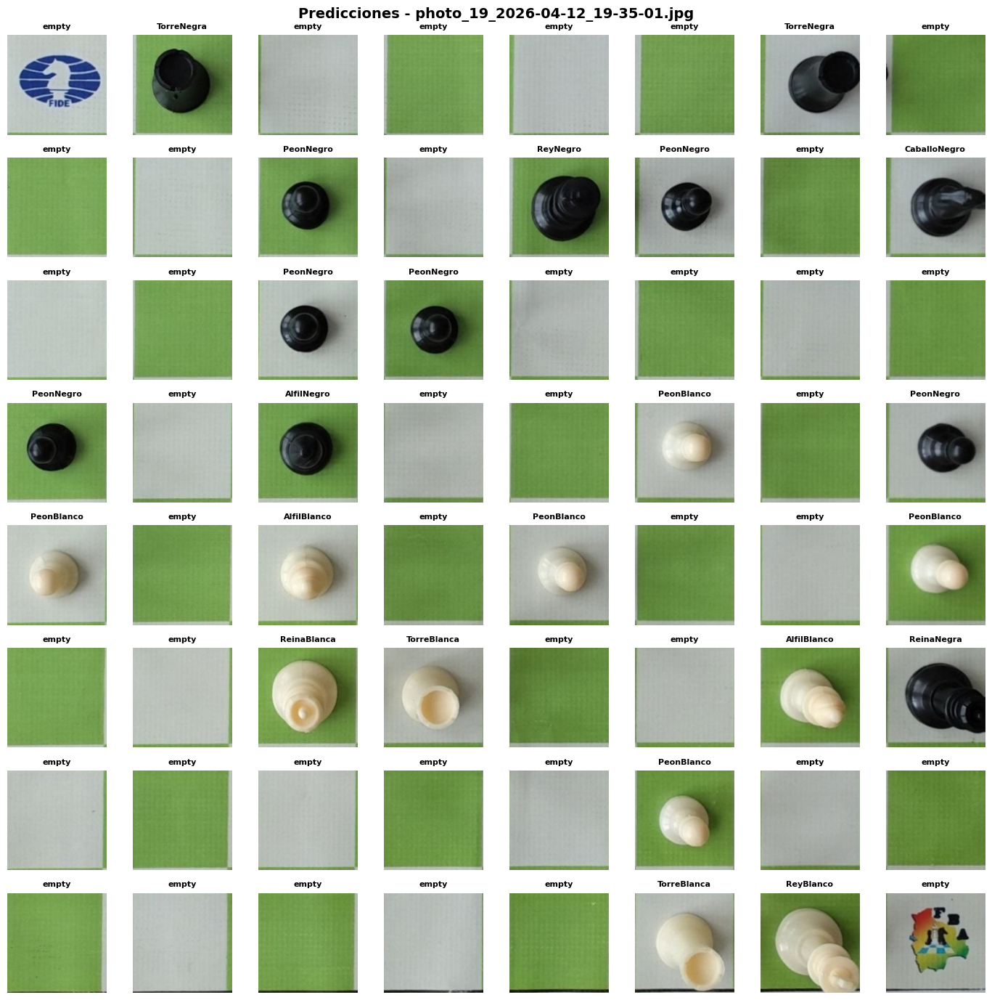


Imagen 14/51: photo_19_2026-04-12_19-35-01.jpg
Coordenadas detectadas: (0, 0) a (1278, 1280)
Tablero de predicciones (fila por fila):
Fila 0: ['empty', 'TorreNegra', 'empty', 'empty', 'empty', 'empty', 'TorreNegra', 'empty']
Fila 1: ['empty', 'empty', 'PeonNegro', 'empty', 'ReyNegro', 'PeonNegro', 'empty', 'CaballoNegro']
Fila 2: ['empty', 'empty', 'PeonNegro', 'PeonNegro', 'empty', 'empty', 'empty', 'empty']
Fila 3: ['PeonNegro', 'empty', 'AlfilNegro', 'empty', 'empty', 'PeonBlanco', 'empty', 'PeonNegro']
Fila 4: ['PeonBlanco', 'empty', 'AlfilBlanco', 'empty', 'PeonBlanco', 'empty', 'empty', 'PeonBlanco']
Fila 5: ['empty', 'empty', 'ReinaBlanca', 'TorreBlanca', 'empty', 'empty', 'AlfilBlanco', 'ReinaNegra']
Fila 6: ['empty', 'empty', 'empty', 'empty', 'empty', 'PeonBlanco', 'empty', 'empty']
Fila 7: ['empty', 'empty', 'empty', 'empty', 'empty', 'TorreBlanca', 'ReyBlanco', 'empty']



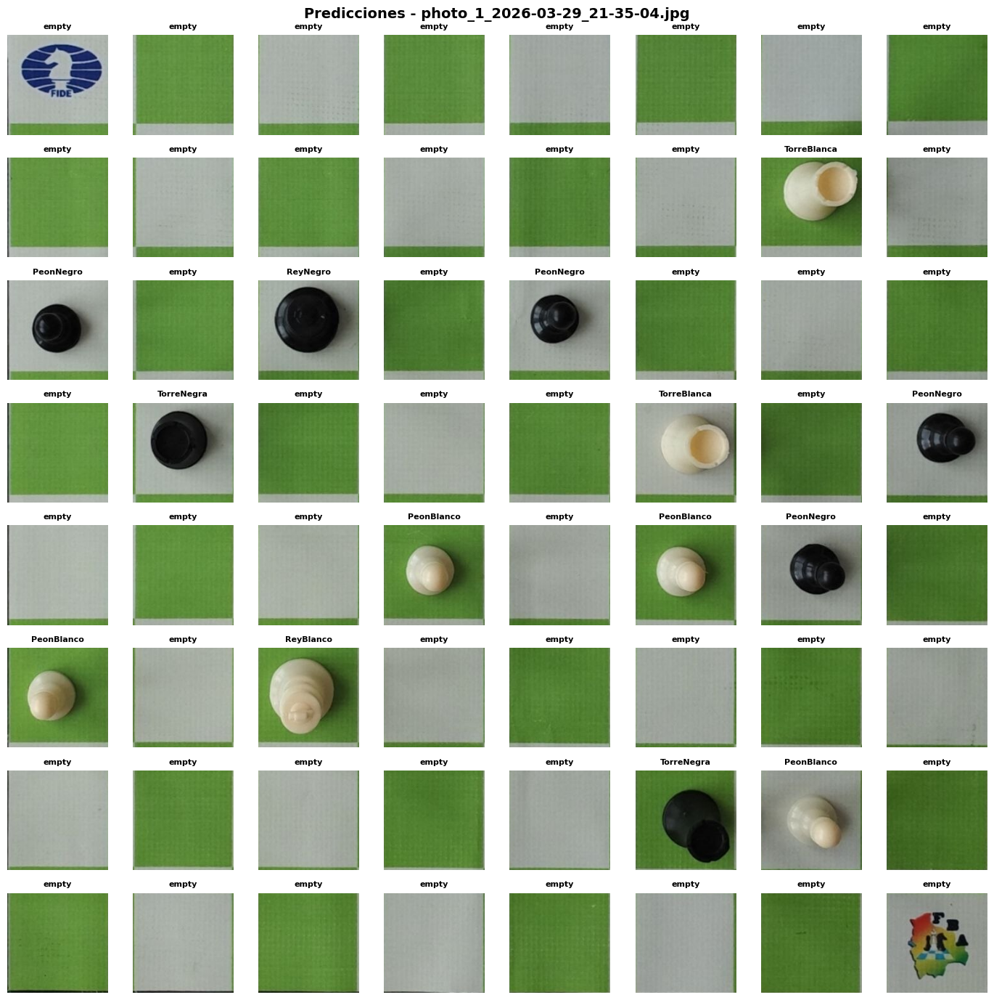


Imagen 15/51: photo_1_2026-03-29_21-35-04.jpg
Coordenadas detectadas: (0, 18) a (1271, 1277)
Tablero de predicciones (fila por fila):
Fila 0: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 1: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'TorreBlanca', 'empty']
Fila 2: ['PeonNegro', 'empty', 'ReyNegro', 'empty', 'PeonNegro', 'empty', 'empty', 'empty']
Fila 3: ['empty', 'TorreNegra', 'empty', 'empty', 'empty', 'TorreBlanca', 'empty', 'PeonNegro']
Fila 4: ['empty', 'empty', 'empty', 'PeonBlanco', 'empty', 'PeonBlanco', 'PeonNegro', 'empty']
Fila 5: ['PeonBlanco', 'empty', 'ReyBlanco', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 6: ['empty', 'empty', 'empty', 'empty', 'empty', 'TorreNegra', 'PeonBlanco', 'empty']
Fila 7: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']



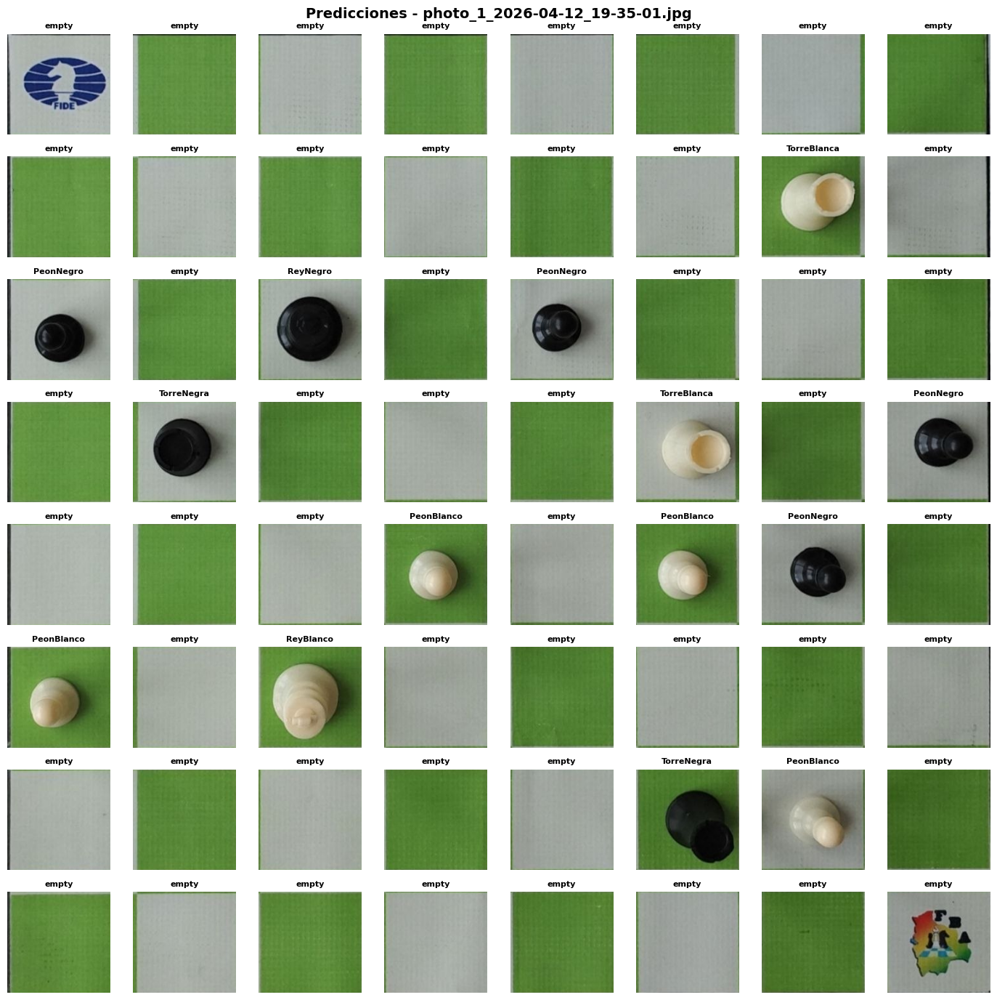


Imagen 16/51: photo_1_2026-04-12_19-35-01.jpg
Coordenadas detectadas: (0, 0) a (1280, 1263)
Tablero de predicciones (fila por fila):
Fila 0: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 1: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'TorreBlanca', 'empty']
Fila 2: ['PeonNegro', 'empty', 'ReyNegro', 'empty', 'PeonNegro', 'empty', 'empty', 'empty']
Fila 3: ['empty', 'TorreNegra', 'empty', 'empty', 'empty', 'TorreBlanca', 'empty', 'PeonNegro']
Fila 4: ['empty', 'empty', 'empty', 'PeonBlanco', 'empty', 'PeonBlanco', 'PeonNegro', 'empty']
Fila 5: ['PeonBlanco', 'empty', 'ReyBlanco', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 6: ['empty', 'empty', 'empty', 'empty', 'empty', 'TorreNegra', 'PeonBlanco', 'empty']
Fila 7: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']



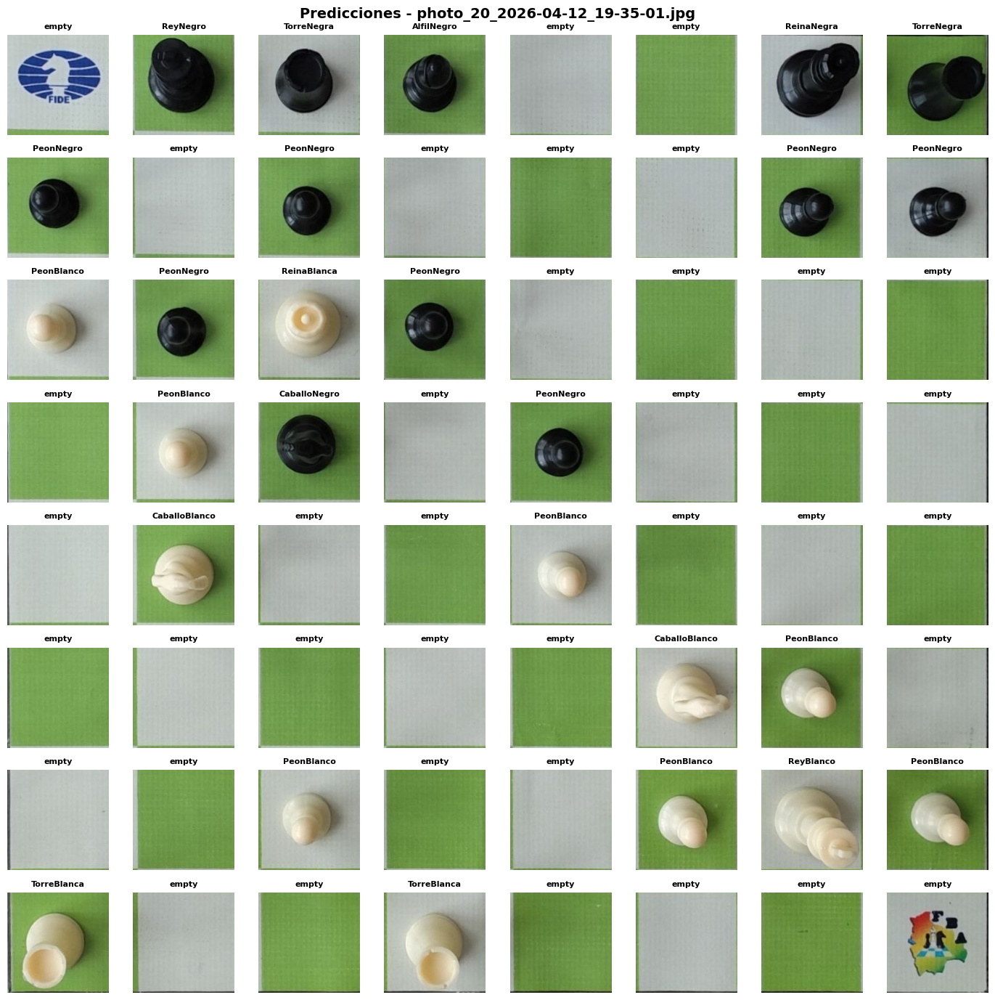


Imagen 17/51: photo_20_2026-04-12_19-35-01.jpg
Coordenadas detectadas: (0, 0) a (1280, 1264)
Tablero de predicciones (fila por fila):
Fila 0: ['empty', 'ReyNegro', 'TorreNegra', 'AlfilNegro', 'empty', 'empty', 'ReinaNegra', 'TorreNegra']
Fila 1: ['PeonNegro', 'empty', 'PeonNegro', 'empty', 'empty', 'empty', 'PeonNegro', 'PeonNegro']
Fila 2: ['PeonBlanco', 'PeonNegro', 'ReinaBlanca', 'PeonNegro', 'empty', 'empty', 'empty', 'empty']
Fila 3: ['empty', 'PeonBlanco', 'CaballoNegro', 'empty', 'PeonNegro', 'empty', 'empty', 'empty']
Fila 4: ['empty', 'CaballoBlanco', 'empty', 'empty', 'PeonBlanco', 'empty', 'empty', 'empty']
Fila 5: ['empty', 'empty', 'empty', 'empty', 'empty', 'CaballoBlanco', 'PeonBlanco', 'empty']
Fila 6: ['empty', 'empty', 'PeonBlanco', 'empty', 'empty', 'PeonBlanco', 'ReyBlanco', 'PeonBlanco']
Fila 7: ['TorreBlanca', 'empty', 'empty', 'TorreBlanca', 'empty', 'empty', 'empty', 'empty']



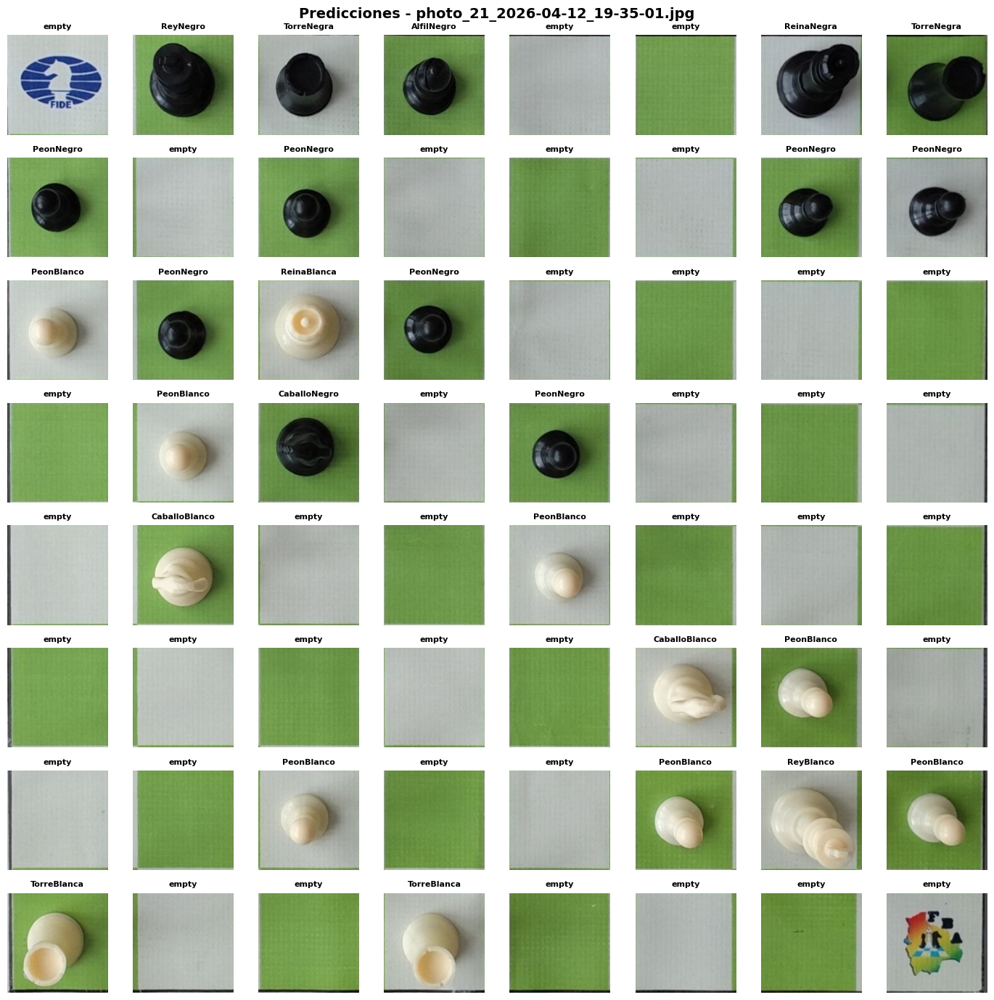


Imagen 18/51: photo_21_2026-04-12_19-35-01.jpg
Coordenadas detectadas: (0, 0) a (1280, 1275)
Tablero de predicciones (fila por fila):
Fila 0: ['empty', 'ReyNegro', 'TorreNegra', 'AlfilNegro', 'empty', 'empty', 'ReinaNegra', 'TorreNegra']
Fila 1: ['PeonNegro', 'empty', 'PeonNegro', 'empty', 'empty', 'empty', 'PeonNegro', 'PeonNegro']
Fila 2: ['PeonBlanco', 'PeonNegro', 'ReinaBlanca', 'PeonNegro', 'empty', 'empty', 'empty', 'empty']
Fila 3: ['empty', 'PeonBlanco', 'CaballoNegro', 'empty', 'PeonNegro', 'empty', 'empty', 'empty']
Fila 4: ['empty', 'CaballoBlanco', 'empty', 'empty', 'PeonBlanco', 'empty', 'empty', 'empty']
Fila 5: ['empty', 'empty', 'empty', 'empty', 'empty', 'CaballoBlanco', 'PeonBlanco', 'empty']
Fila 6: ['empty', 'empty', 'PeonBlanco', 'empty', 'empty', 'PeonBlanco', 'ReyBlanco', 'PeonBlanco']
Fila 7: ['TorreBlanca', 'empty', 'empty', 'TorreBlanca', 'empty', 'empty', 'empty', 'empty']



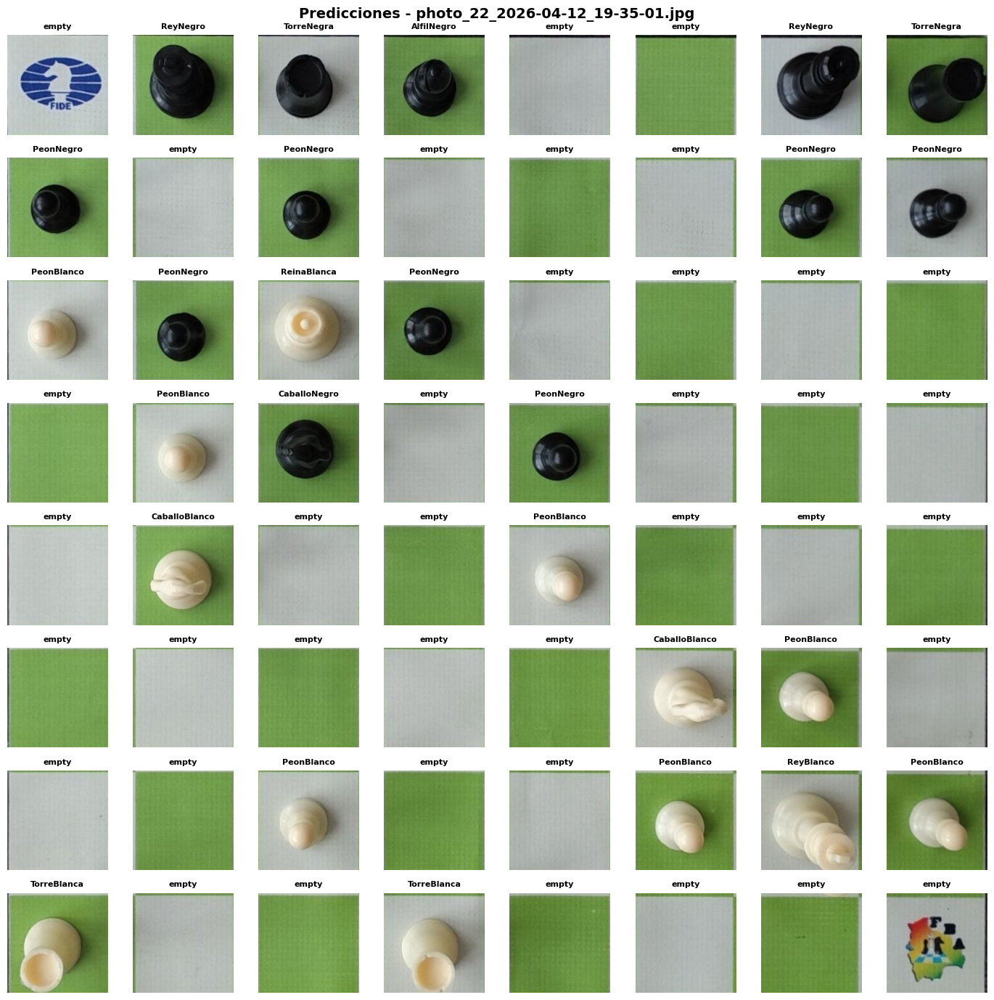


Imagen 19/51: photo_22_2026-04-12_19-35-01.jpg
Coordenadas detectadas: (0, 0) a (1280, 1279)
Tablero de predicciones (fila por fila):
Fila 0: ['empty', 'ReyNegro', 'TorreNegra', 'AlfilNegro', 'empty', 'empty', 'ReyNegro', 'TorreNegra']
Fila 1: ['PeonNegro', 'empty', 'PeonNegro', 'empty', 'empty', 'empty', 'PeonNegro', 'PeonNegro']
Fila 2: ['PeonBlanco', 'PeonNegro', 'ReinaBlanca', 'PeonNegro', 'empty', 'empty', 'empty', 'empty']
Fila 3: ['empty', 'PeonBlanco', 'CaballoNegro', 'empty', 'PeonNegro', 'empty', 'empty', 'empty']
Fila 4: ['empty', 'CaballoBlanco', 'empty', 'empty', 'PeonBlanco', 'empty', 'empty', 'empty']
Fila 5: ['empty', 'empty', 'empty', 'empty', 'empty', 'CaballoBlanco', 'PeonBlanco', 'empty']
Fila 6: ['empty', 'empty', 'PeonBlanco', 'empty', 'empty', 'PeonBlanco', 'ReyBlanco', 'PeonBlanco']
Fila 7: ['TorreBlanca', 'empty', 'empty', 'TorreBlanca', 'empty', 'empty', 'empty', 'empty']



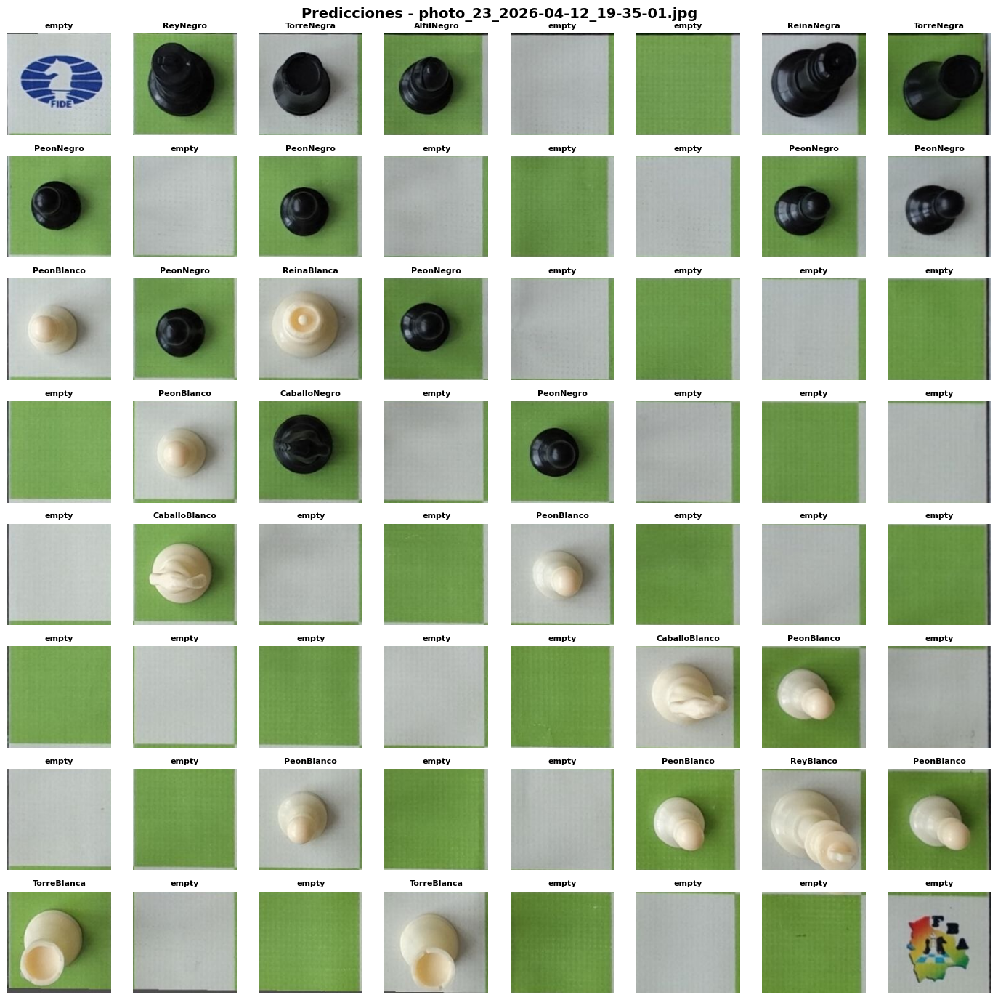


Imagen 20/51: photo_23_2026-04-12_19-35-01.jpg
Coordenadas detectadas: (0, 0) a (1280, 1250)
Tablero de predicciones (fila por fila):
Fila 0: ['empty', 'ReyNegro', 'TorreNegra', 'AlfilNegro', 'empty', 'empty', 'ReinaNegra', 'TorreNegra']
Fila 1: ['PeonNegro', 'empty', 'PeonNegro', 'empty', 'empty', 'empty', 'PeonNegro', 'PeonNegro']
Fila 2: ['PeonBlanco', 'PeonNegro', 'ReinaBlanca', 'PeonNegro', 'empty', 'empty', 'empty', 'empty']
Fila 3: ['empty', 'PeonBlanco', 'CaballoNegro', 'empty', 'PeonNegro', 'empty', 'empty', 'empty']
Fila 4: ['empty', 'CaballoBlanco', 'empty', 'empty', 'PeonBlanco', 'empty', 'empty', 'empty']
Fila 5: ['empty', 'empty', 'empty', 'empty', 'empty', 'CaballoBlanco', 'PeonBlanco', 'empty']
Fila 6: ['empty', 'empty', 'PeonBlanco', 'empty', 'empty', 'PeonBlanco', 'ReyBlanco', 'PeonBlanco']
Fila 7: ['TorreBlanca', 'empty', 'empty', 'TorreBlanca', 'empty', 'empty', 'empty', 'empty']



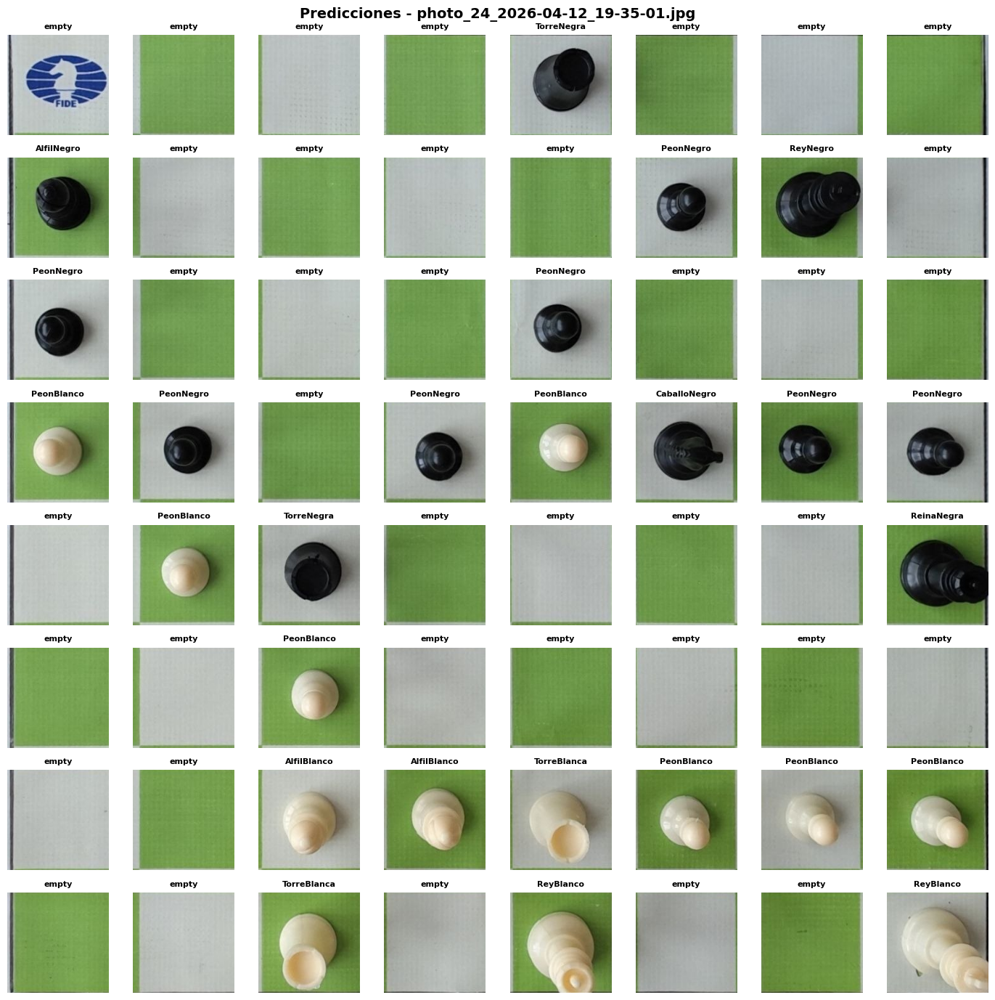


Imagen 21/51: photo_24_2026-04-12_19-35-01.jpg
Coordenadas detectadas: (0, 0) a (1280, 1270)
Tablero de predicciones (fila por fila):
Fila 0: ['empty', 'empty', 'empty', 'empty', 'TorreNegra', 'empty', 'empty', 'empty']
Fila 1: ['AlfilNegro', 'empty', 'empty', 'empty', 'empty', 'PeonNegro', 'ReyNegro', 'empty']
Fila 2: ['PeonNegro', 'empty', 'empty', 'empty', 'PeonNegro', 'empty', 'empty', 'empty']
Fila 3: ['PeonBlanco', 'PeonNegro', 'empty', 'PeonNegro', 'PeonBlanco', 'CaballoNegro', 'PeonNegro', 'PeonNegro']
Fila 4: ['empty', 'PeonBlanco', 'TorreNegra', 'empty', 'empty', 'empty', 'empty', 'ReinaNegra']
Fila 5: ['empty', 'empty', 'PeonBlanco', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 6: ['empty', 'empty', 'AlfilBlanco', 'AlfilBlanco', 'TorreBlanca', 'PeonBlanco', 'PeonBlanco', 'PeonBlanco']
Fila 7: ['empty', 'empty', 'TorreBlanca', 'empty', 'ReyBlanco', 'empty', 'empty', 'ReyBlanco']



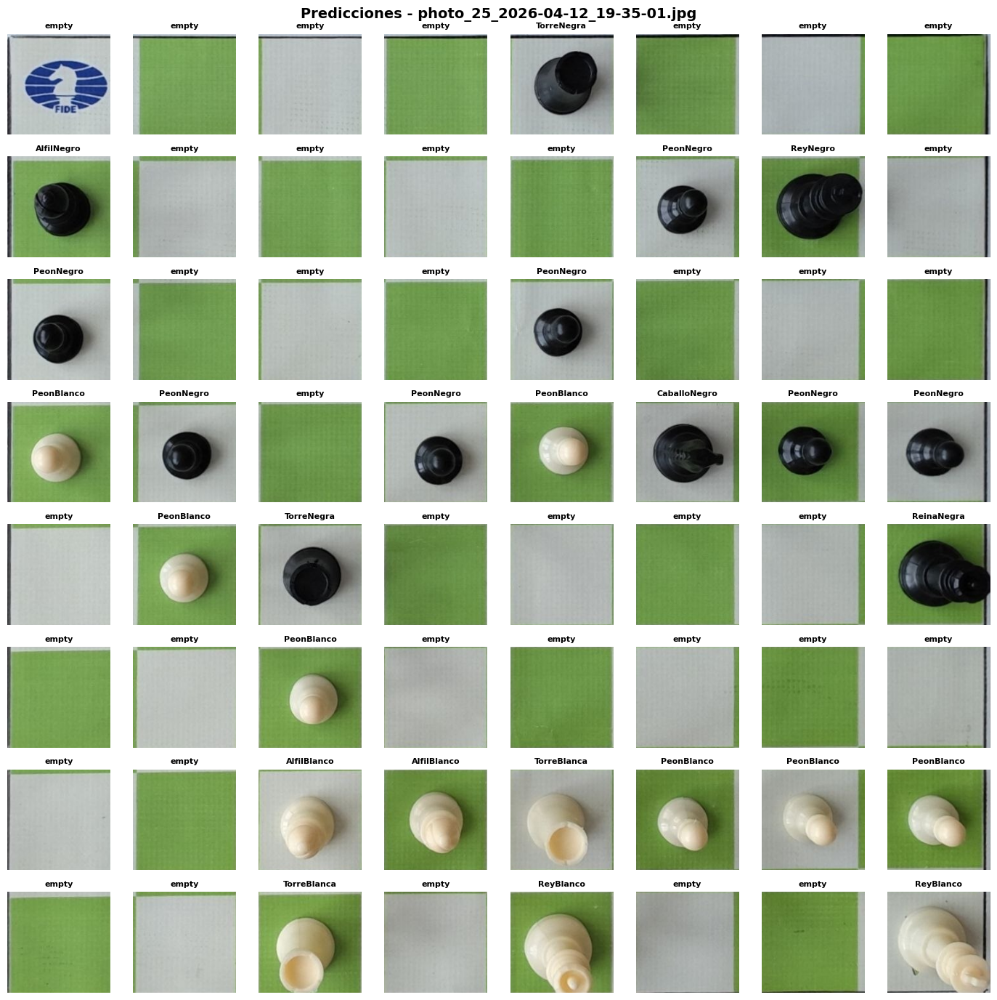


Imagen 22/51: photo_25_2026-04-12_19-35-01.jpg
Coordenadas detectadas: (0, 0) a (1280, 1262)
Tablero de predicciones (fila por fila):
Fila 0: ['empty', 'empty', 'empty', 'empty', 'TorreNegra', 'empty', 'empty', 'empty']
Fila 1: ['AlfilNegro', 'empty', 'empty', 'empty', 'empty', 'PeonNegro', 'ReyNegro', 'empty']
Fila 2: ['PeonNegro', 'empty', 'empty', 'empty', 'PeonNegro', 'empty', 'empty', 'empty']
Fila 3: ['PeonBlanco', 'PeonNegro', 'empty', 'PeonNegro', 'PeonBlanco', 'CaballoNegro', 'PeonNegro', 'PeonNegro']
Fila 4: ['empty', 'PeonBlanco', 'TorreNegra', 'empty', 'empty', 'empty', 'empty', 'ReinaNegra']
Fila 5: ['empty', 'empty', 'PeonBlanco', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 6: ['empty', 'empty', 'AlfilBlanco', 'AlfilBlanco', 'TorreBlanca', 'PeonBlanco', 'PeonBlanco', 'PeonBlanco']
Fila 7: ['empty', 'empty', 'TorreBlanca', 'empty', 'ReyBlanco', 'empty', 'empty', 'ReyBlanco']



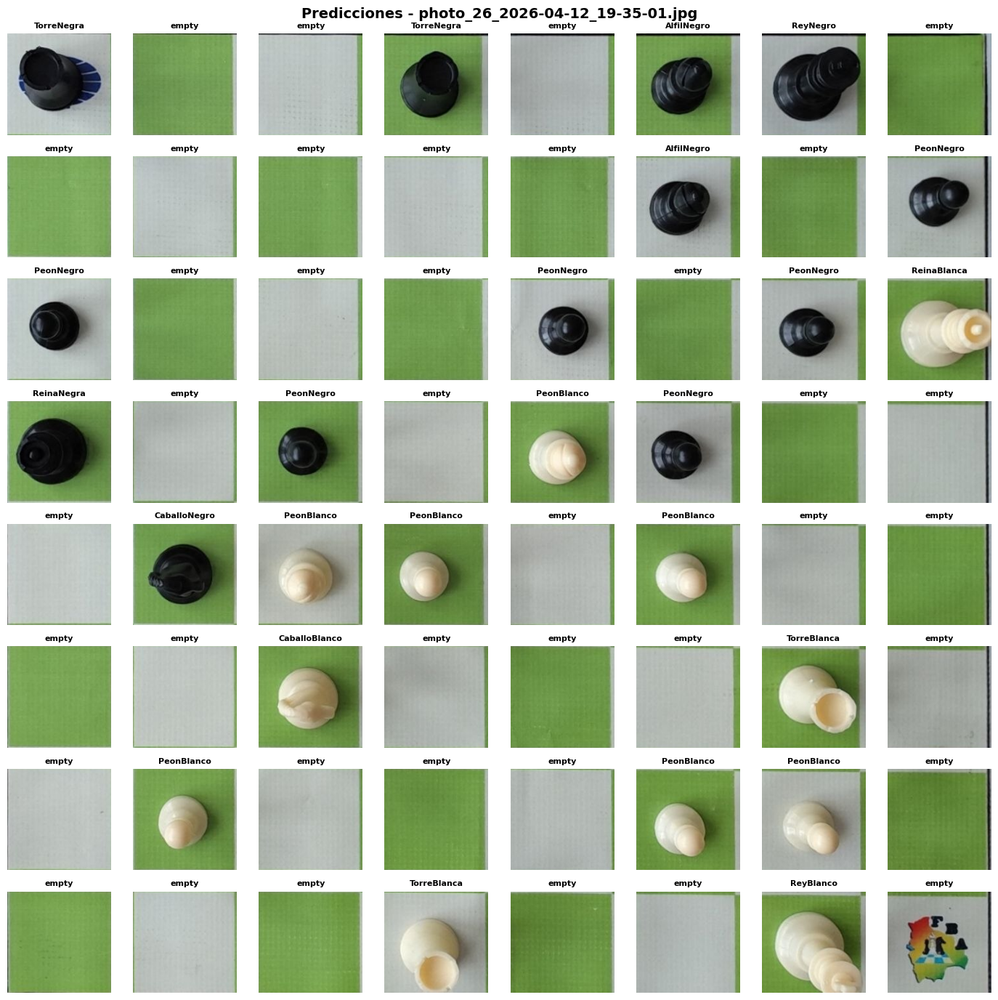


Imagen 23/51: photo_26_2026-04-12_19-35-01.jpg
Coordenadas detectadas: (0, 0) a (1280, 1251)
Tablero de predicciones (fila por fila):
Fila 0: ['TorreNegra', 'empty', 'empty', 'TorreNegra', 'empty', 'AlfilNegro', 'ReyNegro', 'empty']
Fila 1: ['empty', 'empty', 'empty', 'empty', 'empty', 'AlfilNegro', 'empty', 'PeonNegro']
Fila 2: ['PeonNegro', 'empty', 'empty', 'empty', 'PeonNegro', 'empty', 'PeonNegro', 'ReinaBlanca']
Fila 3: ['ReinaNegra', 'empty', 'PeonNegro', 'empty', 'PeonBlanco', 'PeonNegro', 'empty', 'empty']
Fila 4: ['empty', 'CaballoNegro', 'PeonBlanco', 'PeonBlanco', 'empty', 'PeonBlanco', 'empty', 'empty']
Fila 5: ['empty', 'empty', 'CaballoBlanco', 'empty', 'empty', 'empty', 'TorreBlanca', 'empty']
Fila 6: ['empty', 'PeonBlanco', 'empty', 'empty', 'empty', 'PeonBlanco', 'PeonBlanco', 'empty']
Fila 7: ['empty', 'empty', 'empty', 'TorreBlanca', 'empty', 'empty', 'ReyBlanco', 'empty']



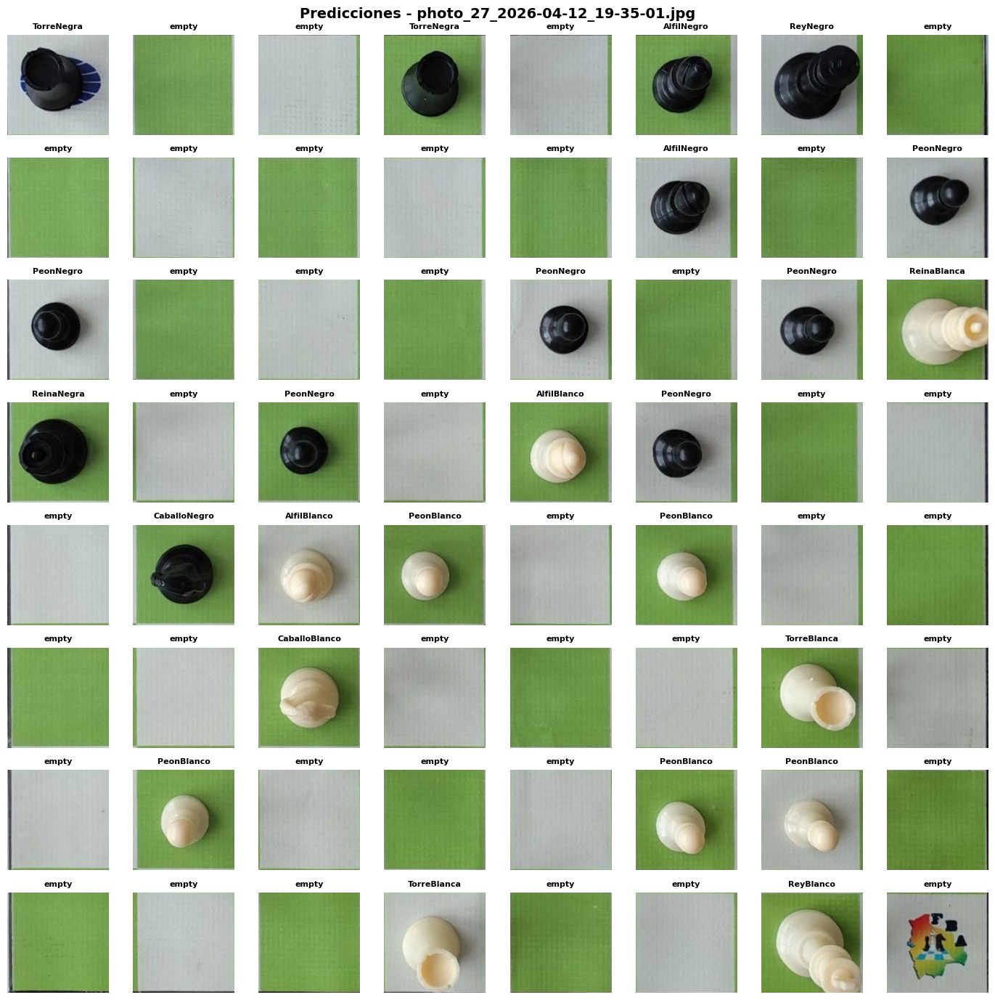


Imagen 24/51: photo_27_2026-04-12_19-35-01.jpg
Coordenadas detectadas: (0, 0) a (1280, 1270)
Tablero de predicciones (fila por fila):
Fila 0: ['TorreNegra', 'empty', 'empty', 'TorreNegra', 'empty', 'AlfilNegro', 'ReyNegro', 'empty']
Fila 1: ['empty', 'empty', 'empty', 'empty', 'empty', 'AlfilNegro', 'empty', 'PeonNegro']
Fila 2: ['PeonNegro', 'empty', 'empty', 'empty', 'PeonNegro', 'empty', 'PeonNegro', 'ReinaBlanca']
Fila 3: ['ReinaNegra', 'empty', 'PeonNegro', 'empty', 'AlfilBlanco', 'PeonNegro', 'empty', 'empty']
Fila 4: ['empty', 'CaballoNegro', 'AlfilBlanco', 'PeonBlanco', 'empty', 'PeonBlanco', 'empty', 'empty']
Fila 5: ['empty', 'empty', 'CaballoBlanco', 'empty', 'empty', 'empty', 'TorreBlanca', 'empty']
Fila 6: ['empty', 'PeonBlanco', 'empty', 'empty', 'empty', 'PeonBlanco', 'PeonBlanco', 'empty']
Fila 7: ['empty', 'empty', 'empty', 'TorreBlanca', 'empty', 'empty', 'ReyBlanco', 'empty']



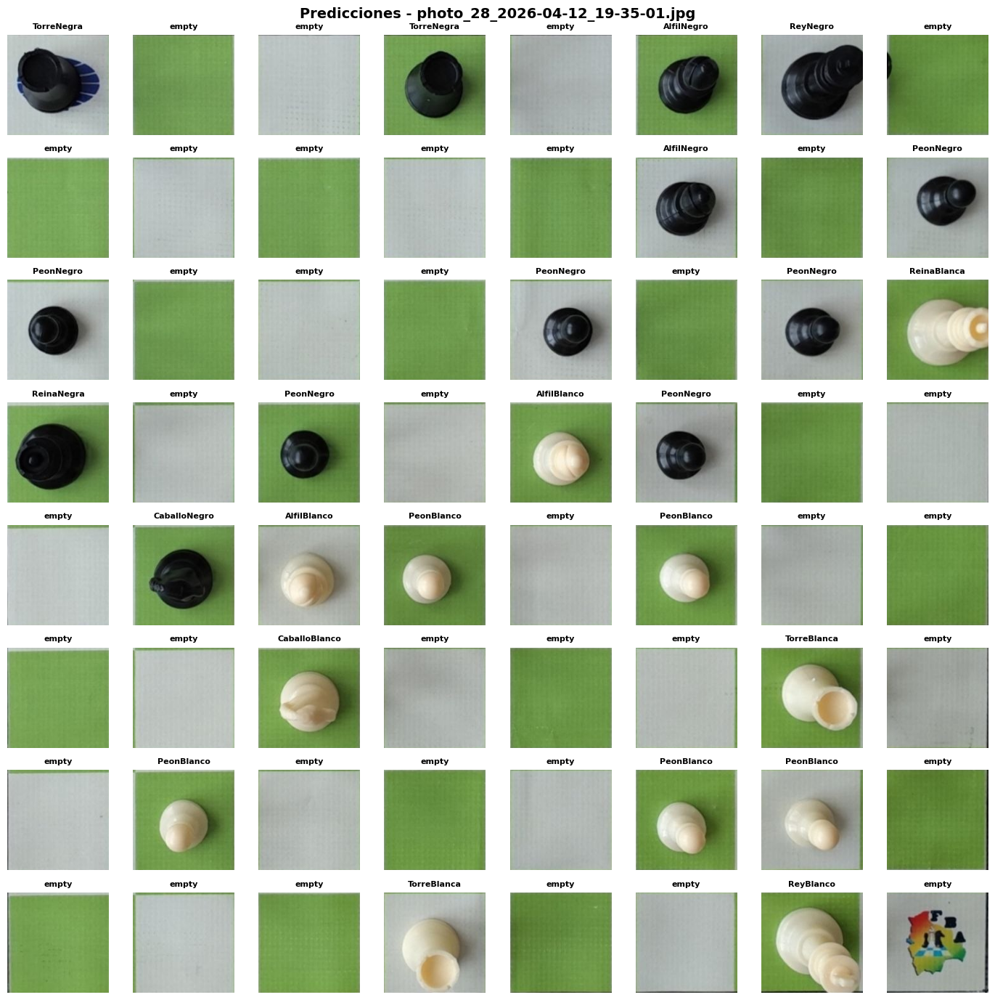


Imagen 25/51: photo_28_2026-04-12_19-35-01.jpg
Coordenadas detectadas: (0, 0) a (1280, 1267)
Tablero de predicciones (fila por fila):
Fila 0: ['TorreNegra', 'empty', 'empty', 'TorreNegra', 'empty', 'AlfilNegro', 'ReyNegro', 'empty']
Fila 1: ['empty', 'empty', 'empty', 'empty', 'empty', 'AlfilNegro', 'empty', 'PeonNegro']
Fila 2: ['PeonNegro', 'empty', 'empty', 'empty', 'PeonNegro', 'empty', 'PeonNegro', 'ReinaBlanca']
Fila 3: ['ReinaNegra', 'empty', 'PeonNegro', 'empty', 'AlfilBlanco', 'PeonNegro', 'empty', 'empty']
Fila 4: ['empty', 'CaballoNegro', 'AlfilBlanco', 'PeonBlanco', 'empty', 'PeonBlanco', 'empty', 'empty']
Fila 5: ['empty', 'empty', 'CaballoBlanco', 'empty', 'empty', 'empty', 'TorreBlanca', 'empty']
Fila 6: ['empty', 'PeonBlanco', 'empty', 'empty', 'empty', 'PeonBlanco', 'PeonBlanco', 'empty']
Fila 7: ['empty', 'empty', 'empty', 'TorreBlanca', 'empty', 'empty', 'ReyBlanco', 'empty']



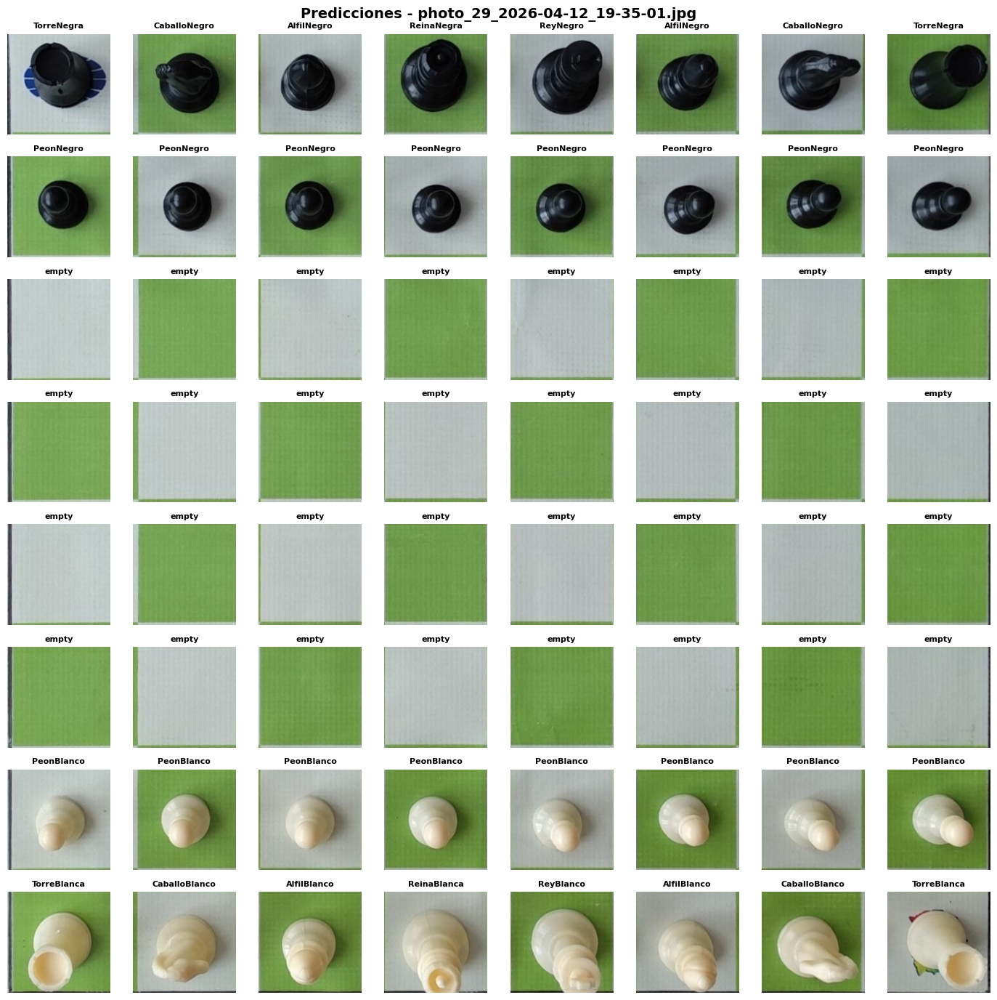


Imagen 26/51: photo_29_2026-04-12_19-35-01.jpg
Coordenadas detectadas: (0, 0) a (1280, 1261)
Tablero de predicciones (fila por fila):
Fila 0: ['TorreNegra', 'CaballoNegro', 'AlfilNegro', 'ReinaNegra', 'ReyNegro', 'AlfilNegro', 'CaballoNegro', 'TorreNegra']
Fila 1: ['PeonNegro', 'PeonNegro', 'PeonNegro', 'PeonNegro', 'PeonNegro', 'PeonNegro', 'PeonNegro', 'PeonNegro']
Fila 2: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 3: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 4: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 5: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 6: ['PeonBlanco', 'PeonBlanco', 'PeonBlanco', 'PeonBlanco', 'PeonBlanco', 'PeonBlanco', 'PeonBlanco', 'PeonBlanco']
Fila 7: ['TorreBlanca', 'CaballoBlanco', 'AlfilBlanco', 'ReinaBlanca', 'ReyBlanco', 'AlfilBlanco', 'CaballoBlanco', 'TorreBlanca']



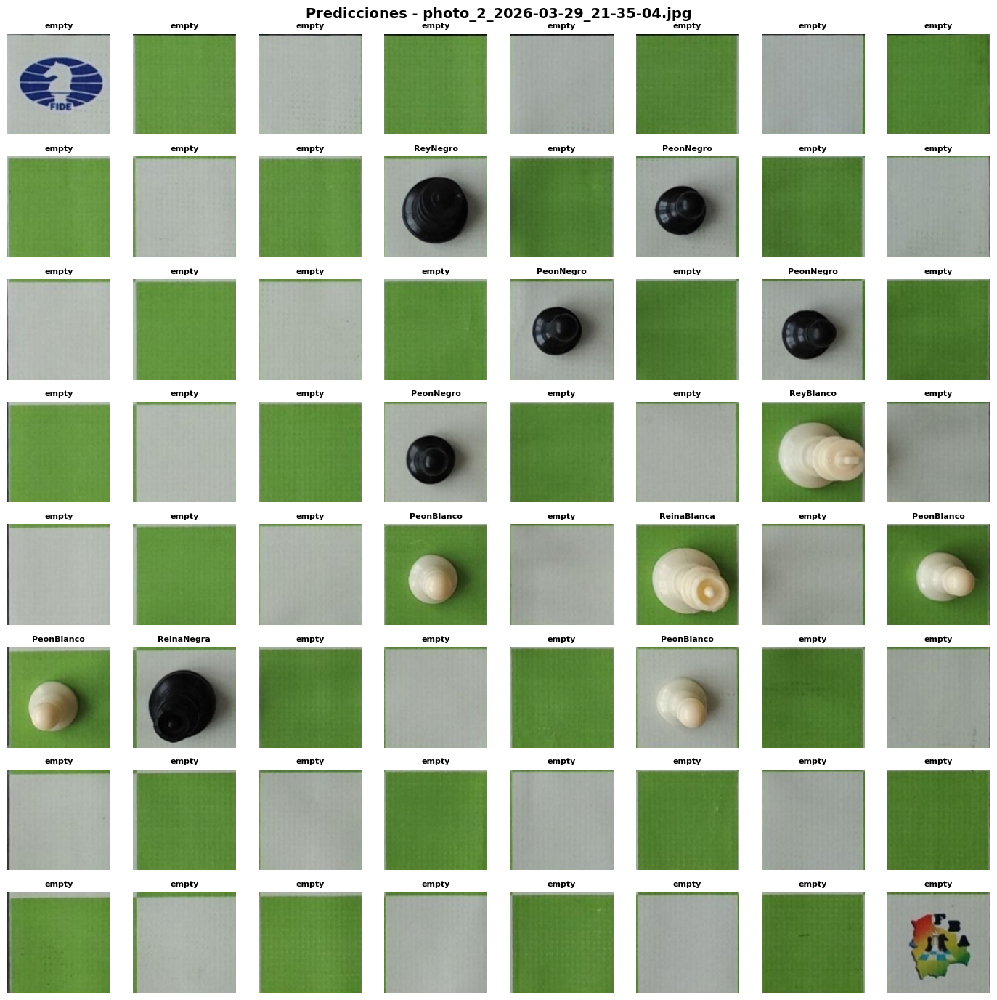


Imagen 27/51: photo_2_2026-03-29_21-35-04.jpg
Coordenadas detectadas: (0, 0) a (1280, 1263)
Tablero de predicciones (fila por fila):
Fila 0: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 1: ['empty', 'empty', 'empty', 'ReyNegro', 'empty', 'PeonNegro', 'empty', 'empty']
Fila 2: ['empty', 'empty', 'empty', 'empty', 'PeonNegro', 'empty', 'PeonNegro', 'empty']
Fila 3: ['empty', 'empty', 'empty', 'PeonNegro', 'empty', 'empty', 'ReyBlanco', 'empty']
Fila 4: ['empty', 'empty', 'empty', 'PeonBlanco', 'empty', 'ReinaBlanca', 'empty', 'PeonBlanco']
Fila 5: ['PeonBlanco', 'ReinaNegra', 'empty', 'empty', 'empty', 'PeonBlanco', 'empty', 'empty']
Fila 6: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 7: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']



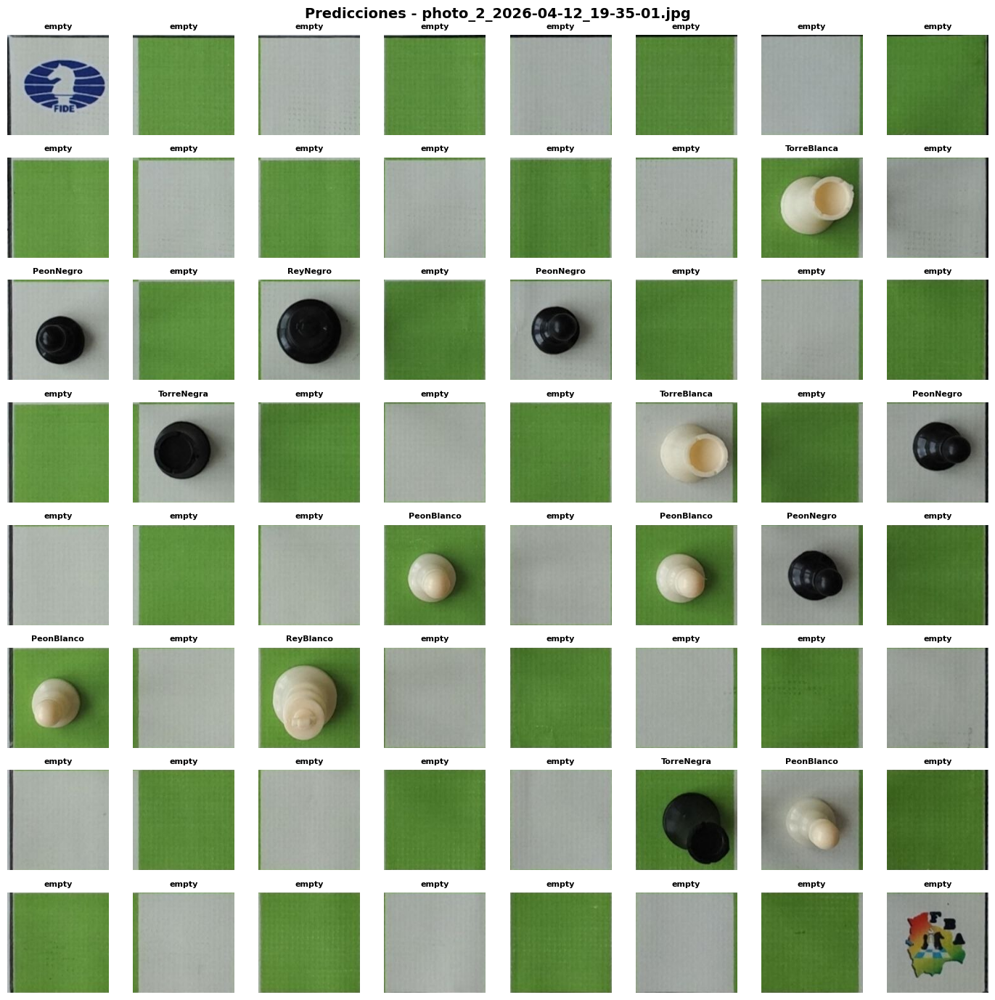


Imagen 28/51: photo_2_2026-04-12_19-35-01.jpg
Coordenadas detectadas: (0, 0) a (1280, 1271)
Tablero de predicciones (fila por fila):
Fila 0: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 1: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'TorreBlanca', 'empty']
Fila 2: ['PeonNegro', 'empty', 'ReyNegro', 'empty', 'PeonNegro', 'empty', 'empty', 'empty']
Fila 3: ['empty', 'TorreNegra', 'empty', 'empty', 'empty', 'TorreBlanca', 'empty', 'PeonNegro']
Fila 4: ['empty', 'empty', 'empty', 'PeonBlanco', 'empty', 'PeonBlanco', 'PeonNegro', 'empty']
Fila 5: ['PeonBlanco', 'empty', 'ReyBlanco', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 6: ['empty', 'empty', 'empty', 'empty', 'empty', 'TorreNegra', 'PeonBlanco', 'empty']
Fila 7: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']



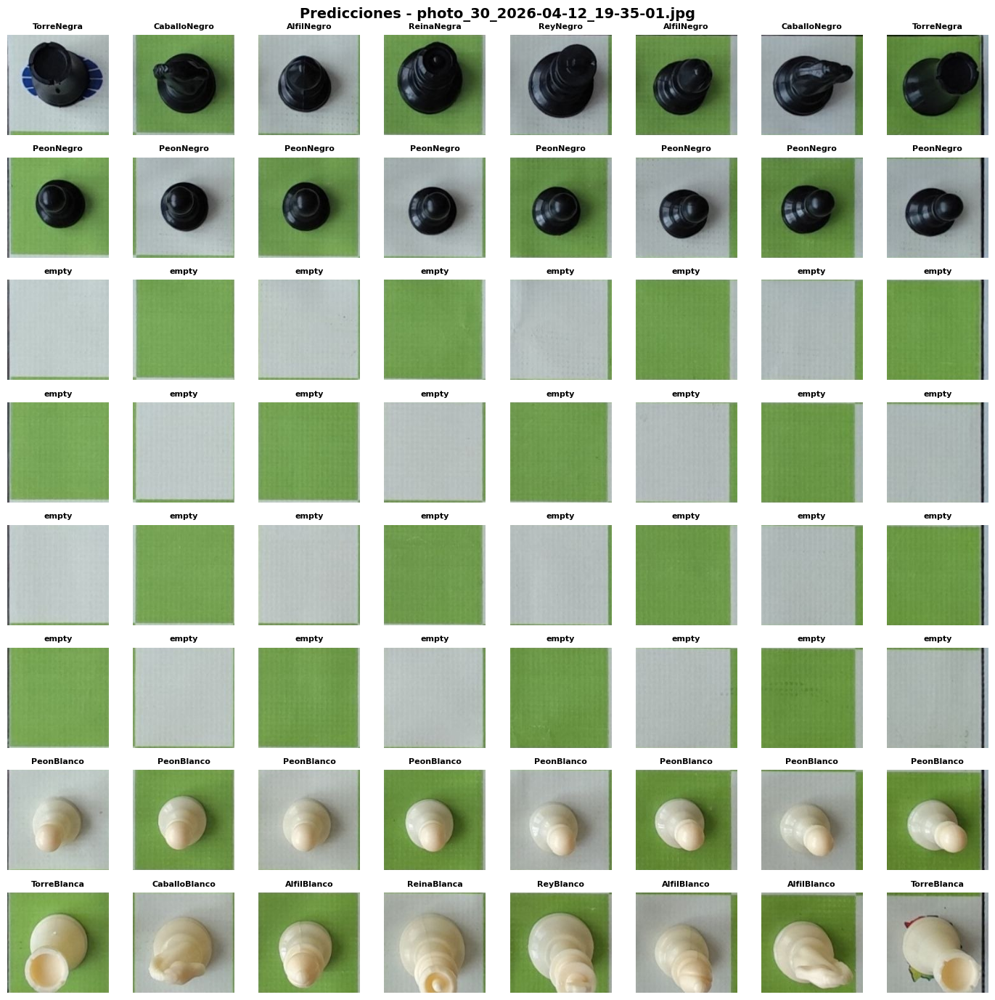


Imagen 29/51: photo_30_2026-04-12_19-35-01.jpg
Coordenadas detectadas: (0, 0) a (1280, 1269)
Tablero de predicciones (fila por fila):
Fila 0: ['TorreNegra', 'CaballoNegro', 'AlfilNegro', 'ReinaNegra', 'ReyNegro', 'AlfilNegro', 'CaballoNegro', 'TorreNegra']
Fila 1: ['PeonNegro', 'PeonNegro', 'PeonNegro', 'PeonNegro', 'PeonNegro', 'PeonNegro', 'PeonNegro', 'PeonNegro']
Fila 2: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 3: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 4: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 5: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 6: ['PeonBlanco', 'PeonBlanco', 'PeonBlanco', 'PeonBlanco', 'PeonBlanco', 'PeonBlanco', 'PeonBlanco', 'PeonBlanco']
Fila 7: ['TorreBlanca', 'CaballoBlanco', 'AlfilBlanco', 'ReinaBlanca', 'ReyBlanco', 'AlfilBlanco', 'AlfilBlanco', 'TorreBlanca']



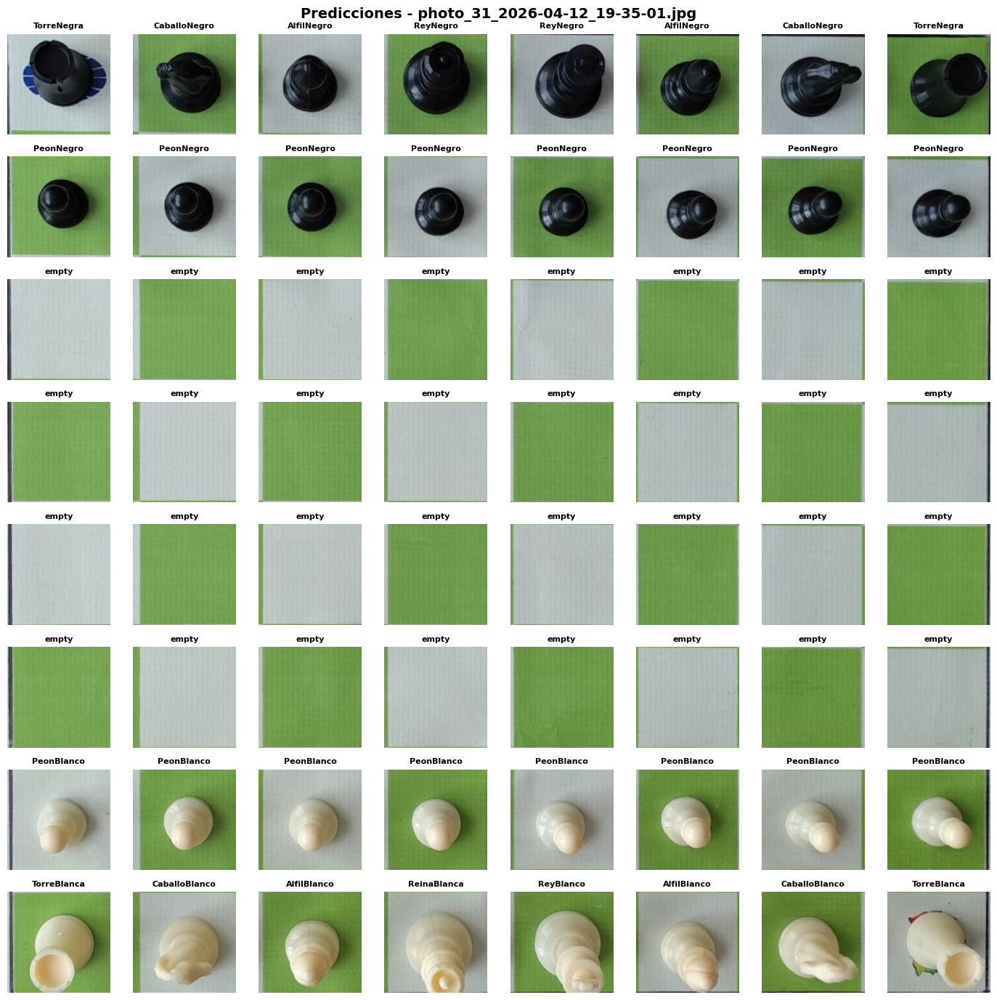


Imagen 30/51: photo_31_2026-04-12_19-35-01.jpg
Coordenadas detectadas: (0, 0) a (1280, 1263)
Tablero de predicciones (fila por fila):
Fila 0: ['TorreNegra', 'CaballoNegro', 'AlfilNegro', 'ReyNegro', 'ReyNegro', 'AlfilNegro', 'CaballoNegro', 'TorreNegra']
Fila 1: ['PeonNegro', 'PeonNegro', 'PeonNegro', 'PeonNegro', 'PeonNegro', 'PeonNegro', 'PeonNegro', 'PeonNegro']
Fila 2: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 3: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 4: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 5: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 6: ['PeonBlanco', 'PeonBlanco', 'PeonBlanco', 'PeonBlanco', 'PeonBlanco', 'PeonBlanco', 'PeonBlanco', 'PeonBlanco']
Fila 7: ['TorreBlanca', 'CaballoBlanco', 'AlfilBlanco', 'ReinaBlanca', 'ReyBlanco', 'AlfilBlanco', 'CaballoBlanco', 'TorreBlanca']



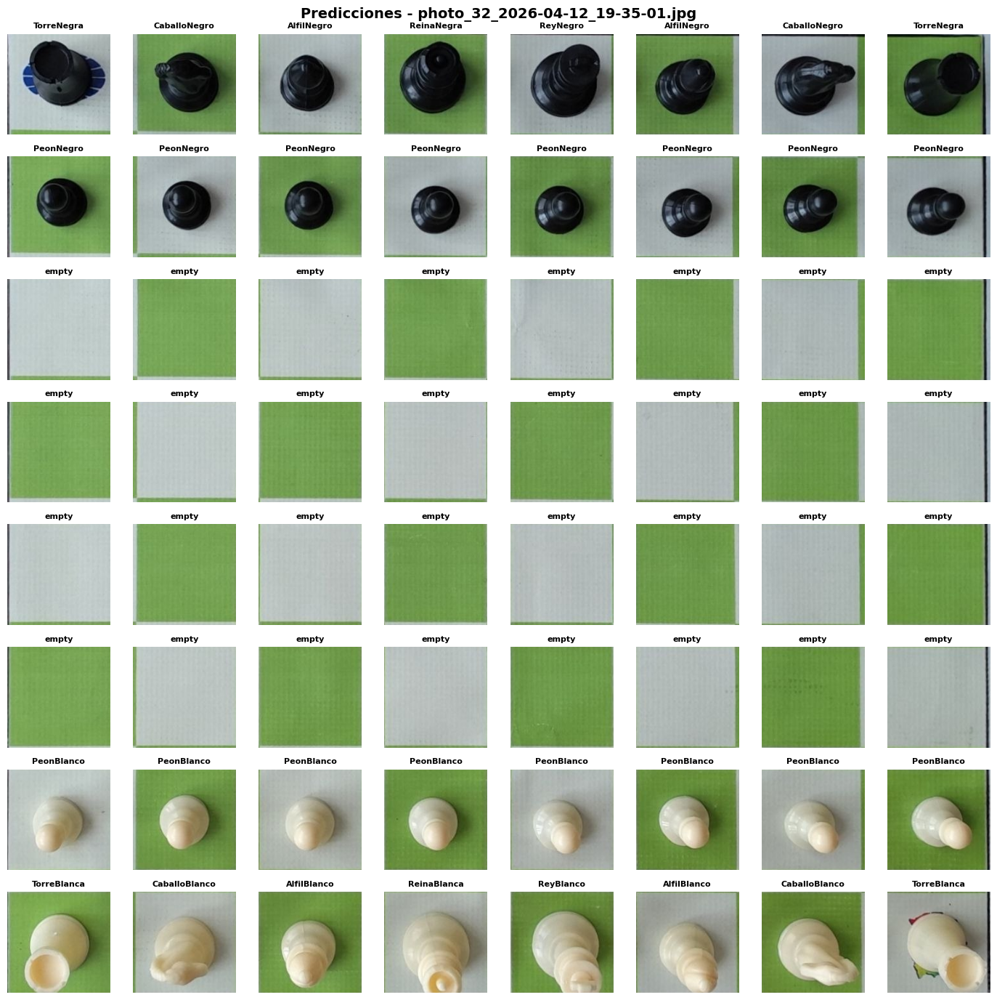


Imagen 31/51: photo_32_2026-04-12_19-35-01.jpg
Coordenadas detectadas: (0, 0) a (1280, 1263)
Tablero de predicciones (fila por fila):
Fila 0: ['TorreNegra', 'CaballoNegro', 'AlfilNegro', 'ReinaNegra', 'ReyNegro', 'AlfilNegro', 'CaballoNegro', 'TorreNegra']
Fila 1: ['PeonNegro', 'PeonNegro', 'PeonNegro', 'PeonNegro', 'PeonNegro', 'PeonNegro', 'PeonNegro', 'PeonNegro']
Fila 2: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 3: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 4: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 5: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 6: ['PeonBlanco', 'PeonBlanco', 'PeonBlanco', 'PeonBlanco', 'PeonBlanco', 'PeonBlanco', 'PeonBlanco', 'PeonBlanco']
Fila 7: ['TorreBlanca', 'CaballoBlanco', 'AlfilBlanco', 'ReinaBlanca', 'ReyBlanco', 'AlfilBlanco', 'CaballoBlanco', 'TorreBlanca']



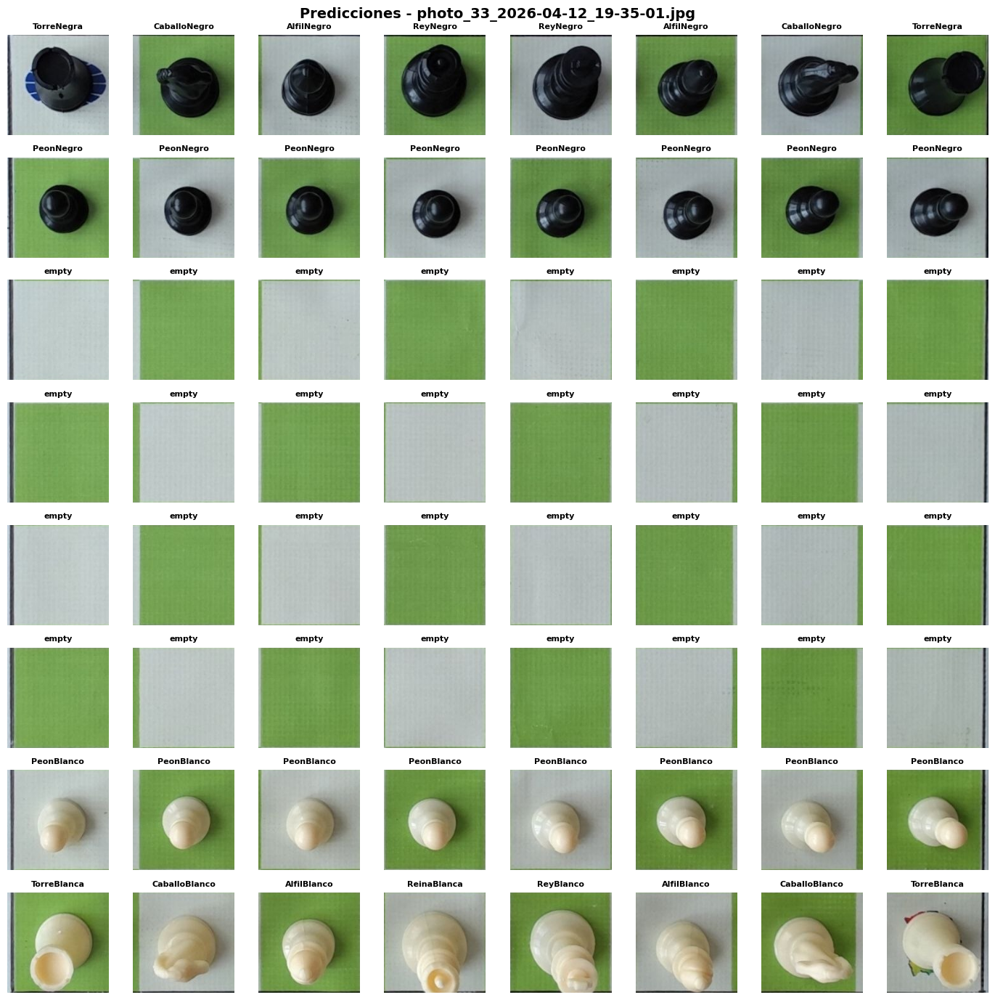


Imagen 32/51: photo_33_2026-04-12_19-35-01.jpg
Coordenadas detectadas: (0, 0) a (1280, 1267)
Tablero de predicciones (fila por fila):
Fila 0: ['TorreNegra', 'CaballoNegro', 'AlfilNegro', 'ReyNegro', 'ReyNegro', 'AlfilNegro', 'CaballoNegro', 'TorreNegra']
Fila 1: ['PeonNegro', 'PeonNegro', 'PeonNegro', 'PeonNegro', 'PeonNegro', 'PeonNegro', 'PeonNegro', 'PeonNegro']
Fila 2: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 3: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 4: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 5: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 6: ['PeonBlanco', 'PeonBlanco', 'PeonBlanco', 'PeonBlanco', 'PeonBlanco', 'PeonBlanco', 'PeonBlanco', 'PeonBlanco']
Fila 7: ['TorreBlanca', 'CaballoBlanco', 'AlfilBlanco', 'ReinaBlanca', 'ReyBlanco', 'AlfilBlanco', 'CaballoBlanco', 'TorreBlanca']



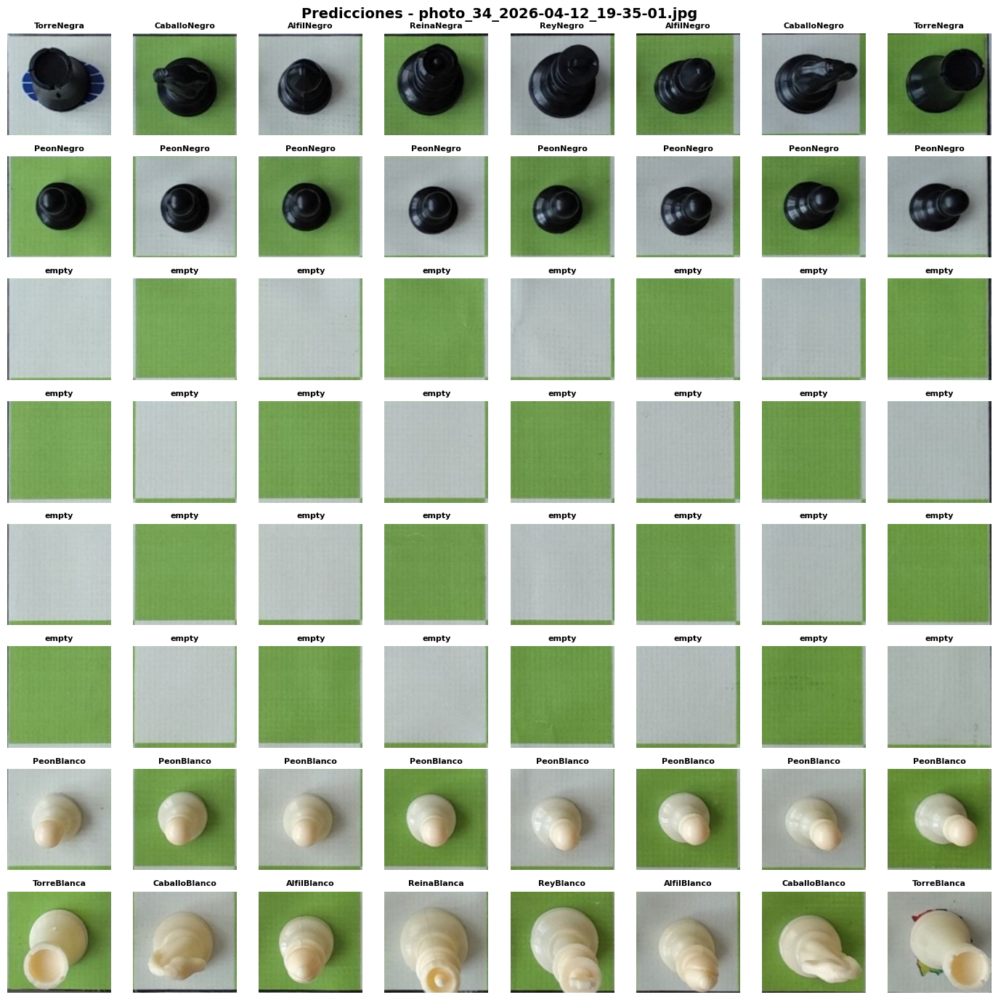


Imagen 33/51: photo_34_2026-04-12_19-35-01.jpg
Coordenadas detectadas: (0, 0) a (1280, 1252)
Tablero de predicciones (fila por fila):
Fila 0: ['TorreNegra', 'CaballoNegro', 'AlfilNegro', 'ReinaNegra', 'ReyNegro', 'AlfilNegro', 'CaballoNegro', 'TorreNegra']
Fila 1: ['PeonNegro', 'PeonNegro', 'PeonNegro', 'PeonNegro', 'PeonNegro', 'PeonNegro', 'PeonNegro', 'PeonNegro']
Fila 2: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 3: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 4: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 5: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 6: ['PeonBlanco', 'PeonBlanco', 'PeonBlanco', 'PeonBlanco', 'PeonBlanco', 'PeonBlanco', 'PeonBlanco', 'PeonBlanco']
Fila 7: ['TorreBlanca', 'CaballoBlanco', 'AlfilBlanco', 'ReinaBlanca', 'ReyBlanco', 'AlfilBlanco', 'CaballoBlanco', 'TorreBlanca']



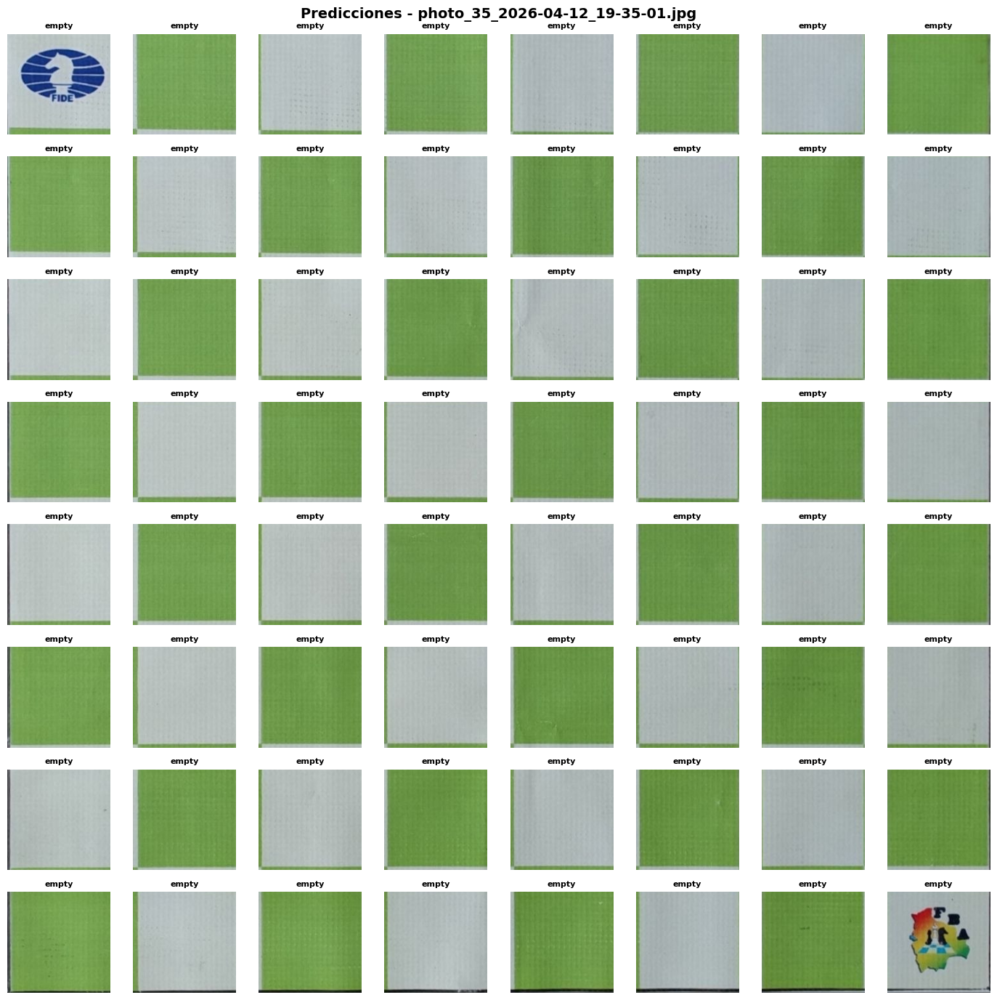


Imagen 34/51: photo_35_2026-04-12_19-35-01.jpg
Coordenadas detectadas: (0, 0) a (1280, 1256)
Tablero de predicciones (fila por fila):
Fila 0: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 1: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 2: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 3: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 4: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 5: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 6: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 7: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']



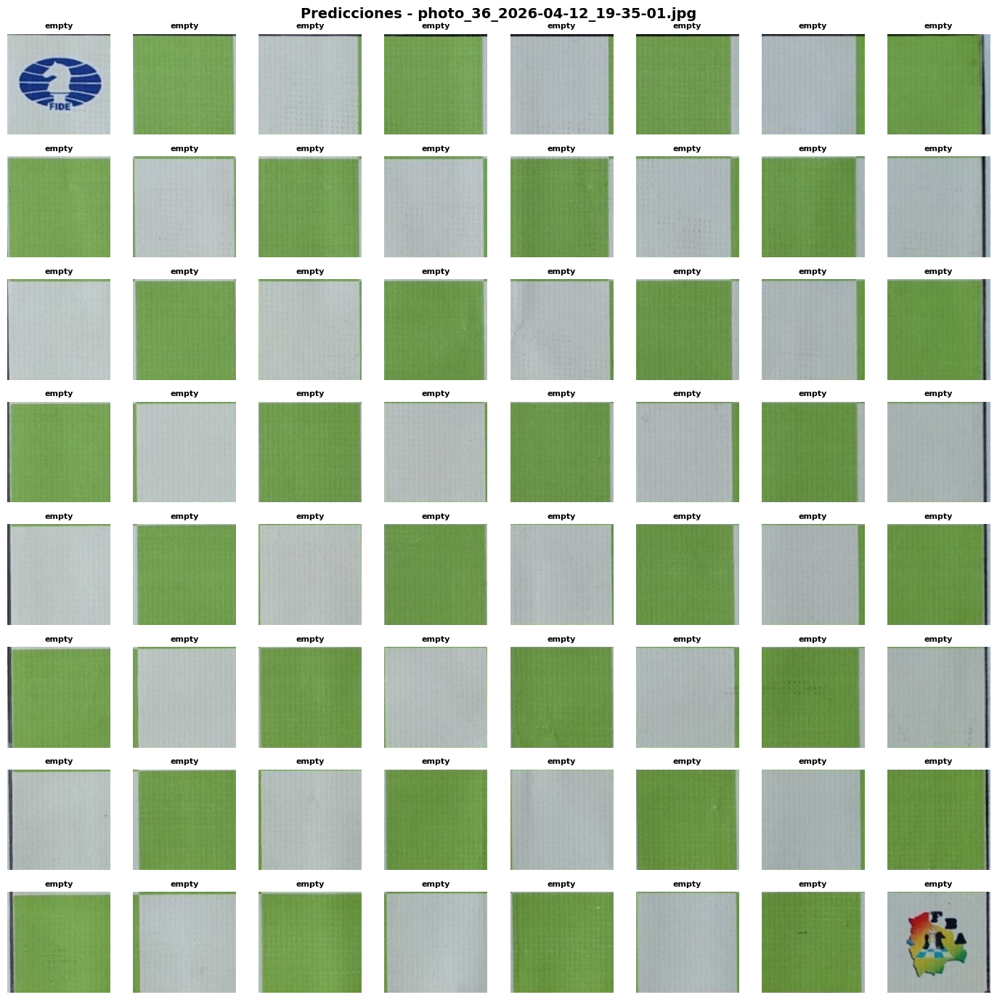


Imagen 35/51: photo_36_2026-04-12_19-35-01.jpg
Coordenadas detectadas: (0, 0) a (1280, 1263)
Tablero de predicciones (fila por fila):
Fila 0: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 1: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 2: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 3: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 4: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 5: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 6: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 7: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']



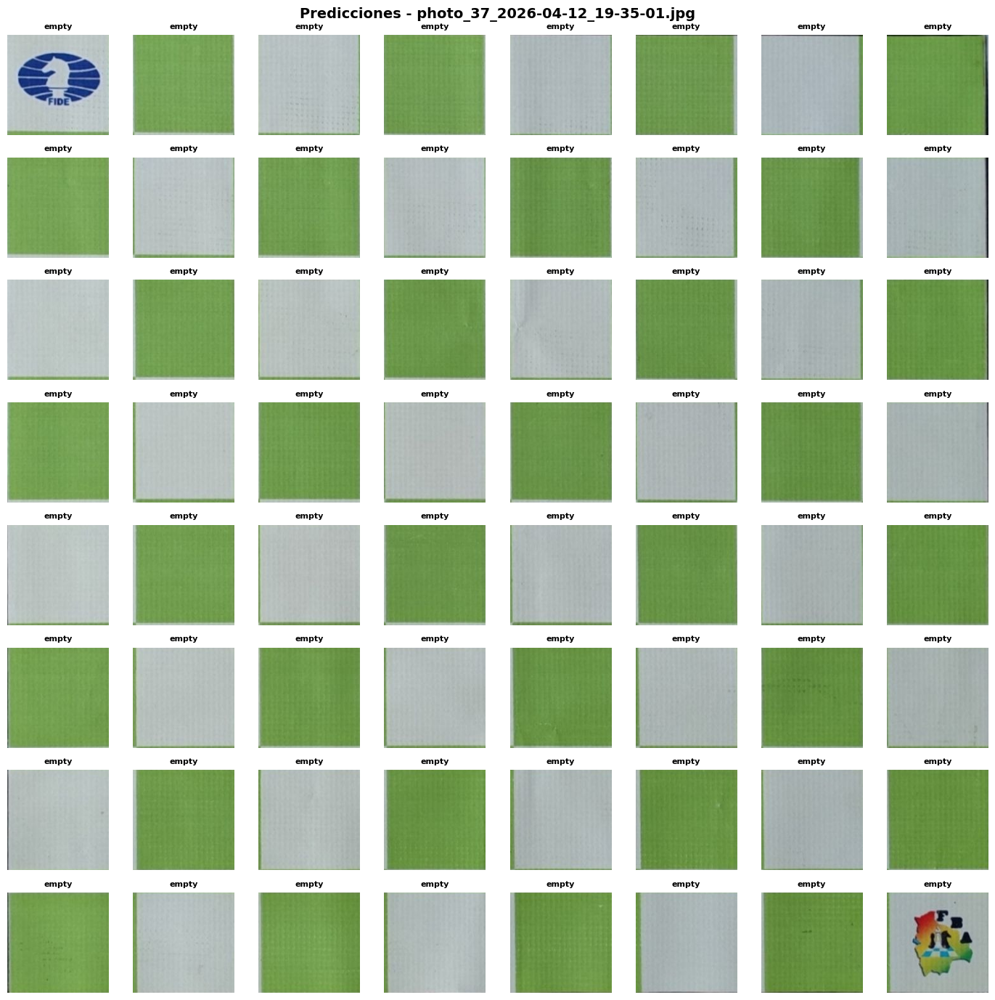


Imagen 36/51: photo_37_2026-04-12_19-35-01.jpg
Coordenadas detectadas: (0, 0) a (1280, 1265)
Tablero de predicciones (fila por fila):
Fila 0: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 1: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 2: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 3: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 4: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 5: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 6: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 7: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']



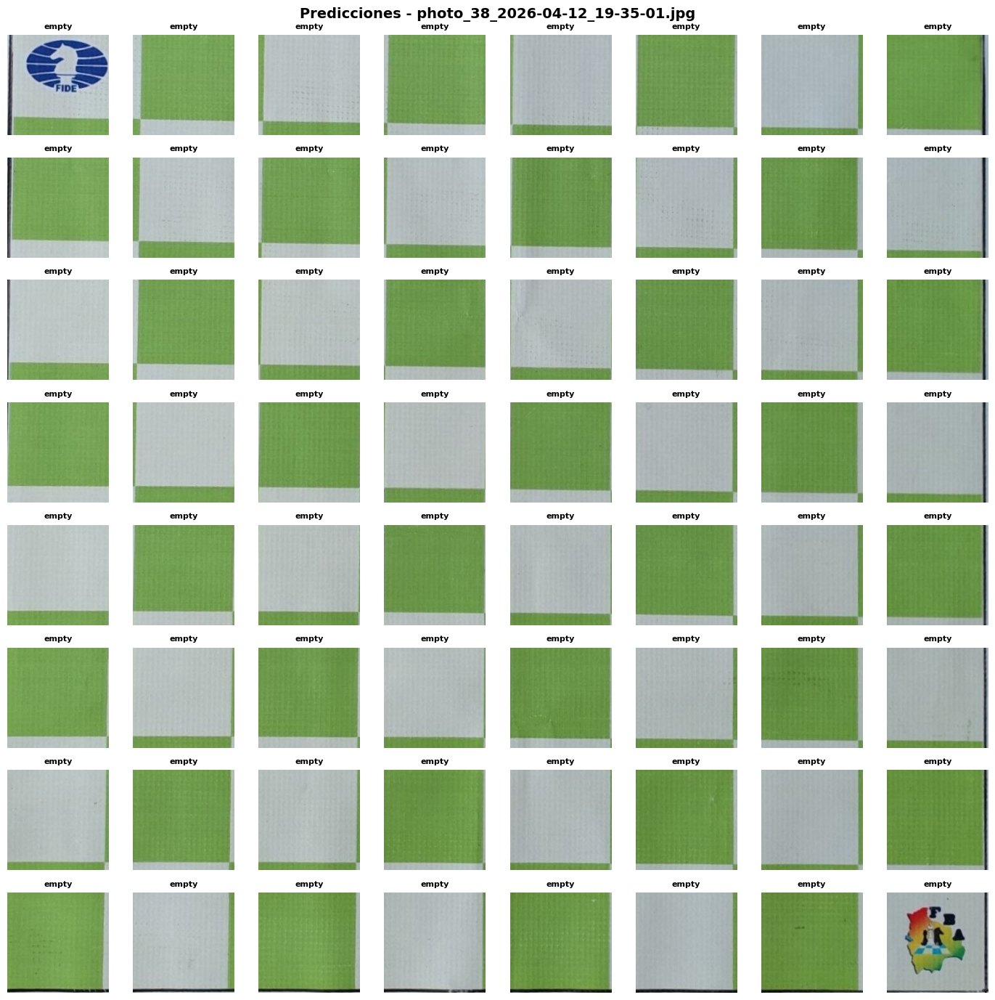


Imagen 37/51: photo_38_2026-04-12_19-35-01.jpg
Coordenadas detectadas: (0, 0) a (1280, 1268)
Tablero de predicciones (fila por fila):
Fila 0: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 1: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 2: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 3: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 4: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 5: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 6: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 7: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']



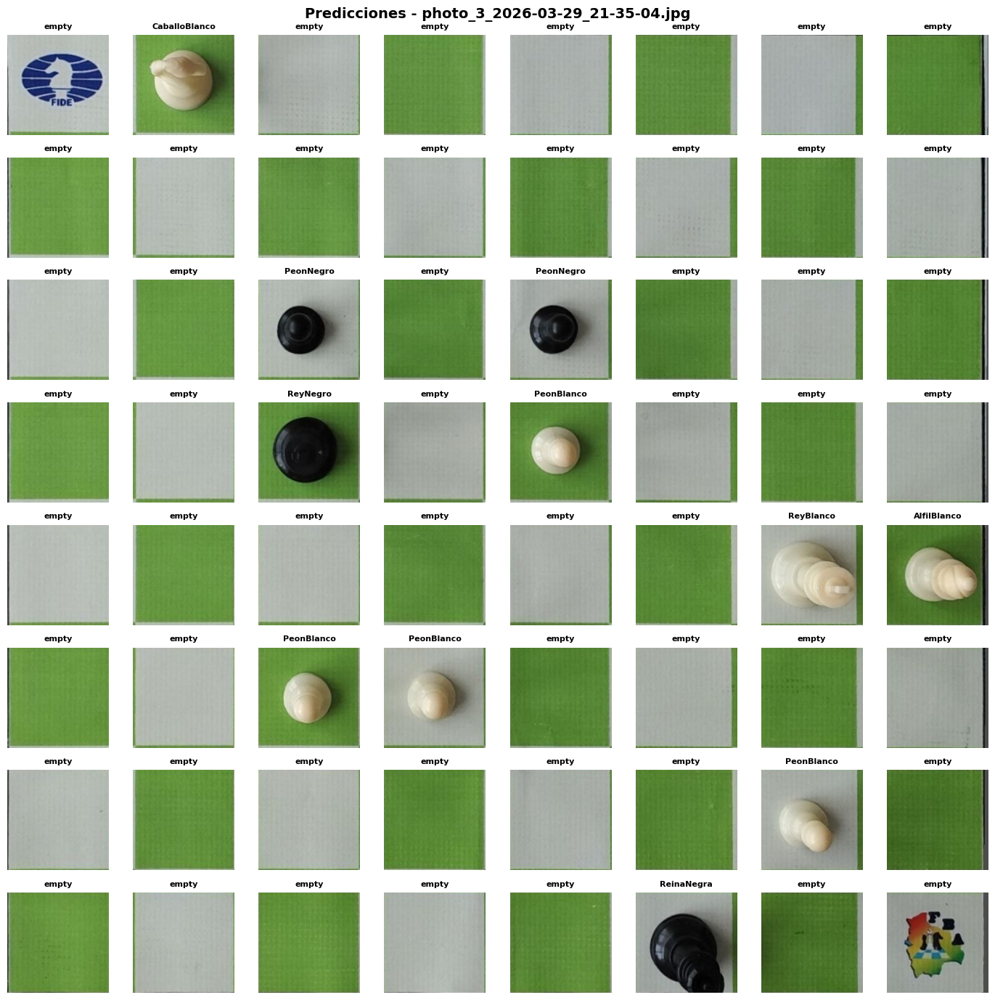


Imagen 38/51: photo_3_2026-03-29_21-35-04.jpg
Coordenadas detectadas: (0, 0) a (1280, 1269)
Tablero de predicciones (fila por fila):
Fila 0: ['empty', 'CaballoBlanco', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 1: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 2: ['empty', 'empty', 'PeonNegro', 'empty', 'PeonNegro', 'empty', 'empty', 'empty']
Fila 3: ['empty', 'empty', 'ReyNegro', 'empty', 'PeonBlanco', 'empty', 'empty', 'empty']
Fila 4: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'ReyBlanco', 'AlfilBlanco']
Fila 5: ['empty', 'empty', 'PeonBlanco', 'PeonBlanco', 'empty', 'empty', 'empty', 'empty']
Fila 6: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'PeonBlanco', 'empty']
Fila 7: ['empty', 'empty', 'empty', 'empty', 'empty', 'ReinaNegra', 'empty', 'empty']



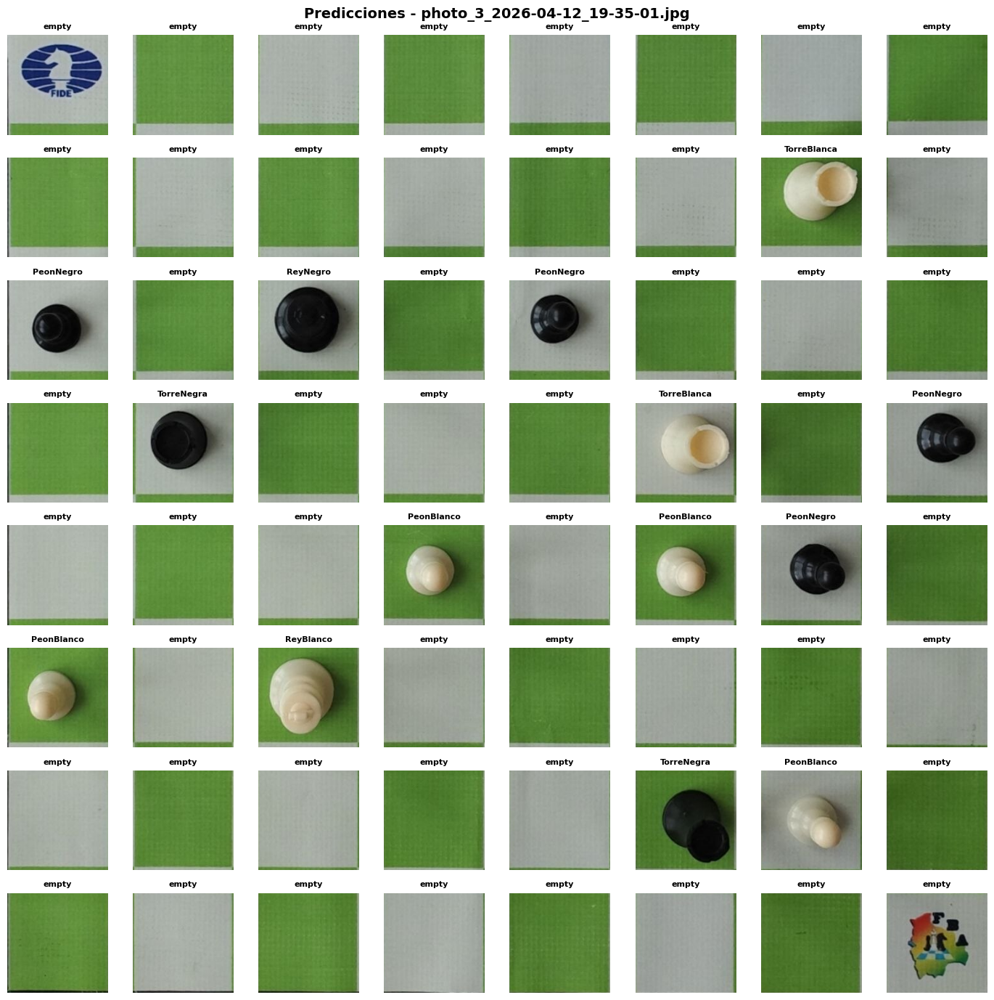


Imagen 39/51: photo_3_2026-04-12_19-35-01.jpg
Coordenadas detectadas: (0, 18) a (1271, 1277)
Tablero de predicciones (fila por fila):
Fila 0: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 1: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'TorreBlanca', 'empty']
Fila 2: ['PeonNegro', 'empty', 'ReyNegro', 'empty', 'PeonNegro', 'empty', 'empty', 'empty']
Fila 3: ['empty', 'TorreNegra', 'empty', 'empty', 'empty', 'TorreBlanca', 'empty', 'PeonNegro']
Fila 4: ['empty', 'empty', 'empty', 'PeonBlanco', 'empty', 'PeonBlanco', 'PeonNegro', 'empty']
Fila 5: ['PeonBlanco', 'empty', 'ReyBlanco', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 6: ['empty', 'empty', 'empty', 'empty', 'empty', 'TorreNegra', 'PeonBlanco', 'empty']
Fila 7: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']



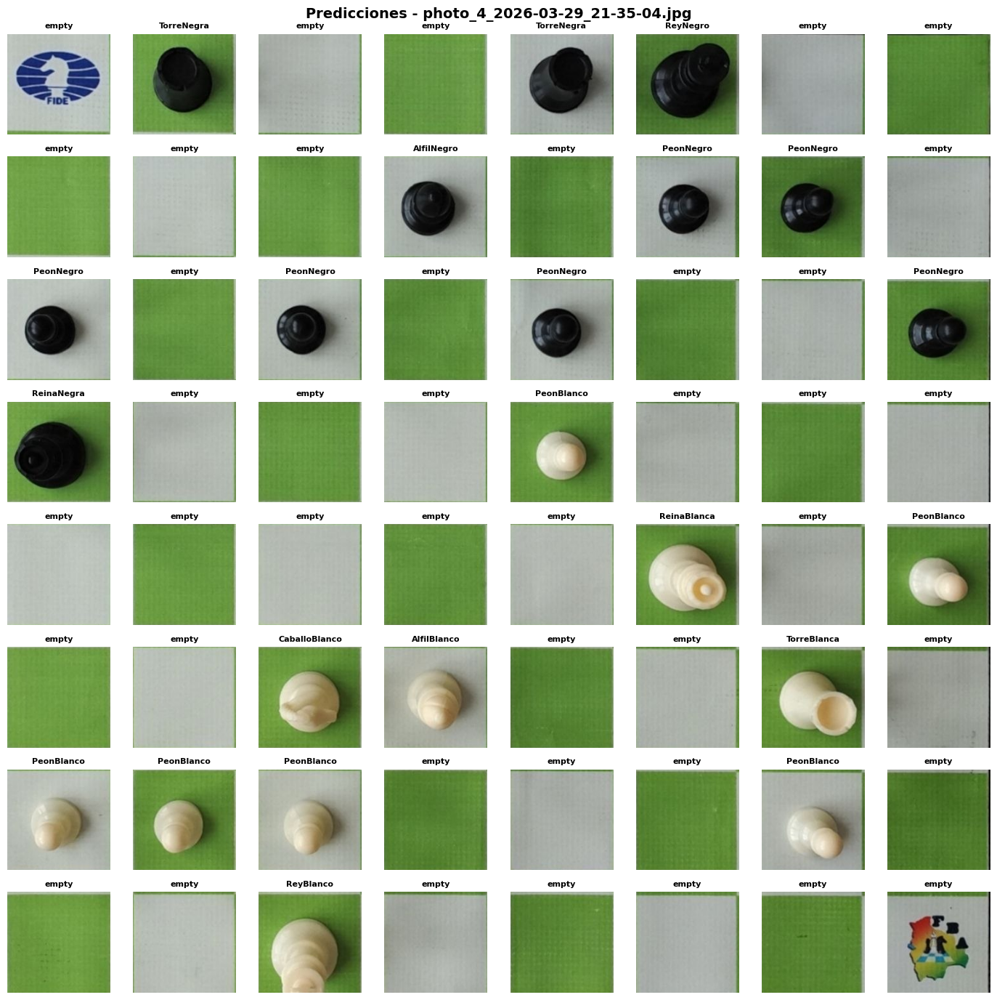


Imagen 40/51: photo_4_2026-03-29_21-35-04.jpg
Coordenadas detectadas: (0, 0) a (1280, 1257)
Tablero de predicciones (fila por fila):
Fila 0: ['empty', 'TorreNegra', 'empty', 'empty', 'TorreNegra', 'ReyNegro', 'empty', 'empty']
Fila 1: ['empty', 'empty', 'empty', 'AlfilNegro', 'empty', 'PeonNegro', 'PeonNegro', 'empty']
Fila 2: ['PeonNegro', 'empty', 'PeonNegro', 'empty', 'PeonNegro', 'empty', 'empty', 'PeonNegro']
Fila 3: ['ReinaNegra', 'empty', 'empty', 'empty', 'PeonBlanco', 'empty', 'empty', 'empty']
Fila 4: ['empty', 'empty', 'empty', 'empty', 'empty', 'ReinaBlanca', 'empty', 'PeonBlanco']
Fila 5: ['empty', 'empty', 'CaballoBlanco', 'AlfilBlanco', 'empty', 'empty', 'TorreBlanca', 'empty']
Fila 6: ['PeonBlanco', 'PeonBlanco', 'PeonBlanco', 'empty', 'empty', 'empty', 'PeonBlanco', 'empty']
Fila 7: ['empty', 'empty', 'ReyBlanco', 'empty', 'empty', 'empty', 'empty', 'empty']



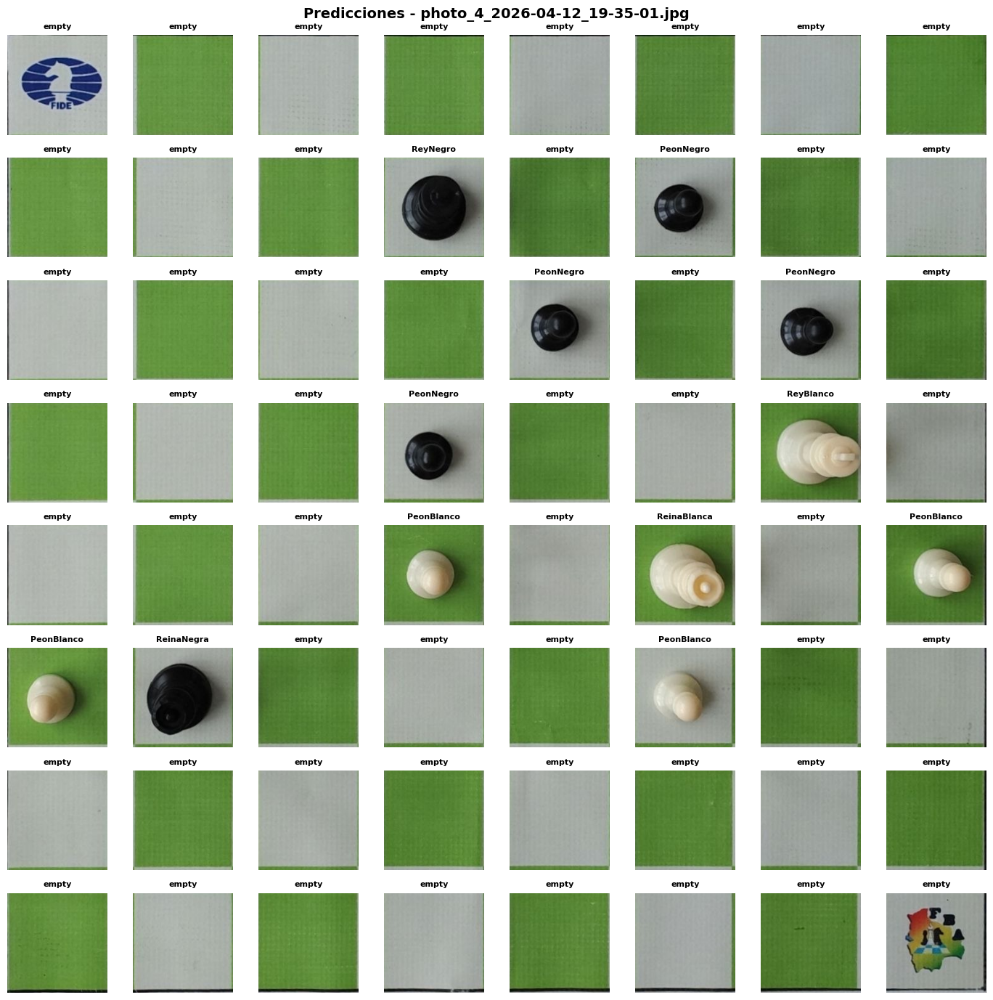


Imagen 41/51: photo_4_2026-04-12_19-35-01.jpg
Coordenadas detectadas: (0, 0) a (1280, 1280)
Tablero de predicciones (fila por fila):
Fila 0: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 1: ['empty', 'empty', 'empty', 'ReyNegro', 'empty', 'PeonNegro', 'empty', 'empty']
Fila 2: ['empty', 'empty', 'empty', 'empty', 'PeonNegro', 'empty', 'PeonNegro', 'empty']
Fila 3: ['empty', 'empty', 'empty', 'PeonNegro', 'empty', 'empty', 'ReyBlanco', 'empty']
Fila 4: ['empty', 'empty', 'empty', 'PeonBlanco', 'empty', 'ReinaBlanca', 'empty', 'PeonBlanco']
Fila 5: ['PeonBlanco', 'ReinaNegra', 'empty', 'empty', 'empty', 'PeonBlanco', 'empty', 'empty']
Fila 6: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 7: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']



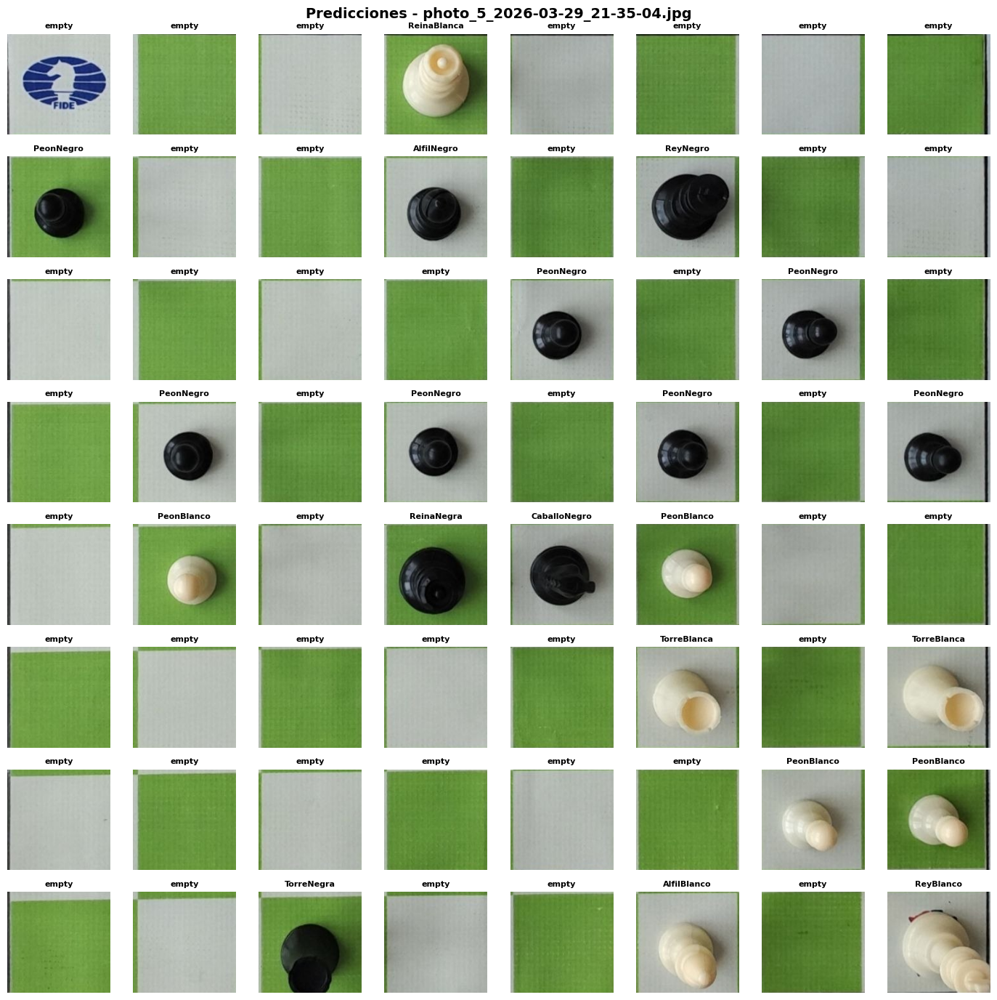


Imagen 42/51: photo_5_2026-03-29_21-35-04.jpg
Coordenadas detectadas: (0, 0) a (1280, 1262)
Tablero de predicciones (fila por fila):
Fila 0: ['empty', 'empty', 'empty', 'ReinaBlanca', 'empty', 'empty', 'empty', 'empty']
Fila 1: ['PeonNegro', 'empty', 'empty', 'AlfilNegro', 'empty', 'ReyNegro', 'empty', 'empty']
Fila 2: ['empty', 'empty', 'empty', 'empty', 'PeonNegro', 'empty', 'PeonNegro', 'empty']
Fila 3: ['empty', 'PeonNegro', 'empty', 'PeonNegro', 'empty', 'PeonNegro', 'empty', 'PeonNegro']
Fila 4: ['empty', 'PeonBlanco', 'empty', 'ReinaNegra', 'CaballoNegro', 'PeonBlanco', 'empty', 'empty']
Fila 5: ['empty', 'empty', 'empty', 'empty', 'empty', 'TorreBlanca', 'empty', 'TorreBlanca']
Fila 6: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'PeonBlanco', 'PeonBlanco']
Fila 7: ['empty', 'empty', 'TorreNegra', 'empty', 'empty', 'AlfilBlanco', 'empty', 'ReyBlanco']



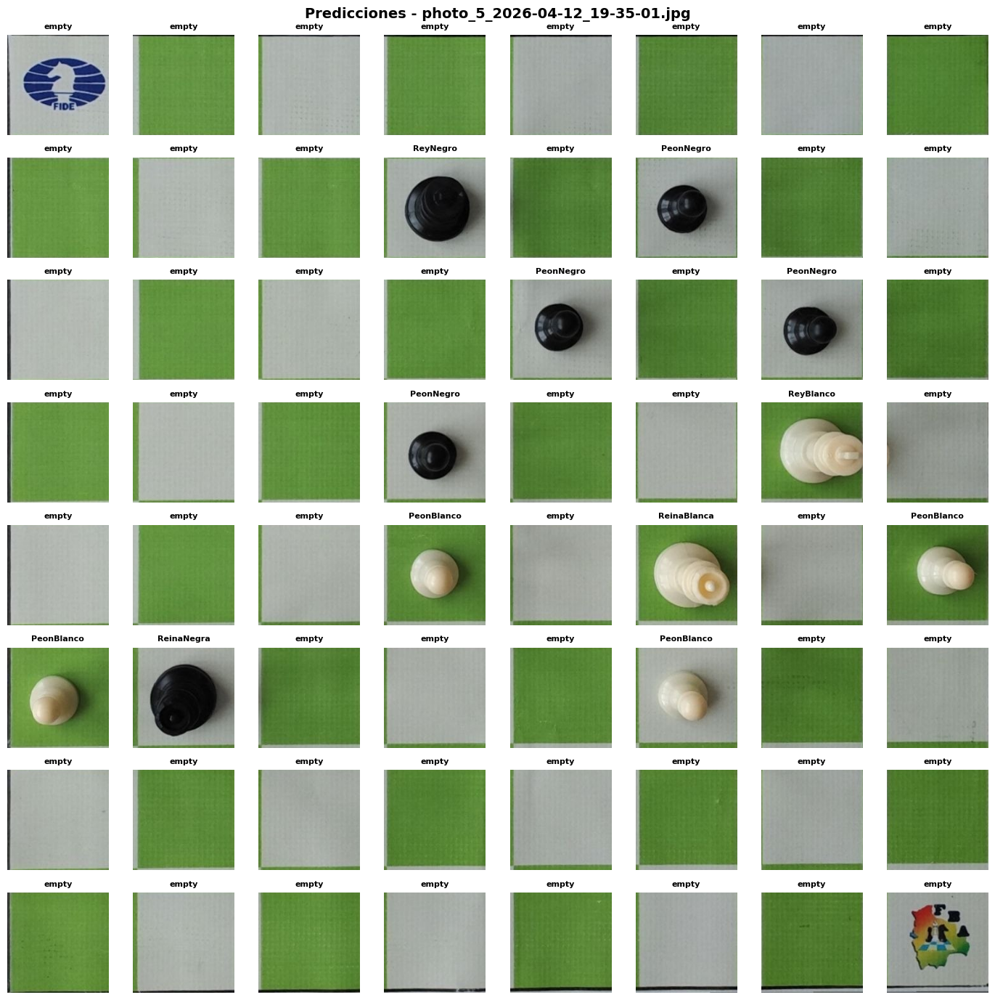


Imagen 43/51: photo_5_2026-04-12_19-35-01.jpg
Coordenadas detectadas: (0, 0) a (1280, 1264)
Tablero de predicciones (fila por fila):
Fila 0: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 1: ['empty', 'empty', 'empty', 'ReyNegro', 'empty', 'PeonNegro', 'empty', 'empty']
Fila 2: ['empty', 'empty', 'empty', 'empty', 'PeonNegro', 'empty', 'PeonNegro', 'empty']
Fila 3: ['empty', 'empty', 'empty', 'PeonNegro', 'empty', 'empty', 'ReyBlanco', 'empty']
Fila 4: ['empty', 'empty', 'empty', 'PeonBlanco', 'empty', 'ReinaBlanca', 'empty', 'PeonBlanco']
Fila 5: ['PeonBlanco', 'ReinaNegra', 'empty', 'empty', 'empty', 'PeonBlanco', 'empty', 'empty']
Fila 6: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 7: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']



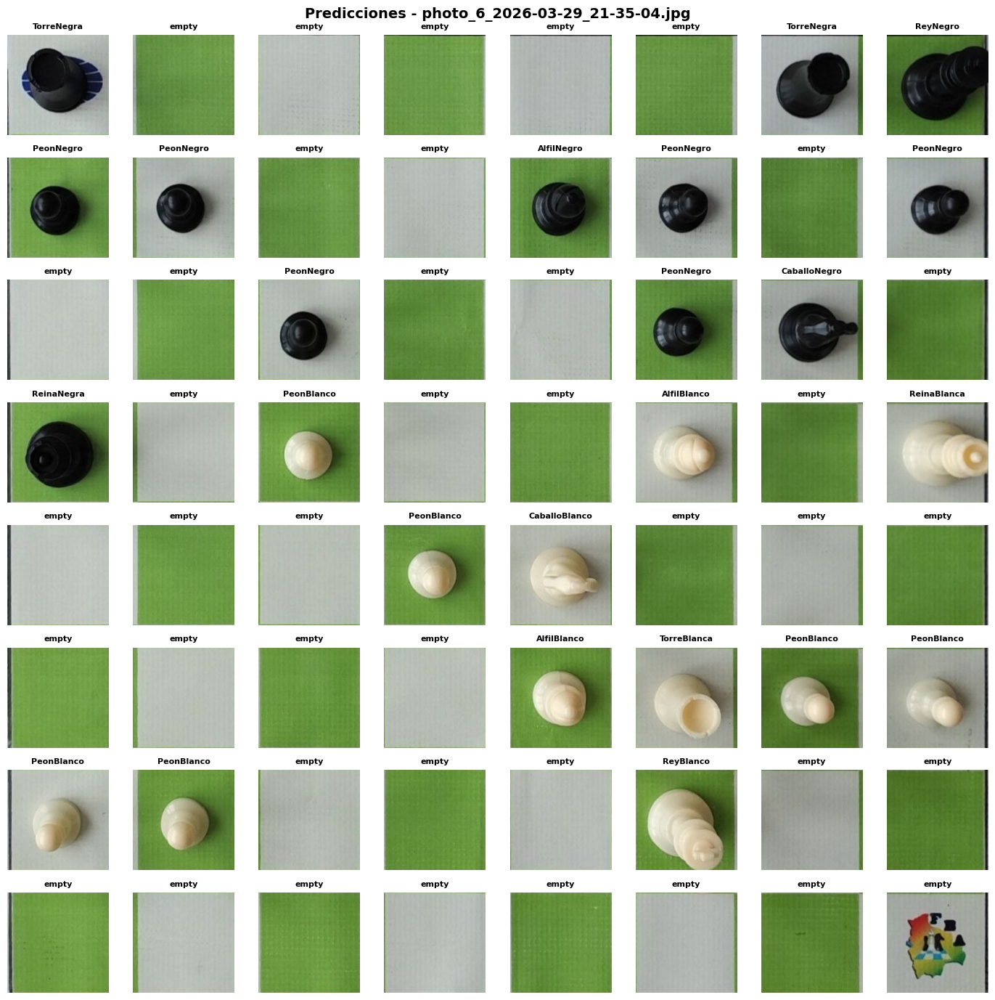


Imagen 44/51: photo_6_2026-03-29_21-35-04.jpg
Coordenadas detectadas: (0, 0) a (1280, 1266)
Tablero de predicciones (fila por fila):
Fila 0: ['TorreNegra', 'empty', 'empty', 'empty', 'empty', 'empty', 'TorreNegra', 'ReyNegro']
Fila 1: ['PeonNegro', 'PeonNegro', 'empty', 'empty', 'AlfilNegro', 'PeonNegro', 'empty', 'PeonNegro']
Fila 2: ['empty', 'empty', 'PeonNegro', 'empty', 'empty', 'PeonNegro', 'CaballoNegro', 'empty']
Fila 3: ['ReinaNegra', 'empty', 'PeonBlanco', 'empty', 'empty', 'AlfilBlanco', 'empty', 'ReinaBlanca']
Fila 4: ['empty', 'empty', 'empty', 'PeonBlanco', 'CaballoBlanco', 'empty', 'empty', 'empty']
Fila 5: ['empty', 'empty', 'empty', 'empty', 'AlfilBlanco', 'TorreBlanca', 'PeonBlanco', 'PeonBlanco']
Fila 6: ['PeonBlanco', 'PeonBlanco', 'empty', 'empty', 'empty', 'ReyBlanco', 'empty', 'empty']
Fila 7: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']



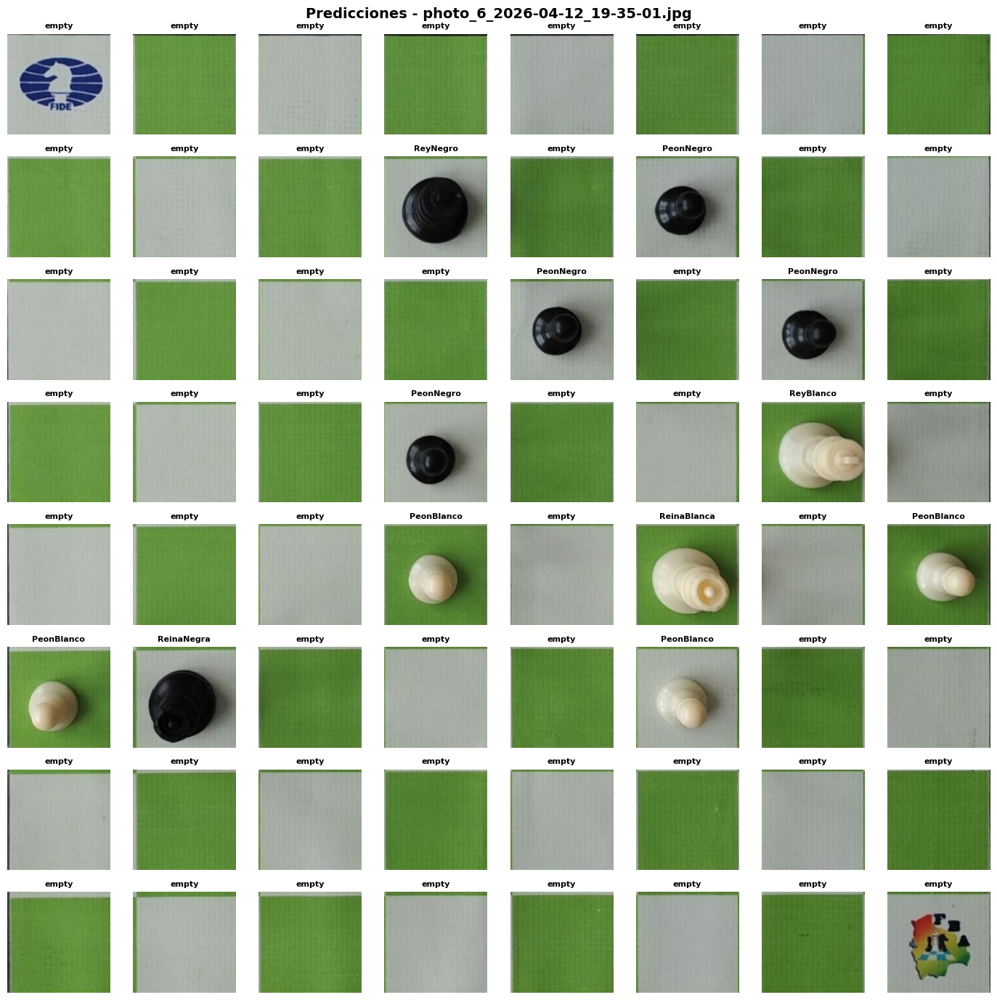


Imagen 45/51: photo_6_2026-04-12_19-35-01.jpg
Coordenadas detectadas: (0, 0) a (1280, 1263)
Tablero de predicciones (fila por fila):
Fila 0: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 1: ['empty', 'empty', 'empty', 'ReyNegro', 'empty', 'PeonNegro', 'empty', 'empty']
Fila 2: ['empty', 'empty', 'empty', 'empty', 'PeonNegro', 'empty', 'PeonNegro', 'empty']
Fila 3: ['empty', 'empty', 'empty', 'PeonNegro', 'empty', 'empty', 'ReyBlanco', 'empty']
Fila 4: ['empty', 'empty', 'empty', 'PeonBlanco', 'empty', 'ReinaBlanca', 'empty', 'PeonBlanco']
Fila 5: ['PeonBlanco', 'ReinaNegra', 'empty', 'empty', 'empty', 'PeonBlanco', 'empty', 'empty']
Fila 6: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 7: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']



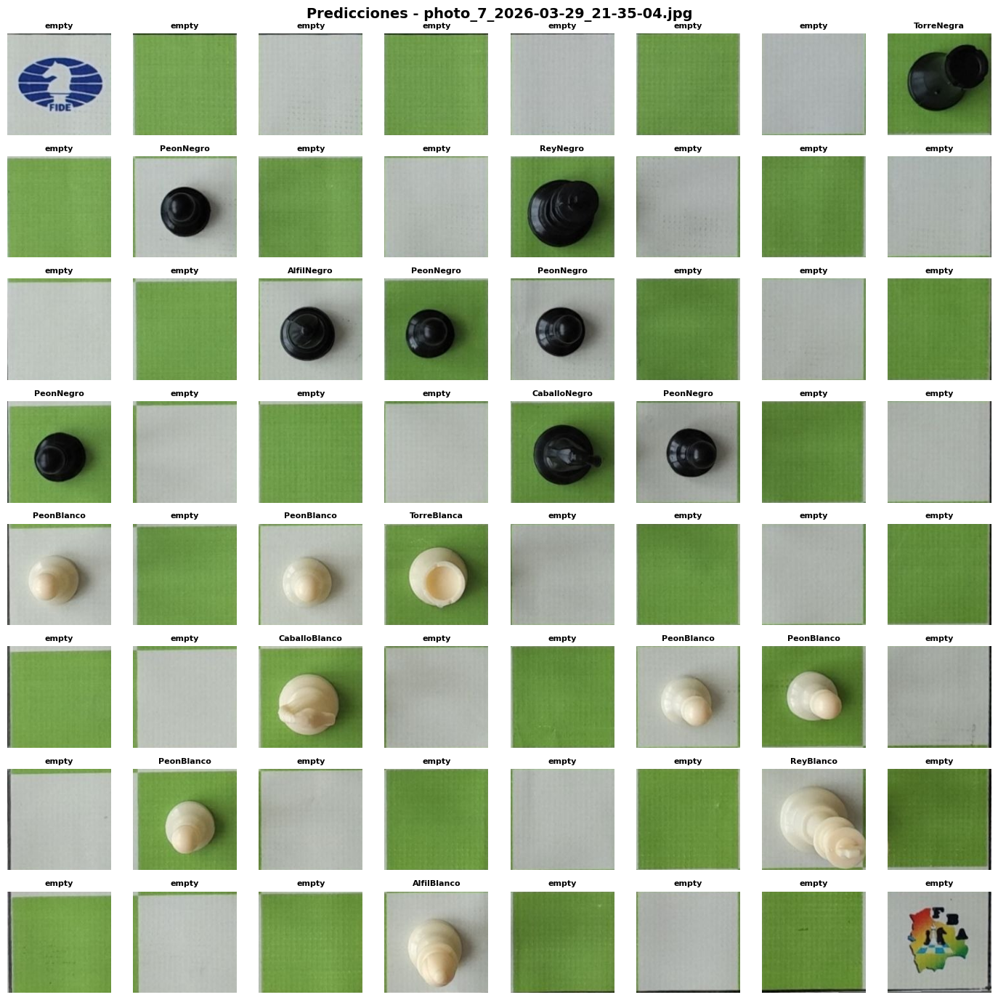


Imagen 46/51: photo_7_2026-03-29_21-35-04.jpg
Coordenadas detectadas: (0, 0) a (1280, 1253)
Tablero de predicciones (fila por fila):
Fila 0: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'TorreNegra']
Fila 1: ['empty', 'PeonNegro', 'empty', 'empty', 'ReyNegro', 'empty', 'empty', 'empty']
Fila 2: ['empty', 'empty', 'AlfilNegro', 'PeonNegro', 'PeonNegro', 'empty', 'empty', 'empty']
Fila 3: ['PeonNegro', 'empty', 'empty', 'empty', 'CaballoNegro', 'PeonNegro', 'empty', 'empty']
Fila 4: ['PeonBlanco', 'empty', 'PeonBlanco', 'TorreBlanca', 'empty', 'empty', 'empty', 'empty']
Fila 5: ['empty', 'empty', 'CaballoBlanco', 'empty', 'empty', 'PeonBlanco', 'PeonBlanco', 'empty']
Fila 6: ['empty', 'PeonBlanco', 'empty', 'empty', 'empty', 'empty', 'ReyBlanco', 'empty']
Fila 7: ['empty', 'empty', 'empty', 'AlfilBlanco', 'empty', 'empty', 'empty', 'empty']



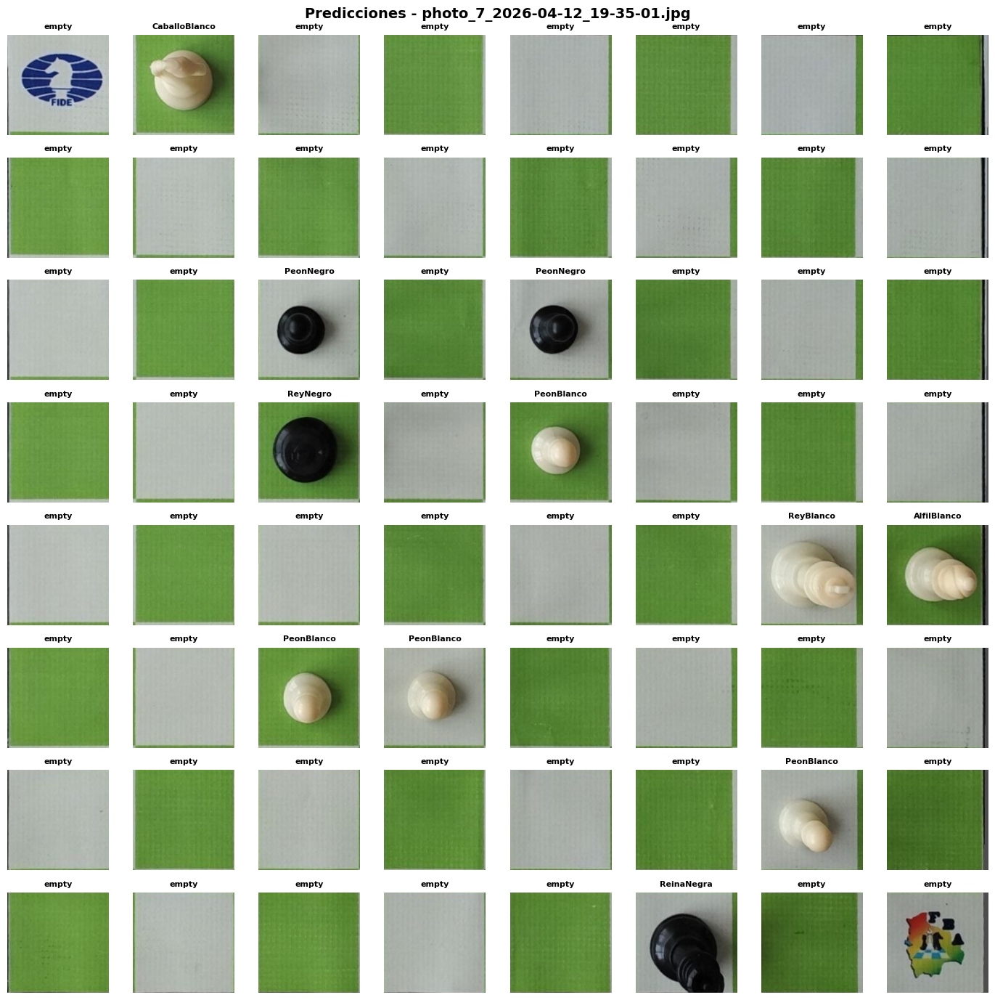


Imagen 47/51: photo_7_2026-04-12_19-35-01.jpg
Coordenadas detectadas: (0, 0) a (1280, 1269)
Tablero de predicciones (fila por fila):
Fila 0: ['empty', 'CaballoBlanco', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 1: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 2: ['empty', 'empty', 'PeonNegro', 'empty', 'PeonNegro', 'empty', 'empty', 'empty']
Fila 3: ['empty', 'empty', 'ReyNegro', 'empty', 'PeonBlanco', 'empty', 'empty', 'empty']
Fila 4: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'ReyBlanco', 'AlfilBlanco']
Fila 5: ['empty', 'empty', 'PeonBlanco', 'PeonBlanco', 'empty', 'empty', 'empty', 'empty']
Fila 6: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'PeonBlanco', 'empty']
Fila 7: ['empty', 'empty', 'empty', 'empty', 'empty', 'ReinaNegra', 'empty', 'empty']



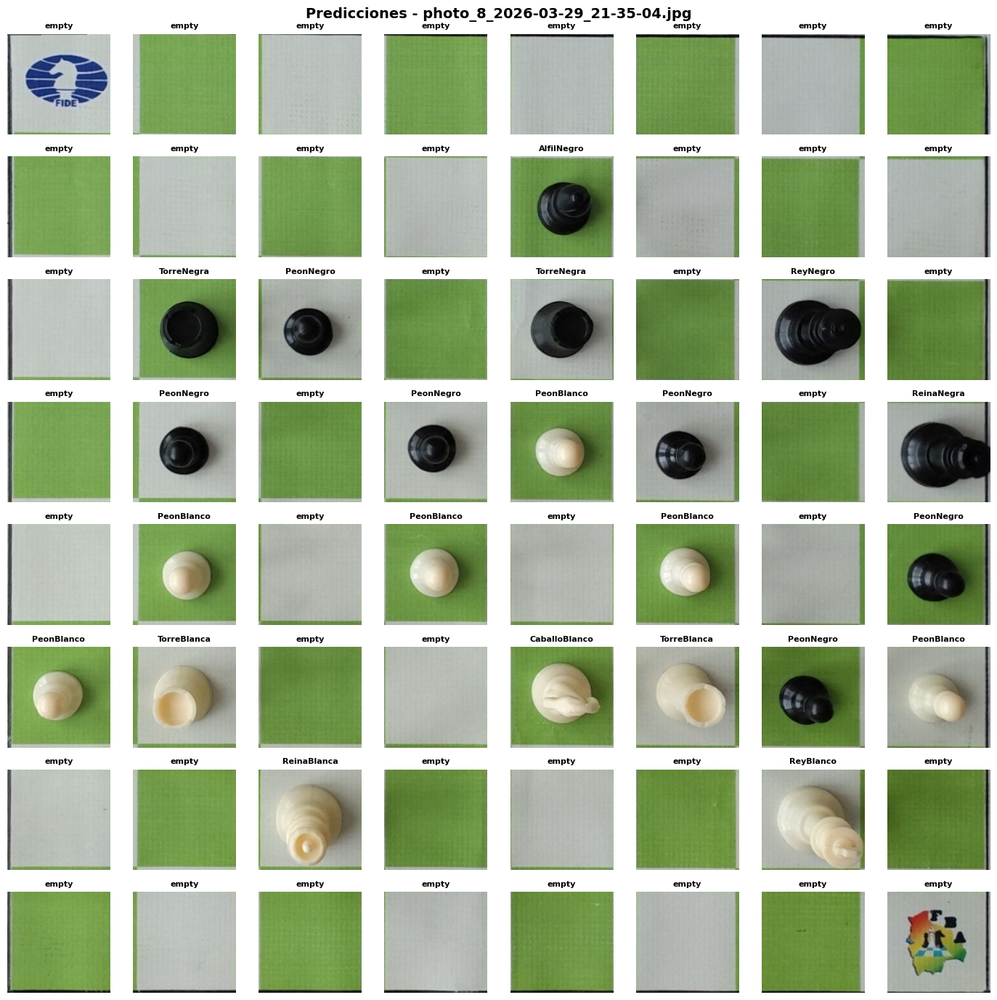


Imagen 48/51: photo_8_2026-03-29_21-35-04.jpg
Coordenadas detectadas: (0, 0) a (1280, 1256)
Tablero de predicciones (fila por fila):
Fila 0: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']
Fila 1: ['empty', 'empty', 'empty', 'empty', 'AlfilNegro', 'empty', 'empty', 'empty']
Fila 2: ['empty', 'TorreNegra', 'PeonNegro', 'empty', 'TorreNegra', 'empty', 'ReyNegro', 'empty']
Fila 3: ['empty', 'PeonNegro', 'empty', 'PeonNegro', 'PeonBlanco', 'PeonNegro', 'empty', 'ReinaNegra']
Fila 4: ['empty', 'PeonBlanco', 'empty', 'PeonBlanco', 'empty', 'PeonBlanco', 'empty', 'PeonNegro']
Fila 5: ['PeonBlanco', 'TorreBlanca', 'empty', 'empty', 'CaballoBlanco', 'TorreBlanca', 'PeonNegro', 'PeonBlanco']
Fila 6: ['empty', 'empty', 'ReinaBlanca', 'empty', 'empty', 'empty', 'ReyBlanco', 'empty']
Fila 7: ['empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty', 'empty']



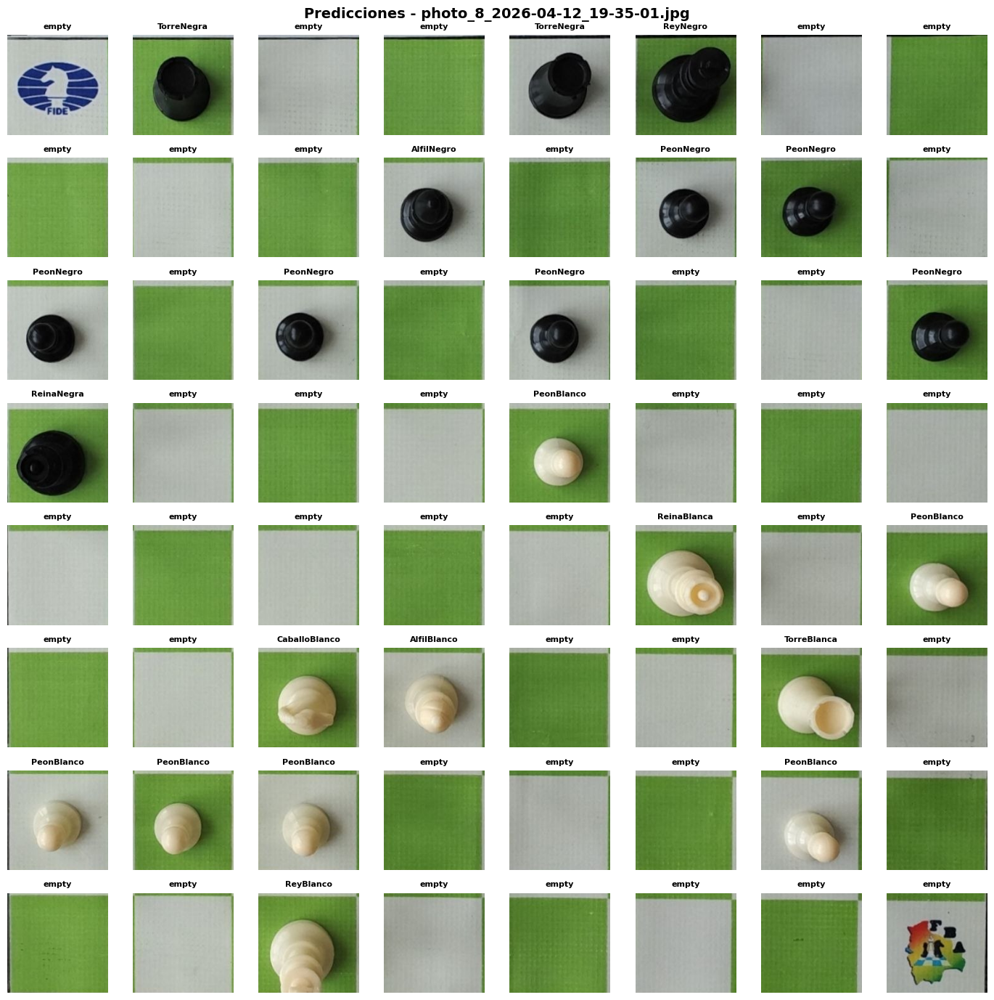


Imagen 49/51: photo_8_2026-04-12_19-35-01.jpg
Coordenadas detectadas: (0, 0) a (1280, 1278)
Tablero de predicciones (fila por fila):
Fila 0: ['empty', 'TorreNegra', 'empty', 'empty', 'TorreNegra', 'ReyNegro', 'empty', 'empty']
Fila 1: ['empty', 'empty', 'empty', 'AlfilNegro', 'empty', 'PeonNegro', 'PeonNegro', 'empty']
Fila 2: ['PeonNegro', 'empty', 'PeonNegro', 'empty', 'PeonNegro', 'empty', 'empty', 'PeonNegro']
Fila 3: ['ReinaNegra', 'empty', 'empty', 'empty', 'PeonBlanco', 'empty', 'empty', 'empty']
Fila 4: ['empty', 'empty', 'empty', 'empty', 'empty', 'ReinaBlanca', 'empty', 'PeonBlanco']
Fila 5: ['empty', 'empty', 'CaballoBlanco', 'AlfilBlanco', 'empty', 'empty', 'TorreBlanca', 'empty']
Fila 6: ['PeonBlanco', 'PeonBlanco', 'PeonBlanco', 'empty', 'empty', 'empty', 'PeonBlanco', 'empty']
Fila 7: ['empty', 'empty', 'ReyBlanco', 'empty', 'empty', 'empty', 'empty', 'empty']



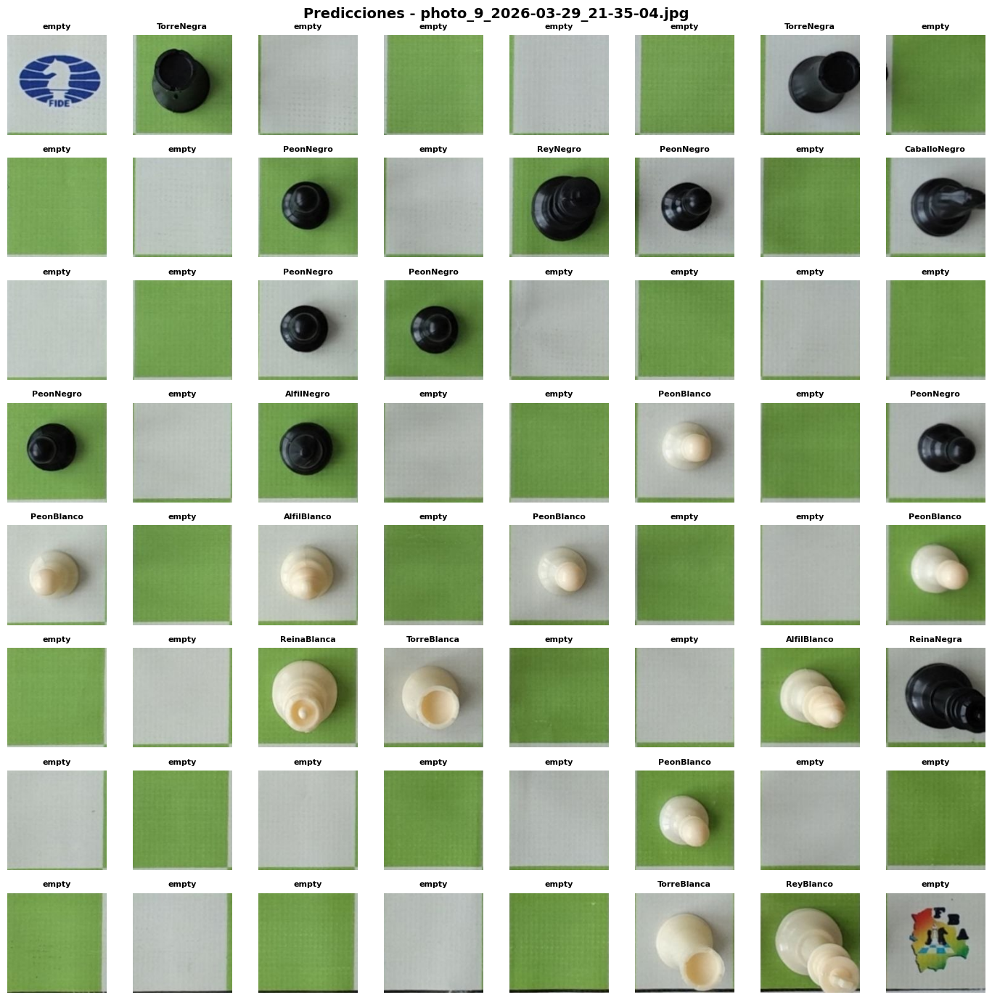


Imagen 50/51: photo_9_2026-03-29_21-35-04.jpg
Coordenadas detectadas: (0, 0) a (1278, 1280)
Tablero de predicciones (fila por fila):
Fila 0: ['empty', 'TorreNegra', 'empty', 'empty', 'empty', 'empty', 'TorreNegra', 'empty']
Fila 1: ['empty', 'empty', 'PeonNegro', 'empty', 'ReyNegro', 'PeonNegro', 'empty', 'CaballoNegro']
Fila 2: ['empty', 'empty', 'PeonNegro', 'PeonNegro', 'empty', 'empty', 'empty', 'empty']
Fila 3: ['PeonNegro', 'empty', 'AlfilNegro', 'empty', 'empty', 'PeonBlanco', 'empty', 'PeonNegro']
Fila 4: ['PeonBlanco', 'empty', 'AlfilBlanco', 'empty', 'PeonBlanco', 'empty', 'empty', 'PeonBlanco']
Fila 5: ['empty', 'empty', 'ReinaBlanca', 'TorreBlanca', 'empty', 'empty', 'AlfilBlanco', 'ReinaNegra']
Fila 6: ['empty', 'empty', 'empty', 'empty', 'empty', 'PeonBlanco', 'empty', 'empty']
Fila 7: ['empty', 'empty', 'empty', 'empty', 'empty', 'TorreBlanca', 'ReyBlanco', 'empty']



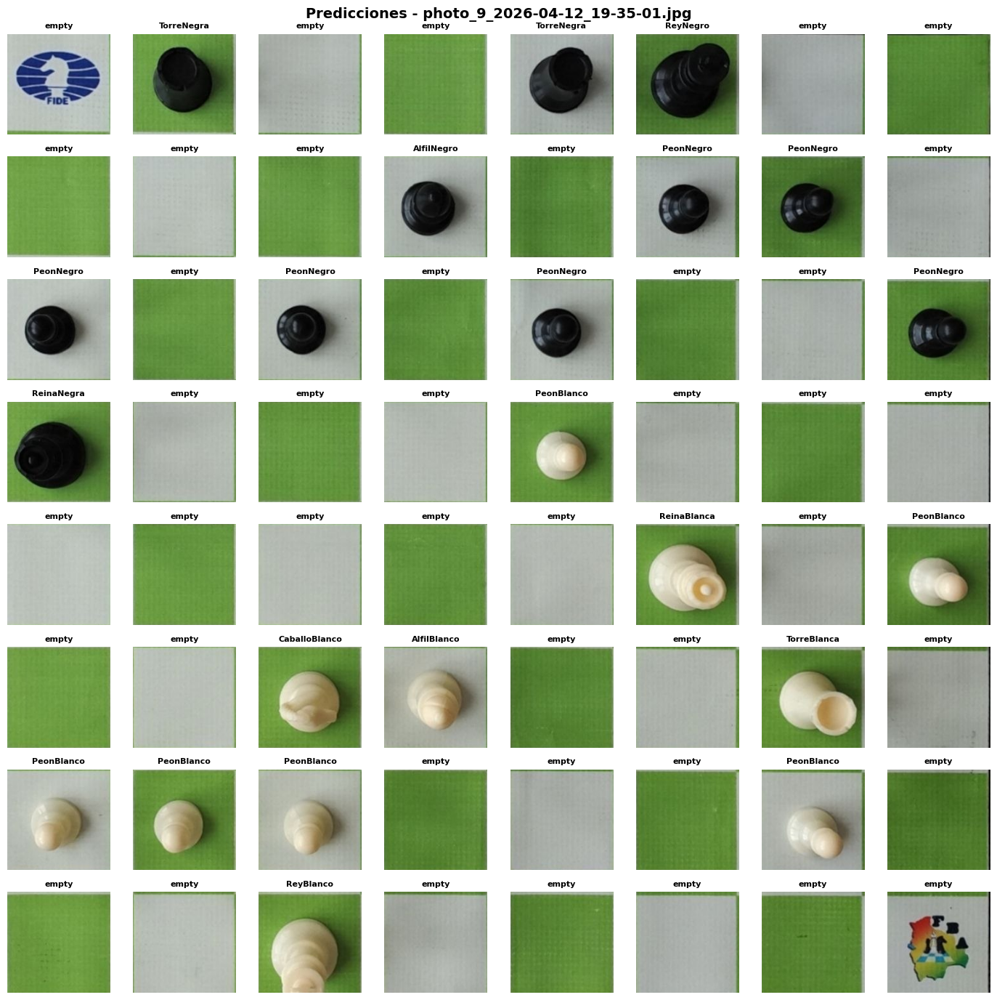


Imagen 51/51: photo_9_2026-04-12_19-35-01.jpg
Coordenadas detectadas: (0, 0) a (1280, 1257)
Tablero de predicciones (fila por fila):
Fila 0: ['empty', 'TorreNegra', 'empty', 'empty', 'TorreNegra', 'ReyNegro', 'empty', 'empty']
Fila 1: ['empty', 'empty', 'empty', 'AlfilNegro', 'empty', 'PeonNegro', 'PeonNegro', 'empty']
Fila 2: ['PeonNegro', 'empty', 'PeonNegro', 'empty', 'PeonNegro', 'empty', 'empty', 'PeonNegro']
Fila 3: ['ReinaNegra', 'empty', 'empty', 'empty', 'PeonBlanco', 'empty', 'empty', 'empty']
Fila 4: ['empty', 'empty', 'empty', 'empty', 'empty', 'ReinaBlanca', 'empty', 'PeonBlanco']
Fila 5: ['empty', 'empty', 'CaballoBlanco', 'AlfilBlanco', 'empty', 'empty', 'TorreBlanca', 'empty']
Fila 6: ['PeonBlanco', 'PeonBlanco', 'PeonBlanco', 'empty', 'empty', 'empty', 'PeonBlanco', 'empty']
Fila 7: ['empty', 'empty', 'ReyBlanco', 'empty', 'empty', 'empty', 'empty', 'empty']

Procesamiento completo


In [12]:
# Procesar todas las imágenes del directorio tablero_real
import matplotlib.pyplot as plt
import os

tablero_dir = "tablero_real"
imagenes = sorted([f for f in os.listdir(tablero_dir) if f.lower().endswith((".jpg", ".png", ".jpeg"))])

print(f"Procesando {len(imagenes)} imágenes...\n")

# Procesar cada imagen
for num_img, img_name in enumerate(imagenes):
    img_path = os.path.join(tablero_dir, img_name)
    img_bgr = cv2.imread(img_path)
    
    if img_bgr is None:
        print(f"No se pudo leer: {img_path}")
        continue
    
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    
    # Detectar tablero y casillas
    casillas, coords = detectar_tablero_y_casillas(img_rgb)
    x_inicio, y_inicio, x_fin, y_fin = coords
    
    if len(casillas) != 64:
        print(f"Error: se obtuvieron {len(casillas)} casillas en lugar de 64")
        continue
    
    # Predicciones
    predicciones = []
    fig, axes = plt.subplots(8, 8, figsize=(14, 14))
    
    for i in range(8):
        fila_pred = []
        for j in range(8):
            casilla_idx = i * 8 + j
            casilla = casillas[casilla_idx]
            
            # Redimensionar a 64x64
            casilla_resized = cv2.resize(casilla, (64, 64))
            
            # Normalizar y predecir
            casilla_tensor = torch.tensor(casilla_resized).permute(2, 0, 1).float() / 255
            casilla_tensor = casilla_tensor.unsqueeze(0).to(device)
            
            with torch.no_grad():
                output = model(casilla_tensor)
                pred_idx = torch.argmax(output, dim=1).item()
            
            pred_clase = train_data.classes[pred_idx]
            fila_pred.append(pred_clase)
            
            # Mostrar casilla con etiqueta
            ax = axes[i, j]
            ax.imshow(casilla)
            ax.set_title(pred_clase, fontsize=8, fontweight='bold')
            ax.axis('off')
        
        predicciones.append(fila_pred)
    
    plt.suptitle(f"Predicciones - {img_name}", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    # Imprimir tablero de estado
    print(f"\n{'='*80}")
    print(f"Imagen {num_img+1}/{len(imagenes)}: {img_name}")
    print(f"Coordenadas detectadas: ({x_inicio}, {y_inicio}) a ({x_fin}, {y_fin})")
    print("Tablero de predicciones (fila por fila):")
    for i, fila in enumerate(predicciones):
        print(f"Fila {i}: {fila}")
    print()

print("Procesamiento completo")

## Clasificacion en tiempo real

In [13]:
model.load_state_dict(torch.load("modelo_ajedrez.pth"))
model.eval()

ChessCNN(
  (conv): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=8192, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=13, bias=True)
  )
)

In [14]:
class_names = train_data.classes
print(class_names)

['AlfilBlanco', 'AlfilNegro', 'CaballoBlanco', 'CaballoNegro', 'PeonBlanco', 'PeonNegro', 'ReinaBlanca', 'ReinaNegra', 'ReyBlanco', 'ReyNegro', 'TorreBlanca', 'TorreNegra', 'empty']


In [15]:
def predecir_casilla(img):
    img = cv2.resize(img, (64,64))
    img = torch.tensor(img).permute(2,0,1).float()/255
    img = img.unsqueeze(0).to(device)
    
    with torch.no_grad():
        output = model(img)
        pred = torch.argmax(output, dim=1)
    
    return class_names[pred.item()]

In [ ]:
cap = cv2.VideoCapture(0)

while True:
    ret, frame = cap.read()
    
    if not ret:
        break
    
    # Recortar tablero
    tablero = frame[y_inicio:y_fin, x_inicio:x_fin]
    
    filas, columnas = 8, 8
    alto, ancho, _ = tablero.shape
    
    alto_c = alto // filas
    ancho_c = ancho // columnas
    
    tablero_estado = []
    
    for i in range(filas):
        fila = []
        for j in range(columnas):
            casilla = tablero[
                i*alto_c:(i+1)*alto_c,
                j*ancho_c:(j+1)*ancho_c
            ]
            
            pred = predecir_casilla(casilla)
            fila.append(pred)
        
        tablero_estado.append(fila)
    
    print(tablero_estado)
    
    cv2.imshow("Camara", frame)
    
    if cv2.waitKey(1) & 0xFF == 27:
        break

cap.release()
cv2.destroyAllWindows()

NameError: name 'y_inicio' is not defined